In [1]:
import os
if os.path.isdir('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')

In [2]:
# Install project dependencies

%pip install -q rdkit
%pip install -q pandas numpy scikit-learn matplotlib seaborn plotly datasets
%pip install -q torch torchvision torchaudio

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:
# ============================================
# Import Required Libraries
# ============================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem import AllChem

import torch
import torch.nn as nn
import torch.optim as optim

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import sys
import sklearn
import rdkit
import torch

print("Python version :", sys.version)
print("NumPy version  :", np.__version__)
print("Pandas version :", pd.__version__)
print("Scikit-learn   :", sklearn.__version__)
print("RDKit version  :", rdkit.__version__)
print("PyTorch version:", torch.__version__)

Python version : 3.12.3 (tags/v3.12.3:f6650f9, Apr  9 2024, 14:05:25) [MSC v.1938 64 bit (AMD64)]
NumPy version  : 2.5.3
Pandas version : 3.0.6
Scikit-learn   : 1.9.1
RDKit version  : 2026.09.1
PyTorch version: 2.14.1+cpu


In [5]:
# Test RDKit with ethanol

smiles = "CCO"
mol = Chem.MolFromSmiles(smiles)

print("SMILES:", smiles)
print("Molecule object:", mol)

SMILES: CCO
Molecule object: <rdkit.Chem.rdchem.Mol object at 0x0000021EF47E0660>


In [6]:
# Calculate basic molecular descriptors

molecular_weight = Descriptors.MolWt(mol)
logp = Descriptors.MolLogP(mol)
tpsa = Descriptors.TPSA(mol)
hbd = Descriptors.NumHDonors(mol)
hba = Descriptors.NumHAcceptors(mol)

print("Molecular Weight:", molecular_weight)
print("LogP:", logp)
print("TPSA:", tpsa)
print("H-Bond Donors:", hbd)
print("H-Bond Acceptors:", hba)

Molecular Weight: 46.069
LogP: -0.0014000000000000123
TPSA: 20.23
H-Bond Donors: 1
H-Bond Acceptors: 1


In [7]:
# Generate Morgan fingerprint

fingerprint = AllChem.GetMorganGenerator(
    radius=2,
    fpSize=2048
).GetFingerprint(mol)

print("Fingerprint size:", len(fingerprint))
print("Fingerprint:", fingerprint)

Fingerprint size: 2048
Fingerprint: <rdkit.DataStructs.cDataStructs.ExplicitBitVect object at 0x0000021EF47E0890>


In [8]:
# Test PyTorch

print("PyTorch version:", torch.__version__)

# Check whether GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Training device:", device)

PyTorch version: 2.14.1+cpu
Training device: cpu


Create project folders

In [9]:
import os

PROJECT_PATH = os.path.abspath(os.path.join(os.getcwd(), ".."))

folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "models",
    "results/figures",
    "results/metrics",
    "results/candidates",
    "src"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_PATH, folder), exist_ok=True)

print("Project folder created at:")
print(PROJECT_PATH)

Project folder created at:
c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery


In [10]:
PROJECT_PATH = os.path.abspath(os.path.join(os.getcwd(), ".."))

RAW_DATA_PATH = os.path.join(PROJECT_PATH, "data", "raw")
PROCESSED_DATA_PATH = os.path.join(PROJECT_PATH, "data", "processed")

os.makedirs(RAW_DATA_PATH, exist_ok=True)
os.makedirs(PROCESSED_DATA_PATH, exist_ok=True)

print("Project path:", PROJECT_PATH)
print("Raw data path:", RAW_DATA_PATH)
print("Processed data path:", PROCESSED_DATA_PATH)

Project path: c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery
Raw data path: c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\data\raw
Processed data path: c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\data\processed


Download the ESOL dataset

In [11]:
from datasets import load_dataset

# Load ESOL dataset from Hugging Face
ds = load_dataset("scikit-fingerprints/MoleculeNet_ESOL")
print(ds)

c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['SMILES', 'label'],
        num_rows: 1128
    })
})


In [12]:
# Convert the available split to a Pandas DataFrame

if "train" in ds:
    df = ds["train"].to_pandas()
else:
    first_split = list(ds.keys())[0]
    df = ds[first_split].to_pandas()

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1128, 2)


In [13]:
print("Columns:")
print(df.columns.tolist())

Columns:
['SMILES', 'label']


In [14]:
df.head()

,SMILES,label
0,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77
1,Cc1occc1C(=O)Nc2ccccc2,-3.30
2,CC(C)=CCCC(C)=CC(=O),-2.06
3,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87
4,c1ccsc1,-1.33


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1128 entries, 0 to 1127
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SMILES  1128 non-null   str    
 1   label   1128 non-null   float64
dtypes: float64(1), str(1)
memory usage: 42.6 KB


In [16]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1128
Number of columns: 2


In [17]:
df.describe(include="all")

,SMILES,label
count,1128,1128.000000
unique,1128,NaN
top,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,NaN
freq,1,NaN
mean,NaN,-3.050102
std,NaN,2.096441
min,NaN,-11.600000
25%,NaN,-4.317500
50%,NaN,-2.860000
75%,NaN,-1.600000


In [18]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
SMILES    0
label     0
dtype: int64


In [19]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [20]:
smiles_candidates = [
    col for col in df.columns
    if "smiles" in col.lower()
]

print("Possible SMILES columns:", smiles_candidates)

Possible SMILES columns: ['SMILES']


In [21]:
print(f"Total molecules: {len(df):,}")

Total molecules: 1,128


In [22]:
df.sample(5, random_state=42)

,SMILES,label
1091,CC/C=C\C,-2.540
898,O=C1NC(=O)NC(=O)C1(CC)CC=C(C)C,-2.253
739,Cc1[nH]c(=O)n(c(=O)c1Cl)C(C)(C)C,-2.484
140,CC/C=C/C,-2.540
1019,ClC(Cl)C(c1ccc(Cl)cc1)c2ccc(Cl)cc2,-7.200


In [23]:
from rdkit import Chem

smiles_column = smiles_candidates[0]

def validate_smiles(smiles):
    try:
        mol = Chem.MolFromSmiles(smiles)
        return mol is not None
    except:
        return False

df["valid_smiles"] = df[smiles_column].apply(validate_smiles)

print(df["valid_smiles"].value_counts())

valid_smiles
True    1128
Name: count, dtype: int64


In [24]:
invalid_count = (~df["valid_smiles"]).sum()
print("Invalid molecules:", invalid_count)

Invalid molecules: 0


In [25]:
print(df["label"].describe())

count    1128.000000
mean       -3.050102
std         2.096441
min       -11.600000
25%        -4.317500
50%        -2.860000
75%        -1.600000
max         1.580000
Name: label, dtype: float64


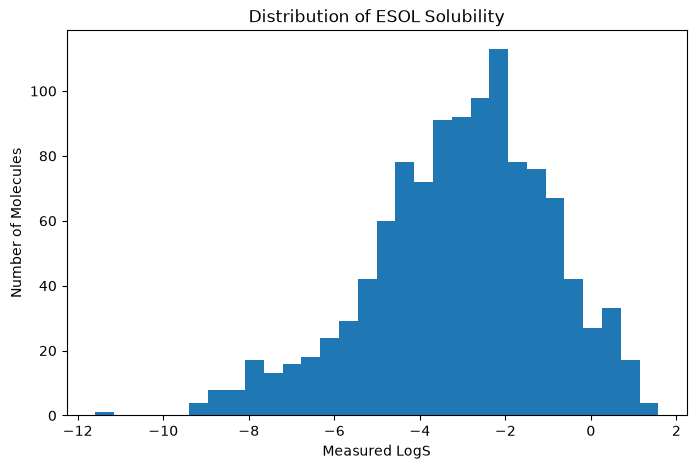

In [26]:
plt.figure(figsize=(8, 5))
plt.hist(df["label"], bins=30)
plt.xlabel("Measured LogS")
plt.ylabel("Number of Molecules")
plt.title("Distribution of ESOL Solubility")
plt.show()

SMILES: OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)C(O)C3O 


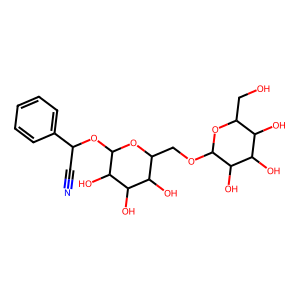

In [27]:
from rdkit.Chem import Draw

smiles = df["SMILES"].iloc[0]
mol = Chem.MolFromSmiles(smiles)
print("SMILES:", smiles)
display(Draw.MolToImage(mol))

Calculate molecular descriptors

In [28]:
def calculate_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return pd.Series({
            "MolecularWeight": None,
            "LogP": None,
            "TPSA": None,
            "HBD": None,
            "HBA": None,
            "RotatableBonds": None,
            "RingCount": None
        })

    return pd.Series({
        "MolecularWeight": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
        "HBD": Descriptors.NumHDonors(mol),
        "HBA": Descriptors.NumHAcceptors(mol),
        "RotatableBonds": Descriptors.NumRotatableBonds(mol),
        "RingCount": Descriptors.RingCount(mol)
    })

In [29]:
descriptor_df = df["SMILES"].apply(calculate_descriptors)

df_with_descriptors = pd.concat(
    [df, descriptor_df],
    axis=1
)

display(df_with_descriptors.head())

,SMILES,label,valid_smiles,MolecularWeight,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount
0,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77,True,457.432,-3.10802,202.32,7.0,12.0,7.0,3.0
1,Cc1occc1C(=O)Nc2ccccc2,-3.30,True,201.225,2.84032,42.24,1.0,2.0,2.0,2.0
2,CC(C)=CCCC(C)=CC(=O),-2.06,True,152.237,2.87800,17.07,0.0,1.0,4.0,0.0
3,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87,True,278.354,6.29940,0.00,0.0,0.0,0.0,5.0
4,c1ccsc1,-1.33,True,84.143,1.74810,0.00,0.0,1.0,0.0,1.0


In [30]:
df_with_descriptors.describe()

,label,MolecularWeight,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount
count,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000
mean,-3.050102,203.937074,2.447520,34.872881,0.701241,2.069149,2.177305,1.390957
std,2.096441,102.738077,1.852875,35.383593,1.089727,2.109388,2.640974,1.318286
min,-11.600000,16.043000,-7.571400,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-4.317500,121.183000,1.414900,0.000000,0.000000,0.000000,0.000000,0.000000
50%,-2.860000,182.179000,2.339000,26.300000,0.000000,2.000000,1.000000,1.000000
75%,-1.600000,270.372000,3.402200,55.440000,1.000000,3.000000,3.000000,2.000000
max,1.580000,780.949000,10.388600,268.680000,11.000000,16.000000,23.000000,8.000000


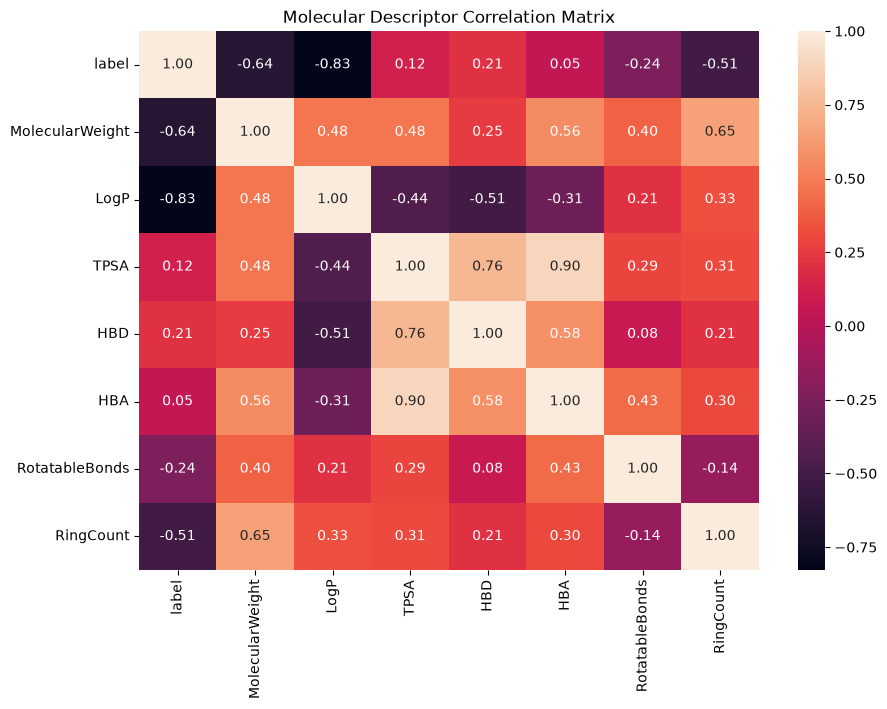

In [31]:
numeric_columns = [
    "label",
    "MolecularWeight",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "RotatableBonds",
    "RingCount"
]

correlation_matrix = df_with_descriptors[numeric_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Molecular Descriptor Correlation Matrix")

plt.show()

In [32]:
PROJECT_PATH = os.path.abspath(os.path.join(os.getcwd(), ".."))

RAW_DATA_PATH = os.path.join(
    PROJECT_PATH,
    "data",
    "raw"
)

os.makedirs(RAW_DATA_PATH, exist_ok=True)

raw_file = os.path.join(
    RAW_DATA_PATH,
    "MoleculeNet_ESOL_raw.csv"
)

df.to_csv(raw_file, index=False)

print("Raw dataset saved:")
print(raw_file)

Raw dataset saved:
c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\data\raw\MoleculeNet_ESOL_raw.csv


In [33]:
PROCESSED_DATA_PATH = os.path.join(
    PROJECT_PATH,
    "data",
    "processed"
)

os.makedirs(PROCESSED_DATA_PATH, exist_ok=True)

descriptor_file = os.path.join(
    PROCESSED_DATA_PATH,
    "ESOL_with_descriptors.csv"
)

df_with_descriptors.to_csv(
    descriptor_file,
    index=False
)

print("Descriptor dataset saved:")
print(descriptor_file)

Descriptor dataset saved:
c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\data\processed\ESOL_with_descriptors.csv


## Data Cleaning & Molecular Feature Engineering.

In [34]:
PROJECT_PATH = os.path.abspath(os.path.join(os.getcwd(), ".."))

PROCESSED_DATA_PATH = os.path.join(
    PROJECT_PATH,
    "data",
    "processed"
)

os.makedirs(PROCESSED_DATA_PATH, exist_ok=True)

input_file = os.path.join(
    PROCESSED_DATA_PATH,
    "ESOL_with_descriptors.csv"
)

df = pd.read_csv(input_file)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset shape: (1128, 10)

Columns:
['SMILES', 'label', 'valid_smiles', 'MolecularWeight', 'LogP', 'TPSA', 'HBD', 'HBA', 'RotatableBonds', 'RingCount']


,SMILES,label,valid_smiles,MolecularWeight,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount
0,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77,True,457.432,-3.10802,202.32,7.0,12.0,7.0,3.0
1,Cc1occc1C(=O)Nc2ccccc2,-3.30,True,201.225,2.84032,42.24,1.0,2.0,2.0,2.0
2,CC(C)=CCCC(C)=CC(=O),-2.06,True,152.237,2.87800,17.07,0.0,1.0,4.0,0.0
3,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87,True,278.354,6.29940,0.00,0.0,0.0,0.0,5.0
4,c1ccsc1,-1.33,True,84.143,1.74810,0.00,0.0,1.0,0.0,1.0


In [35]:
# rename label

df = df.rename(columns={"label": "logS"})
print(df.columns.tolist())

['SMILES', 'logS', 'valid_smiles', 'MolecularWeight', 'LogP', 'TPSA', 'HBD', 'HBA', 'RotatableBonds', 'RingCount']


In [36]:
before = len(df)
df = df[df["valid_smiles"] == True].copy()
after = len(df)

print("Rows before cleaning:", before)
print("Rows after removing invalid SMILES:", after)
print("Removed:", before - after)

Rows before cleaning: 1128
Rows after removing invalid SMILES: 1128
Removed: 0


Create canonical SMILES

In [37]:
def canonicalize_smiles(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    return Chem.MolToSmiles(mol, canonical=True)

df["canonical_smiles"] = df["SMILES"].apply(canonicalize_smiles)
df[["SMILES", "canonical_smiles"]].head(10)

,SMILES,canonical_smiles
0,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...
1,Cc1occc1C(=O)Nc2ccccc2,Cc1occc1C(=O)Nc1ccccc1
2,CC(C)=CCCC(C)=CC(=O),CC(C)=CCCC(C)=CC=O
3,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,c1ccc2c(c1)ccc1c2ccc2c3ccccc3ccc21
4,c1ccsc1,c1ccsc1
5,c2ccc1scnc1c2,c1ccc2scnc2c1
6,Clc1cc(Cl)c(c(Cl)c1)c2c(Cl)cccc2Cl,Clc1cc(Cl)c(-c2c(Cl)cccc2Cl)c(Cl)c1
7,CC12CCC3C(CCc4cc(O)ccc34)C2CCC1O,CC12CCC3c4ccc(O)cc4CCC3C1CCC2O
8,ClC4=C(Cl)C5(Cl)C3C1CC(C2OC12)C3C4(Cl)C5(Cl)Cl,ClC1=C(Cl)C2(Cl)C3C4CC(C5OC45)C3C1(Cl)C2(Cl)Cl
9,COc5cc4OCC3Oc2c1CC(Oc1ccc2C(=O)C3c4cc5OC)C(C)=C,C=C(C)C1Cc2c(ccc3c2OC2COc4cc(OC)c(OC)cc4C2C3=O)O1


In [38]:
duplicate_count = df["canonical_smiles"].duplicated().sum()
print("Duplicate molecular structures:", duplicate_count)

Duplicate molecular structures: 11


In [39]:
df = df.drop_duplicates(subset="canonical_smiles").copy()
print("Dataset shape after removing duplicate molecules:")
print(df.shape)

Dataset shape after removing duplicate molecules:
(1117, 11)


In [40]:
df = df.drop(columns=["valid_smiles"])
print(df.columns.tolist())

['SMILES', 'logS', 'MolecularWeight', 'LogP', 'TPSA', 'HBD', 'HBA', 'RotatableBonds', 'RingCount', 'canonical_smiles']


In [41]:
print(df.isnull().sum())

SMILES              0
logS                0
MolecularWeight     0
LogP                0
TPSA                0
HBD                 0
HBA                 0
RotatableBonds      0
RingCount           0
canonical_smiles    0
dtype: int64


In [42]:
def calculate_descriptors(smiles):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return pd.Series({
            "MolecularWeight": np.nan,
            "LogP": np.nan,
            "TPSA": np.nan,
            "HBD": np.nan,
            "HBA": np.nan,
            "RotatableBonds": np.nan,
            "RingCount": np.nan
        })

    return pd.Series({
        "MolecularWeight": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
        "HBD": Descriptors.NumHDonors(mol),
        "HBA": Descriptors.NumHAcceptors(mol),
        "RotatableBonds": Descriptors.NumRotatableBonds(mol),
        "RingCount": Descriptors.RingCount(mol)
    })

In [43]:
descriptor_df = df["canonical_smiles"].apply(calculate_descriptors)

df = pd.concat(
    [df.reset_index(drop=True), descriptor_df.reset_index(drop=True)], axis=1)
df.head()

,SMILES,logS,MolecularWeight,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount,canonical_smiles,MolecularWeight,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount
0,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77,457.432,-3.10802,202.32,7.0,12.0,7.0,3.0,N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,457.432,-3.10802,202.32,7.0,12.0,7.0,3.0
1,Cc1occc1C(=O)Nc2ccccc2,-3.30,201.225,2.84032,42.24,1.0,2.0,2.0,2.0,Cc1occc1C(=O)Nc1ccccc1,201.225,2.84032,42.24,1.0,2.0,2.0,2.0
2,CC(C)=CCCC(C)=CC(=O),-2.06,152.237,2.87800,17.07,0.0,1.0,4.0,0.0,CC(C)=CCCC(C)=CC=O,152.237,2.87800,17.07,0.0,1.0,4.0,0.0
3,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87,278.354,6.29940,0.00,0.0,0.0,0.0,5.0,c1ccc2c(c1)ccc1c2ccc2c3ccccc3ccc21,278.354,6.29940,0.00,0.0,0.0,0.0,5.0
4,c1ccsc1,-1.33,84.143,1.74810,0.00,0.0,1.0,0.0,1.0,c1ccsc1,84.143,1.74810,0.00,0.0,1.0,0.0,1.0


In [44]:
descriptor_columns = [
    "MolecularWeight",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "RotatableBonds",
    "RingCount"
]

df[descriptor_columns].describe()

,MolecularWeight,MolecularWeight,LogP,LogP,TPSA,TPSA,HBD,HBD,HBA,HBA,RotatableBonds,RotatableBonds,RingCount,RingCount
count,1117.000000,1117.000000,1117.000000,1117.000000,1117.000000,1117.000000,1117.000000,1117.000000,1117.000000,1117.000000,1117.000000,1117.000000,1117.000000,1117.000000
mean,203.707382,203.707382,2.453439,2.453439,34.714772,34.714772,0.694718,0.694718,2.062668,2.062668,2.173679,2.173679,1.387645,1.387645
std,102.944082,102.944082,1.845119,1.845119,35.328532,35.328532,1.080496,1.080496,2.109802,2.109802,2.643431,2.643431,1.320214,1.320214
min,16.043000,16.043000,-7.571400,-7.571400,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,120.623000,120.623000,1.417620,1.417620,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,182.172000,182.172000,2.339200,2.339200,26.020000,26.020000,0.000000,0.000000,2.000000,2.000000,1.000000,1.000000,1.000000,1.000000
75%,270.372000,270.372000,3.391800,3.391800,55.120000,55.120000,1.000000,1.000000,3.000000,3.000000,3.000000,3.000000,2.000000,2.000000
max,780.949000,780.949000,10.388600,10.388600,268.680000,268.680000,11.000000,11.000000,16.000000,16.000000,23.000000,23.000000,8.000000,8.000000


In [45]:
morgan_generator = AllChem.GetMorganGenerator(radius=2, fpSize=2048)

In [46]:
def generate_morgan_fingerprint(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    fingerprint = morgan_generator.GetFingerprint(mol)
    return np.array(fingerprint)

In [47]:
fingerprints = np.array([
    generate_morgan_fingerprint(smiles)
    for smiles in df["canonical_smiles"]
])

print("Fingerprint shape:", fingerprints.shape)

Fingerprint shape: (1117, 2048)


In [48]:
fingerprint_file = os.path.join(
    PROCESSED_DATA_PATH, "ESOL_morgan_fingerprints.npy")

np.save(
    fingerprint_file,
    fingerprints
)

print("Saved:", fingerprint_file)

Saved: c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\data\processed\ESOL_morgan_fingerprints.npy


In [49]:
clean_columns = [
    "SMILES",
    "canonical_smiles",
    "logS",
    "MolecularWeight",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "RotatableBonds",
    "RingCount"
]

df_clean = df[clean_columns].copy()

clean_file = os.path.join(
    PROCESSED_DATA_PATH,
    "ESOL_clean.csv"
)

df_clean.to_csv(
    clean_file,
    index=False
)

print("Saved:", clean_file)
print("Shape:", df_clean.shape)

Saved: c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\data\processed\ESOL_clean.csv
Shape: (1117, 17)


In [50]:
# Remove duplicated column names
df = df.loc[:, ~df.columns.duplicated()].copy()

print("Shape after removing duplicated columns:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

Shape after removing duplicated columns:
(1117, 10)

Columns:
['SMILES', 'logS', 'MolecularWeight', 'LogP', 'TPSA', 'HBD', 'HBA', 'RotatableBonds', 'RingCount', 'canonical_smiles']


In [51]:
clean_columns = [
    "SMILES",
    "canonical_smiles",
    "logS",
    "MolecularWeight",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "RotatableBonds",
    "RingCount"
]

df_clean = df[clean_columns].copy()

print("Final clean dataset shape:", df_clean.shape)
display(df_clean.head())

Final clean dataset shape: (1117, 10)


,SMILES,canonical_smiles,logS,MolecularWeight,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount
0,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.77,457.432,-3.10802,202.32,7.0,12.0,7.0,3.0
1,Cc1occc1C(=O)Nc2ccccc2,Cc1occc1C(=O)Nc1ccccc1,-3.30,201.225,2.84032,42.24,1.0,2.0,2.0,2.0
2,CC(C)=CCCC(C)=CC(=O),CC(C)=CCCC(C)=CC=O,-2.06,152.237,2.87800,17.07,0.0,1.0,4.0,0.0
3,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,c1ccc2c(c1)ccc1c2ccc2c3ccccc3ccc21,-7.87,278.354,6.29940,0.00,0.0,0.0,0.0,5.0
4,c1ccsc1,c1ccsc1,-1.33,84.143,1.74810,0.00,0.0,1.0,0.0,1.0


In [52]:
clean_file = os.path.join(
    PROCESSED_DATA_PATH,
    "ESOL_clean.csv"
)

df_clean.to_csv(
    clean_file,
    index=False
)

print("Final clean dataset saved to:")
print(clean_file)

Final clean dataset saved to:
c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\data\processed\ESOL_clean.csv


## Phase 4 — EDA & Molecular Data Visualization

In [53]:
import os

PROJECT_PATH = os.path.abspath(os.path.join(os.getcwd(), ".."))
PROCESSED_DATA_PATH = os.path.join(
    PROJECT_PATH,
    "data",
    "processed"
)

FIGURES_PATH = os.path.join(
    PROJECT_PATH,
    "results",
    "figures"
)

os.makedirs(FIGURES_PATH, exist_ok=True)

df = pd.read_csv(
    os.path.join(
        PROCESSED_DATA_PATH,
        "ESOL_clean.csv"
    )
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape:

 (1117, 10)


,SMILES,canonical_smiles,logS,MolecularWeight,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount
0,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.77,457.432,-3.10802,202.32,7.0,12.0,7.0,3.0
1,Cc1occc1C(=O)Nc2ccccc2,Cc1occc1C(=O)Nc1ccccc1,-3.30,201.225,2.84032,42.24,1.0,2.0,2.0,2.0
2,CC(C)=CCCC(C)=CC(=O),CC(C)=CCCC(C)=CC=O,-2.06,152.237,2.87800,17.07,0.0,1.0,4.0,0.0
3,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,c1ccc2c(c1)ccc1c2ccc2c3ccccc3ccc21,-7.87,278.354,6.29940,0.00,0.0,0.0,0.0,5.0
4,c1ccsc1,c1ccsc1,-1.33,84.143,1.74810,0.00,0.0,1.0,0.0,1.0


In [54]:
df.describe()

,logS,MolecularWeight,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount
count,1117.000000,1117.000000,1117.000000,1117.000000,1117.000000,1117.000000,1117.000000,1117.000000
mean,-3.050291,203.707382,2.453439,34.714772,0.694718,2.062668,2.173679,1.387645
std,2.094710,102.944082,1.845119,35.328532,1.080496,2.109802,2.643431,1.320214
min,-11.600000,16.043000,-7.571400,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-4.310000,120.623000,1.417620,0.000000,0.000000,0.000000,0.000000,0.000000
50%,-2.863000,182.172000,2.339200,26.020000,0.000000,2.000000,1.000000,1.000000
75%,-1.600000,270.372000,3.391800,55.120000,1.000000,3.000000,3.000000,2.000000
max,1.580000,780.949000,10.388600,268.680000,11.000000,16.000000,23.000000,8.000000


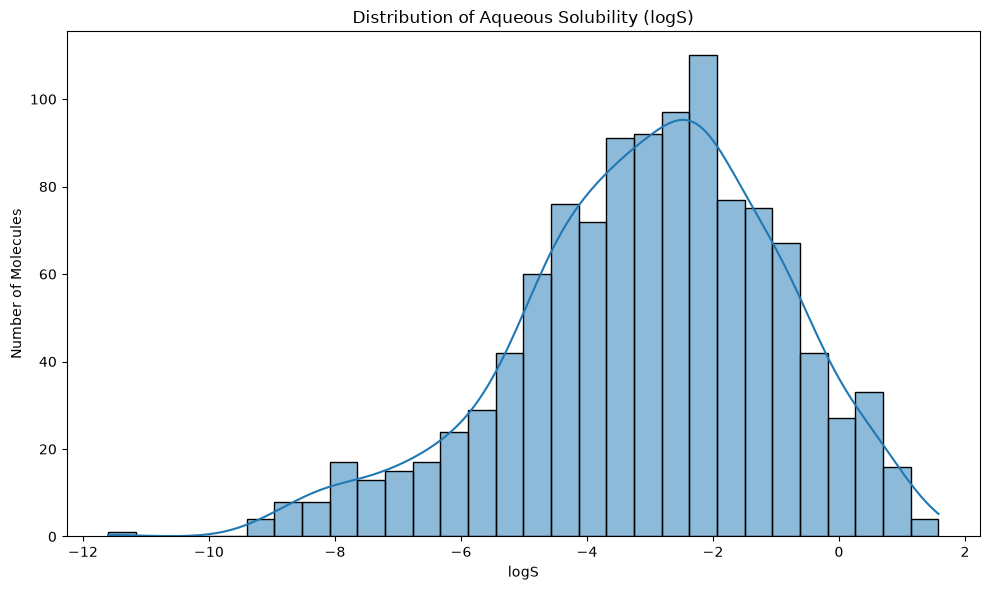

In [55]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["logS"], bins=30, kde=True)

plt.title("Distribution of Aqueous Solubility (logS)")
plt.xlabel("logS")
plt.ylabel("Number of Molecules")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_PATH,
        "01_logS_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [56]:
print("logS statistics:")
print(df["logS"].describe())

print("\nMedian logS:")
print(df["logS"].median())

print("\nStandard deviation:")
print(df["logS"].std())

logS statistics:
count    1117.000000
mean       -3.050291
std         2.094710
min       -11.600000
25%        -4.310000
50%        -2.863000
75%        -1.600000
max         1.580000
Name: logS, dtype: float64

Median logS:
-2.863

Standard deviation:
2.094710195958519


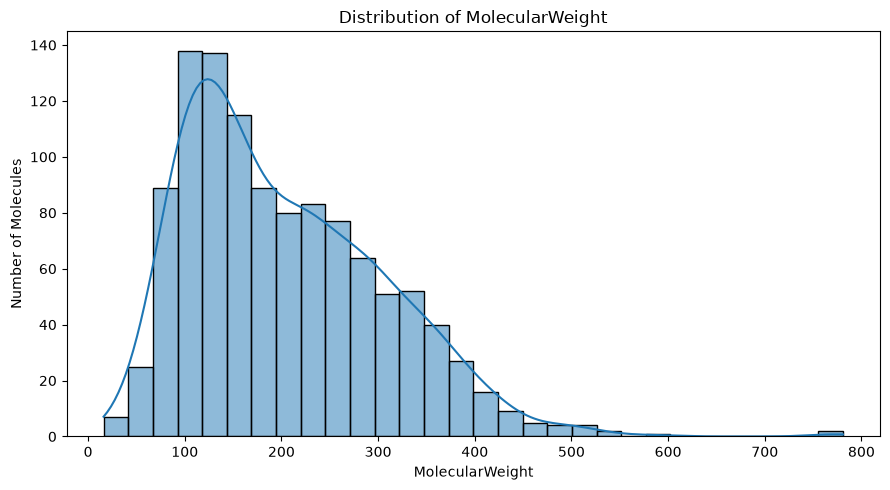

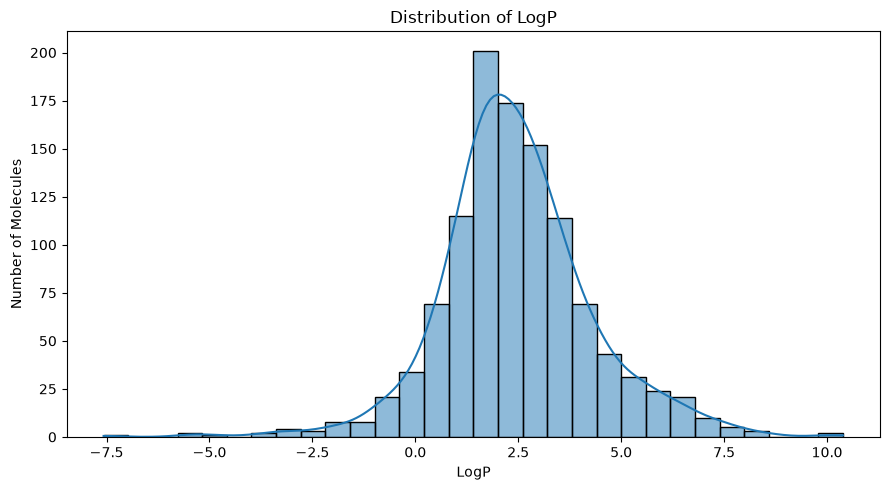

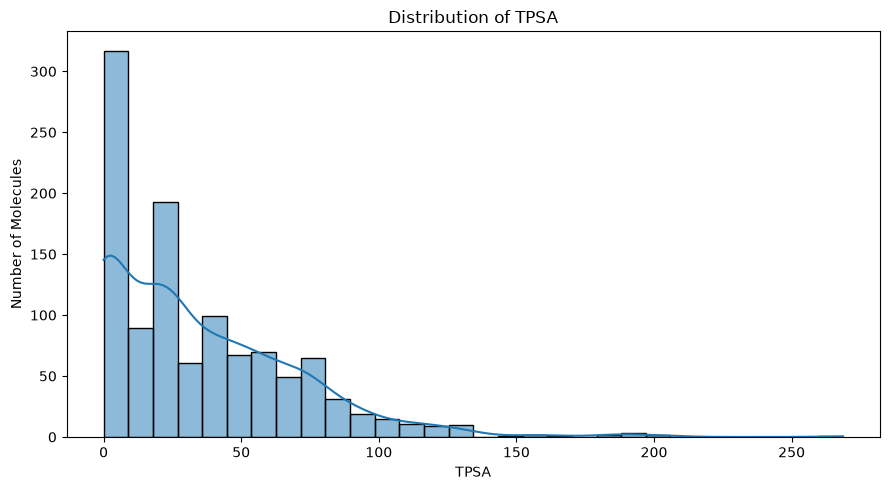

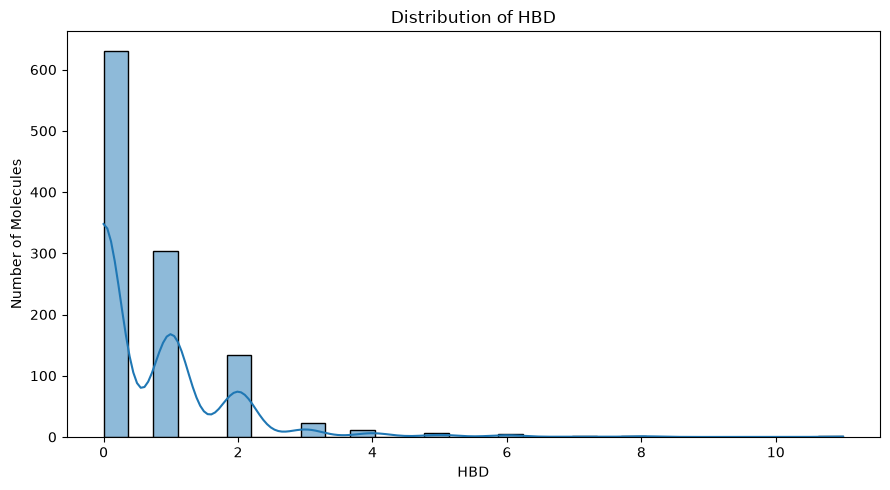

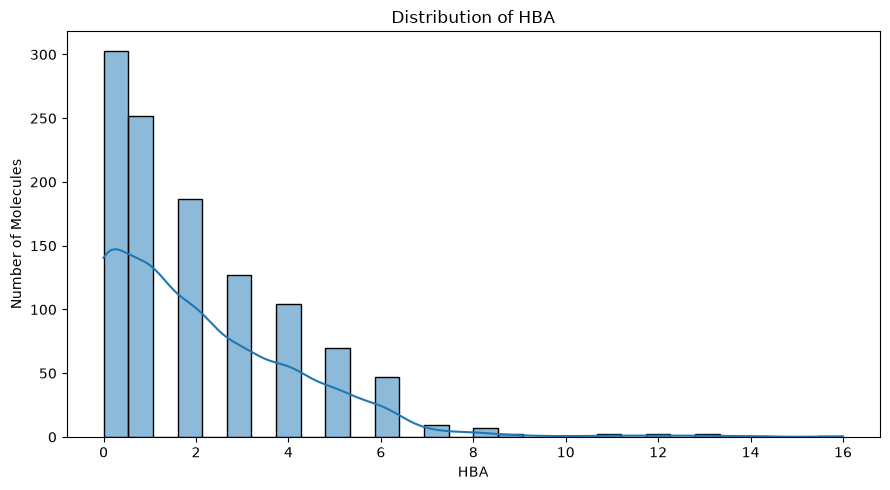

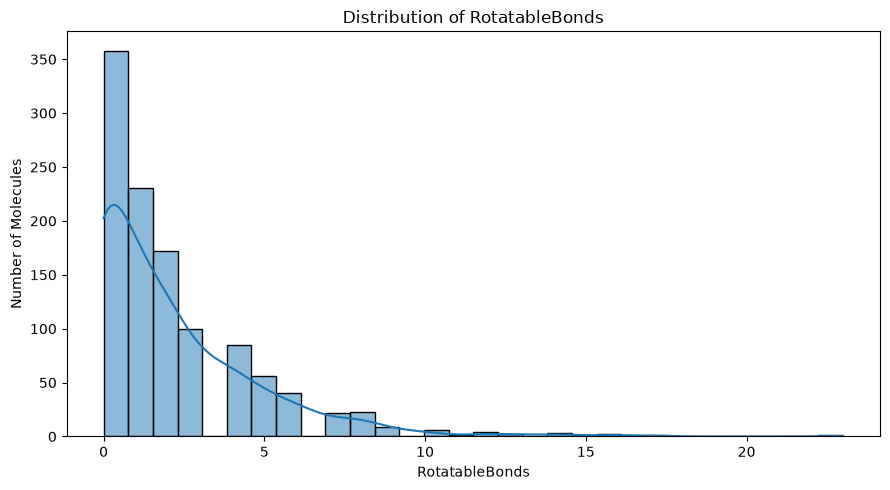

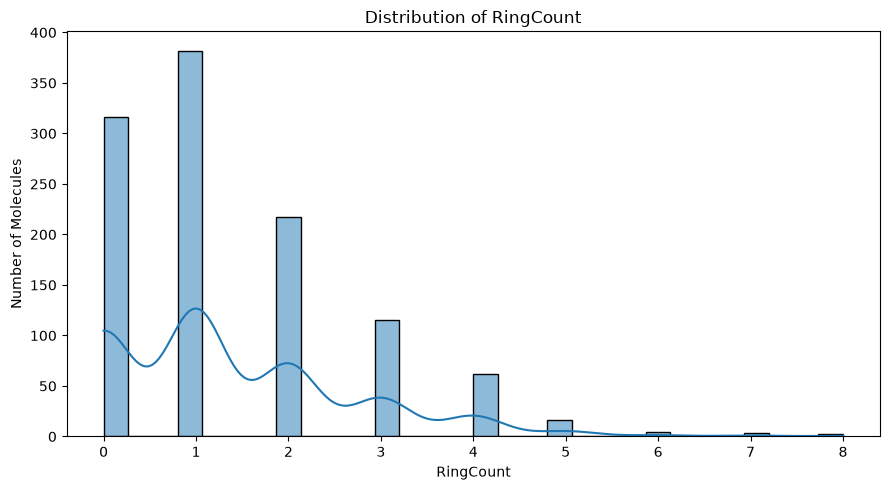

In [57]:
descriptor_columns = [
    "MolecularWeight",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "RotatableBonds",
    "RingCount"
]

for column in descriptor_columns:

    plt.figure(figsize=(9, 5))

    sns.histplot(
        df[column],
        bins=30,
        kde=True
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of Molecules")

    plt.tight_layout()

    filename = f"distribution_{column}.png"

    plt.savefig(
        os.path.join(FIGURES_PATH, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

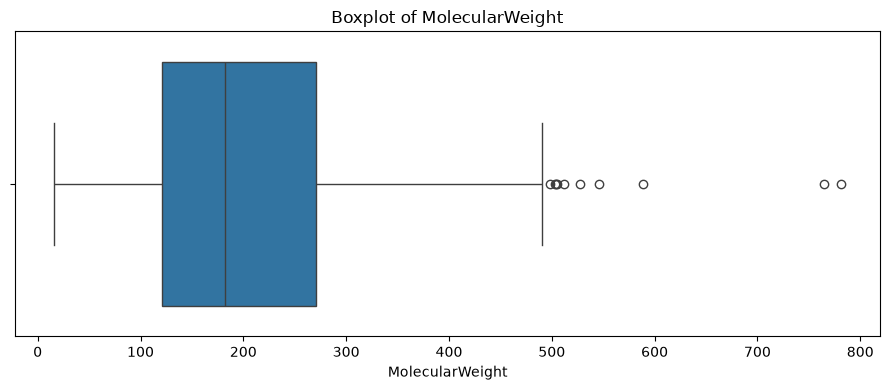

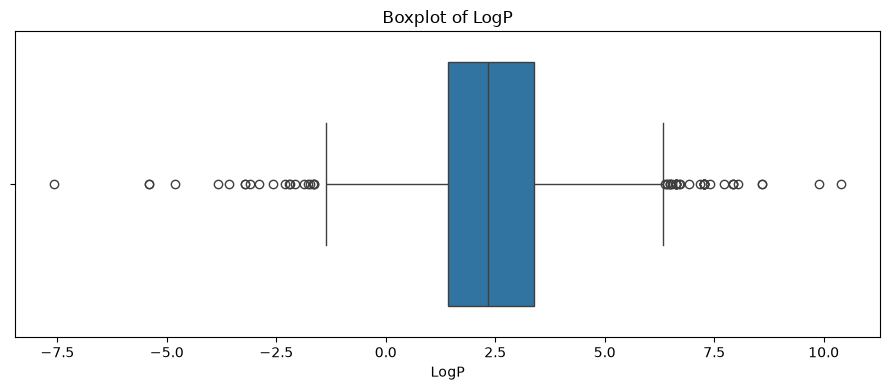

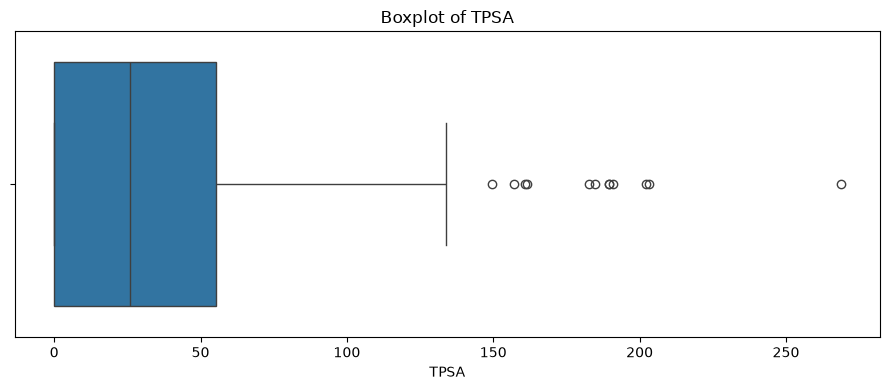

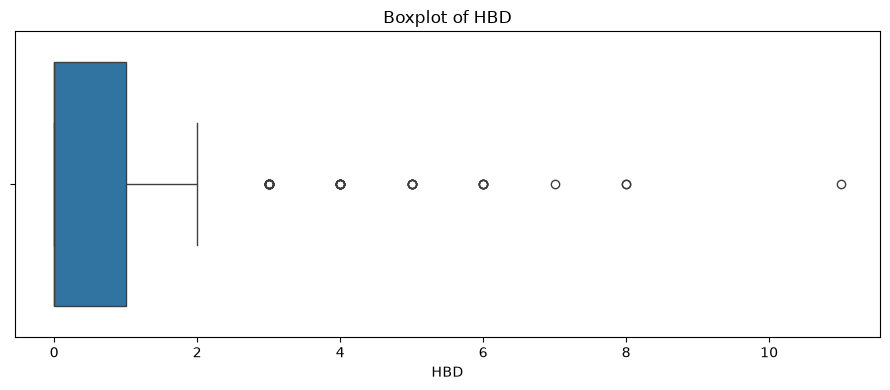

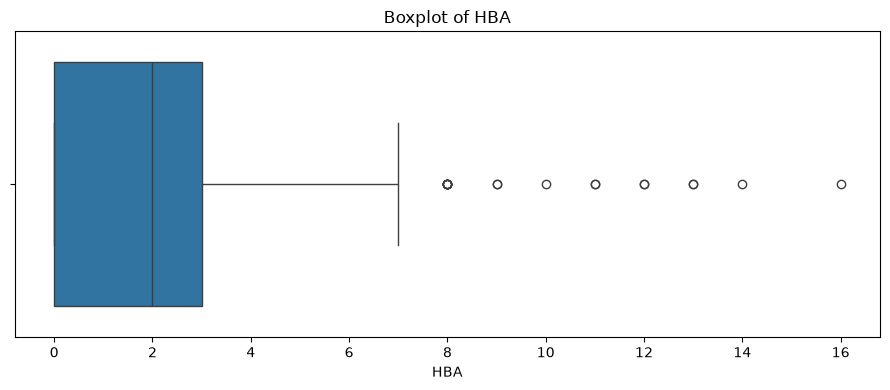

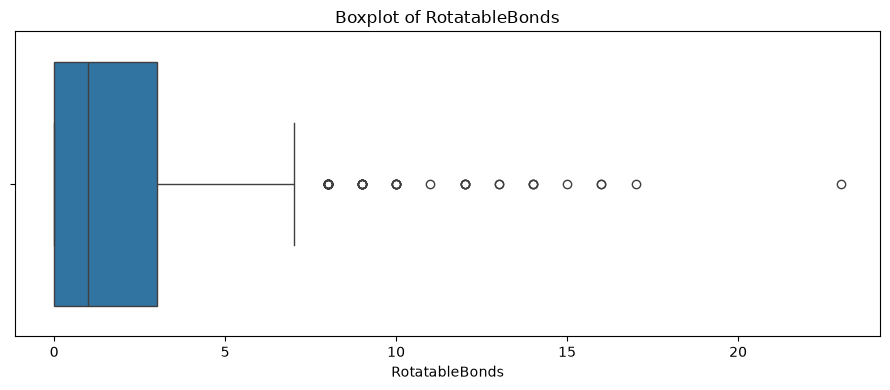

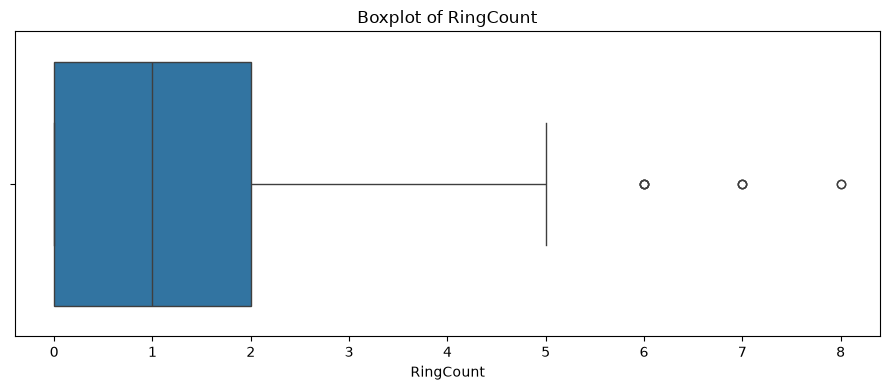

In [58]:
for column in descriptor_columns:

    plt.figure(figsize=(9, 4))

    sns.boxplot(
        x=df[column]
    )

    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)

    plt.tight_layout()

    filename = f"boxplot_{column}.png"

    plt.savefig(
        os.path.join(FIGURES_PATH, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [59]:
correlation_columns = [
    "logS",
    "MolecularWeight",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "RotatableBonds",
    "RingCount"
]

correlation_matrix = df[correlation_columns].corr()

print(correlation_matrix)

                     logS  MolecularWeight      LogP      TPSA       HBD  \
logS             1.000000        -0.639487 -0.827231  0.117422  0.201493   
MolecularWeight -0.639487         1.000000  0.477972  0.479865  0.261043   
LogP            -0.827231         0.477972  1.000000 -0.438245 -0.499523   
TPSA             0.117422         0.479865 -0.438245  1.000000  0.755094   
HBD              0.201493         0.261043 -0.499523  0.755094  1.000000   
HBA              0.046368         0.559994 -0.304434  0.899144  0.584642   
RotatableBonds  -0.245466         0.395821  0.219340  0.284277  0.073795   
RingCount       -0.512555         0.653905  0.332257  0.315661  0.220601   

                      HBA  RotatableBonds  RingCount  
logS             0.046368       -0.245466  -0.512555  
MolecularWeight  0.559994        0.395821   0.653905  
LogP            -0.304434        0.219340   0.332257  
TPSA             0.899144        0.284277   0.315661  
HBD              0.584642        0.07379

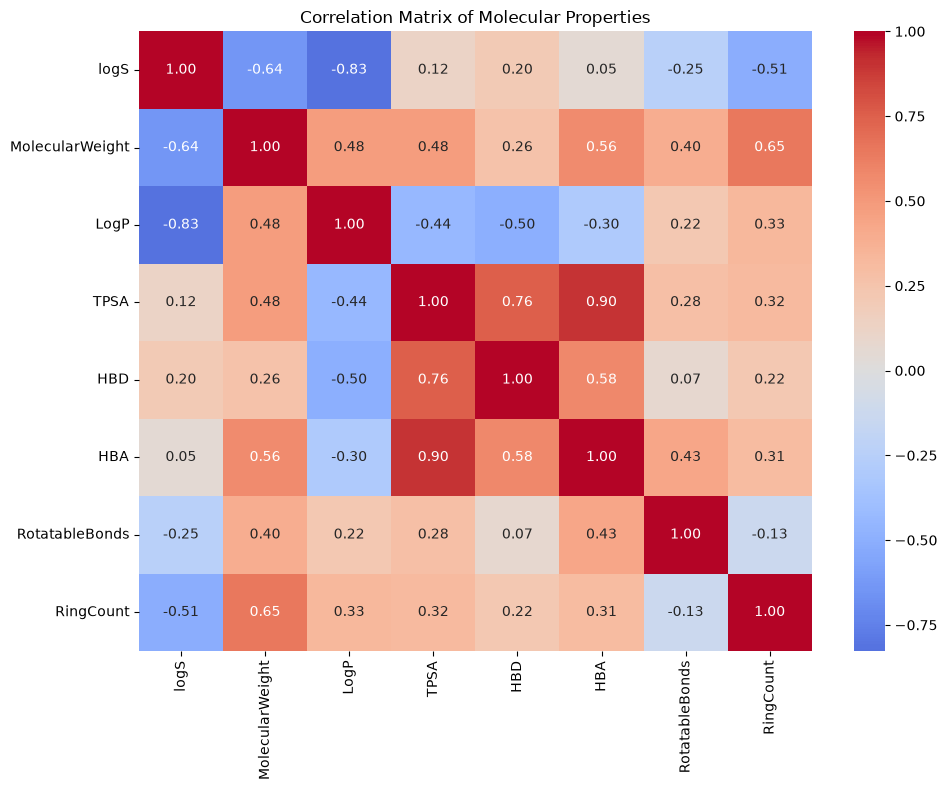

In [60]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Molecular Properties")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_PATH,
        "02_correlation_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [61]:
logS_correlations = (
    correlation_matrix["logS"]
    .sort_values(ascending=False))

print(logS_correlations)

logS               1.000000
HBD                0.201493
TPSA               0.117422
HBA                0.046368
RotatableBonds    -0.245466
RingCount         -0.512555
MolecularWeight   -0.639487
LogP              -0.827231
Name: logS, dtype: float64


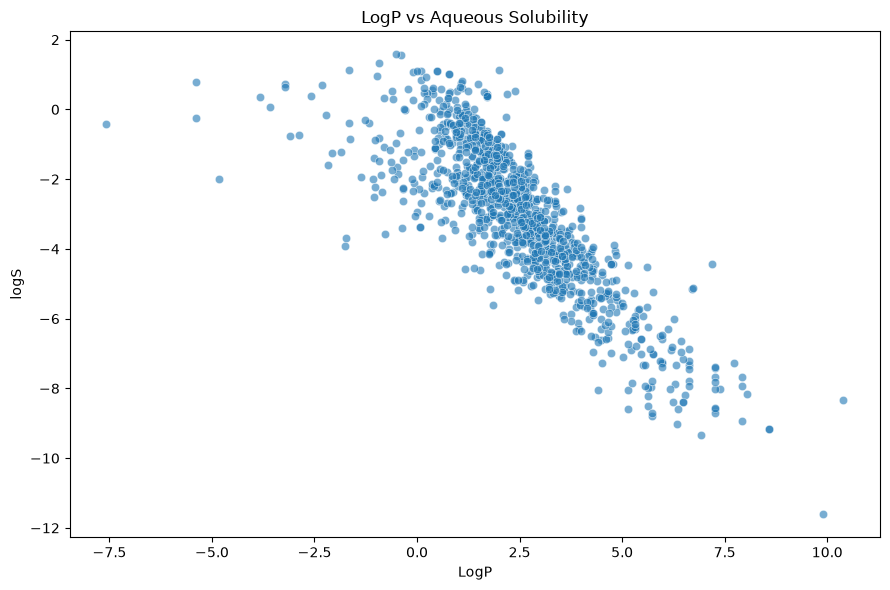

In [62]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="LogP",
    y="logS",
    alpha=0.6
)

plt.title("LogP vs Aqueous Solubility")
plt.xlabel("LogP")
plt.ylabel("logS")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_PATH,
        "03_LogP_vs_logS.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

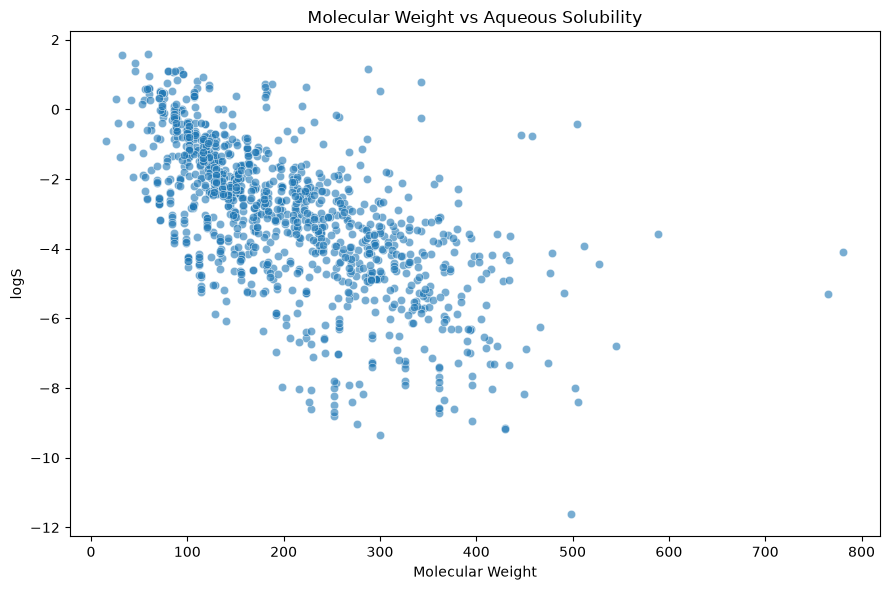

In [63]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="MolecularWeight",
    y="logS",
    alpha=0.6
)

plt.title("Molecular Weight vs Aqueous Solubility")
plt.xlabel("Molecular Weight")
plt.ylabel("logS")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_PATH,
        "04_MolecularWeight_vs_logS.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

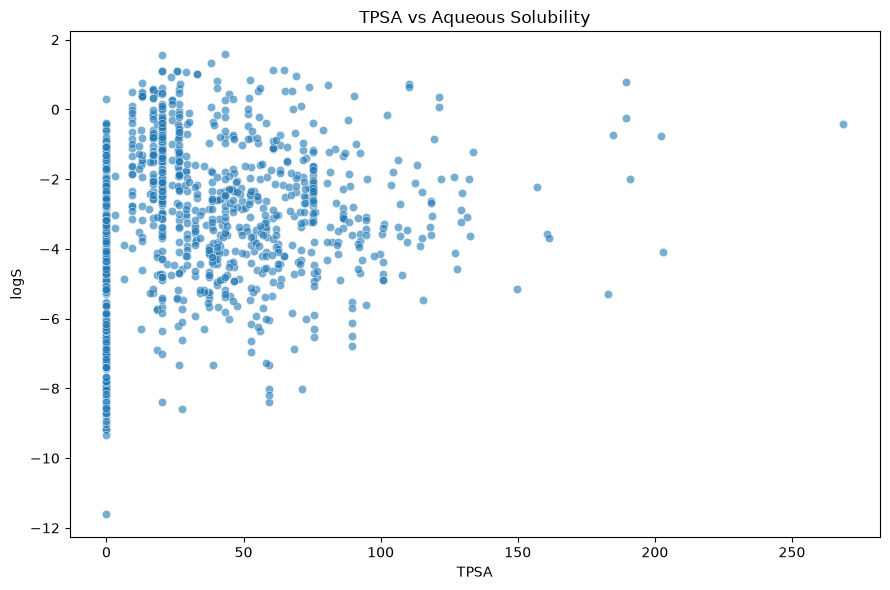

In [64]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="TPSA",
    y="logS",
    alpha=0.6
)

plt.title("TPSA vs Aqueous Solubility")
plt.xlabel("TPSA")
plt.ylabel("logS")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_PATH,
        "05_TPSA_vs_logS.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

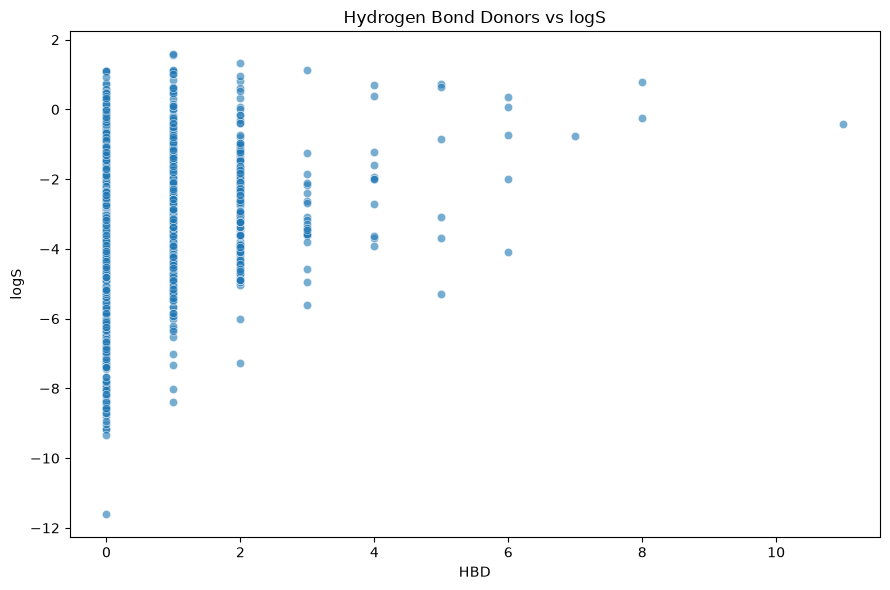

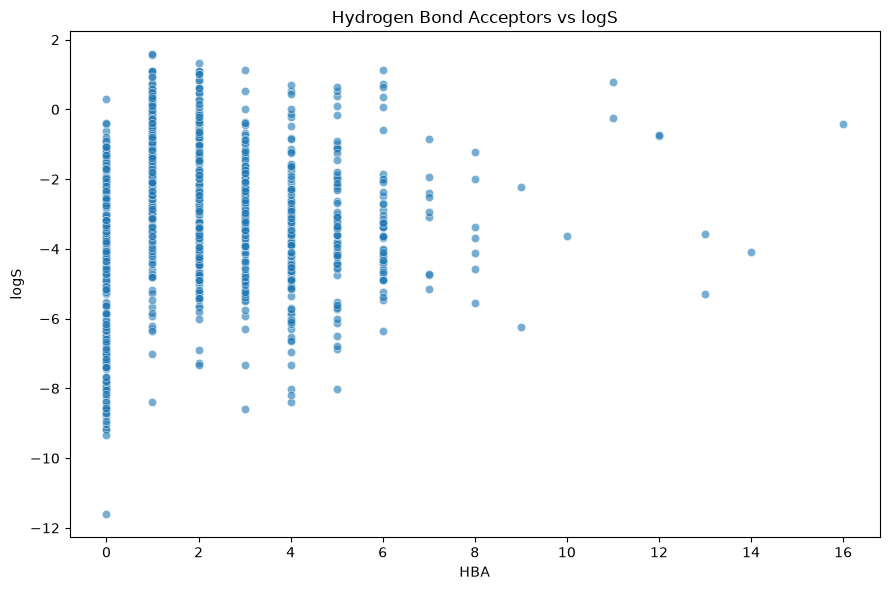

In [65]:
#HBD and HBA vs logS
figures = [
    ("HBD", "Hydrogen Bond Donors vs logS"),
    ("HBA", "Hydrogen Bond Acceptors vs logS")
]

for feature, title in figures:

    plt.figure(figsize=(9, 6))

    sns.scatterplot(
        data=df,
        x=feature,
        y="logS",
        alpha=0.6
    )

    plt.title(title)
    plt.xlabel(feature)
    plt.ylabel("logS")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            FIGURES_PATH,
            f"{feature}_vs_logS.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [66]:
# insoluble molecules
lowest_solubility = df.sort_values(
    "logS"
).head(10)

display(
    lowest_solubility[
        [
            "canonical_smiles",
            "logS",
            "MolecularWeight",
            "LogP",
            "TPSA",
            "HBD",
            "HBA"
        ]
    ]
)

,canonical_smiles,logS,MolecularWeight,LogP,TPSA,HBD,HBA
599,Clc1c(Cl)c(Cl)c(-c2c(Cl)c(Cl)c(Cl)c(Cl)c2Cl)c(...,-11.600,498.662,9.8876,0.00,0.0,0.0
713,c1cc2ccc3ccc4ccc5ccc6ccc1c1c2c3c4c5c61,-9.332,300.360,6.9192,0.00,0.0,0.0
296,Clc1cc(-c2cc(Cl)c(Cl)c(Cl)c2Cl)c(Cl)c(Cl)c1Cl,-9.160,429.772,8.5808,0.00,0.0,0.0
60,Clc1cc(Cl)c(Cl)c(-c2c(Cl)c(Cl)cc(Cl)c2Cl)c1Cl,-9.150,429.772,8.5808,0.00,0.0,0.0
671,c1cc2ccc3ccc4ccc5cccc6c(c1)c2c3c4c56,-9.018,276.338,6.3282,0.00,0.0,0.0
871,Clc1ccc(Cl)c(-c2c(Cl)c(Cl)c(Cl)c(Cl)c2Cl)c1,-8.940,395.327,7.9274,0.00,0.0,0.0
220,c1cc2cccc3c4cccc5cccc(c(c1)c23)c54,-8.804,252.316,5.7372,0.00,0.0,0.0
863,Clc1cc(Cl)c(-c2c(Cl)cc(Cl)cc2Cl)c(Cl)c1,-8.710,360.882,7.2740,0.00,0.0,0.0
633,c1ccc2c(c1)cc1ccc3cccc4ccc2c1c34,-8.699,252.316,5.7372,0.00,0.0,0.0
181,CCOc1ccc(C(C)(C)COCc2cccc(Oc3ccccc3)c2)cc1,-8.600,376.496,6.3720,27.69,0.0,3.0


In [67]:
# soluble molecules
highest_solubility = df.sort_values(
    "logS",
    ascending=False
).head(10)

display(
    highest_solubility[
        [
            "canonical_smiles",
            "logS",
            "MolecularWeight",
            "LogP",
            "TPSA",
            "HBD",
            "HBA"
        ]
    ]
)

,canonical_smiles,logS,MolecularWeight,LogP,TPSA,HBD,HBA
601,CC(N)=O,1.580,59.068,-0.5084,43.09,1.0,1.0
146,CO,1.570,32.042,-0.3915,20.23,1.0,1.0
201,CNN,1.340,46.073,-0.9205,38.05,2.0,2.0
1054,CNC(=O)C(C)SCCSP(=O)(OC)OC,1.144,287.343,1.9882,64.63,1.0,6.0
674,OCC(O)CO,1.120,92.094,-1.6681,60.69,3.0,3.0
682,CC(=O)N(C)C,1.110,87.122,0.0945,20.31,0.0,1.0
186,c1ccnnc1,1.100,80.090,0.4766,25.78,0.0,2.0
974,CCO,1.100,46.069,-0.0014,20.23,1.0,1.0
364,c1cncnc1,1.100,80.090,0.4766,25.78,0.0,2.0
10,O=C1CCCN1,1.070,85.106,-0.1036,29.10,1.0,1.0


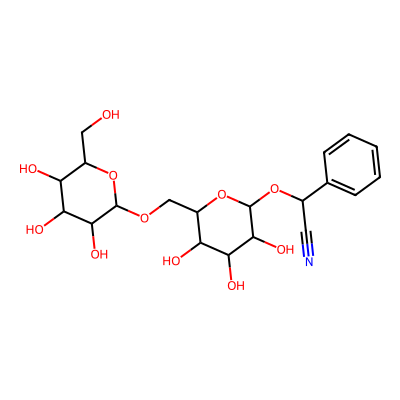

SMILES: N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1
logS: -0.77


In [68]:
from rdkit import Chem
from rdkit.Chem import Draw
smiles = df.iloc[0]["canonical_smiles"]
mol = Chem.MolFromSmiles(smiles)
display(
    Draw.MolToImage(
        mol,
        size=(400, 400)))

print("SMILES:", smiles)
print("logS:", df.iloc[0]["logS"])

In [69]:
# summary
summary = pd.DataFrame({
    "Feature": [
        "Molecular Weight",
        "LogP",
        "TPSA",
        "HBD",
        "HBA",
        "Rotatable Bonds",
        "Ring Count",
        "logS"
    ],
    "Mean": [
        df["MolecularWeight"].mean(),
        df["LogP"].mean(),
        df["TPSA"].mean(),
        df["HBD"].mean(),
        df["HBA"].mean(),
        df["RotatableBonds"].mean(),
        df["RingCount"].mean(),
        df["logS"].mean()
    ],
    "Median": [
        df["MolecularWeight"].median(),
        df["LogP"].median(),
        df["TPSA"].median(),
        df["HBD"].median(),
        df["HBA"].median(),
        df["RotatableBonds"].median(),
        df["RingCount"].median(),
        df["logS"].median()
    ],
    "Minimum": [
        df["MolecularWeight"].min(),
        df["LogP"].min(),
        df["TPSA"].min(),
        df["HBD"].min(),
        df["HBA"].min(),
        df["RotatableBonds"].min(),
        df["RingCount"].min(),
        df["logS"].min()
    ],
    "Maximum": [
        df["MolecularWeight"].max(),
        df["LogP"].max(),
        df["TPSA"].max(),
        df["HBD"].max(),
        df["HBA"].max(),
        df["RotatableBonds"].max(),
        df["RingCount"].max(),
        df["logS"].max()
    ]
})

display(summary)

,Feature,Mean,Median,Minimum,Maximum
0,Molecular Weight,203.707382,182.1720,16.0430,780.9490
1,LogP,2.453439,2.3392,-7.5714,10.3886
2,TPSA,34.714772,26.0200,0.0000,268.6800
3,HBD,0.694718,0.0000,0.0000,11.0000
4,HBA,2.062668,2.0000,0.0000,16.0000
5,Rotatable Bonds,2.173679,1.0000,0.0000,23.0000
6,Ring Count,1.387645,1.0000,0.0000,8.0000
7,logS,-3.050291,-2.8630,-11.6000,1.5800


In [70]:
summary_file = os.path.join(
    PROJECT_PATH,
    "results",
    "metrics",
    "EDA_summary.csv"
)

os.makedirs(
    os.path.dirname(summary_file),
    exist_ok=True
)

summary.to_csv(
    summary_file,
    index=False
)

print("Saved:", summary_file)

Saved: c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\results\metrics\EDA_summary.csv


In [71]:
print("Number of molecules:", len(df))
print("Number of descriptors:", len(descriptor_columns))
print("Target:", "logS")
print("Fingerprint dimensions: 2048")
print("Figures saved to:", FIGURES_PATH)

Number of molecules: 1117
Number of descriptors: 7
Target: logS
Fingerprint dimensions: 2048
Figures saved to: c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\results\figures


## Phase 5 — Prepare Data for Machine Learning

In this phase:
- Define features and target
- Prepare RDKit molecular descriptors
- Load Morgan fingerprints
- Split data into training, validation and test sets
- Scale descriptor features without data leakage
- Prepare datasets for machine learning

In [72]:
import os
import pandas as pd

PROJECT_PATH = os.path.abspath(os.path.join(os.getcwd(), ".."))
PROCESSED_DATA_PATH = os.path.join(PROJECT_PATH, "data", "processed")

# Load the clean dataset into df_clean to resolve the NameError
df_clean = pd.read_csv(os.path.join(PROCESSED_DATA_PATH, "ESOL_clean.csv"))

print("Dataset shape:", df_clean.shape)
print("\nColumns:")
print(df_clean.columns.tolist())

Dataset shape: (1117, 10)

Columns:
['SMILES', 'canonical_smiles', 'logS', 'MolecularWeight', 'LogP', 'TPSA', 'HBD', 'HBA', 'RotatableBonds', 'RingCount']


In [73]:
descriptor_columns = [
    "MolecularWeight",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "RotatableBonds",
    "RingCount"
]

X_descriptors = df_clean[descriptor_columns].copy()

y = df_clean["logS"].copy()

print("X shape:", X_descriptors.shape)
print("y shape:", y.shape)

X shape: (1117, 7)
y shape: (1117,)


In [74]:
#Load Morgan fingerprints
fingerprint_file = os.path.join(
    PROCESSED_DATA_PATH,
    "ESOL_morgan_fingerprints.npy"
)

X_fingerprints = np.load(fingerprint_file)
print("Fingerprint shape:", X_fingerprints.shape)

Fingerprint shape: (1117, 2048)


In [75]:
print("Dataset:", len(df_clean))
print("Descriptors:", len(X_descriptors))
print("Fingerprints:", len(X_fingerprints))
print("Target:", len(y))

Dataset: 1117
Descriptors: 1117
Fingerprints: 1117
Target: 1117


In [76]:
#Train/Validation/Test split Training ≈ 782 , Validation   ≈ 167 , Testing ≈ 168
from sklearn.model_selection import train_test_split

X_desc_train, X_desc_temp, y_train, y_temp = train_test_split(
    X_descriptors, y,
    test_size=0.30,
    random_state=42
)

In [77]:
X_desc_val, X_desc_test, y_val, y_test = train_test_split(
    X_desc_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

In [78]:
print("Training:", X_desc_train.shape)
print("Validation:", X_desc_val.shape)
print("Test:", X_desc_test.shape)

Training: (781, 7)
Validation: (168, 7)
Test: (168, 7)


In [79]:
#Split Morgan fingerprints using the SAME indices
train_indices = X_desc_train.index
val_indices = X_desc_val.index
test_indices = X_desc_test.index

X_fp_train = X_fingerprints[train_indices]
X_fp_val = X_fingerprints[val_indices]
X_fp_test = X_fingerprints[test_indices]

print("Fingerprint training:", X_fp_train.shape)
print("Fingerprint validation:", X_fp_val.shape)
print("Fingerprint test:", X_fp_test.shape)

Fingerprint training: (781, 2048)
Fingerprint validation: (168, 2048)
Fingerprint test: (168, 2048)


In [80]:
print("Training logS:")
print(y_train.describe())

print("\nValidation logS:")
print(y_val.describe())

print("\nTest logS:")
print(y_test.describe())

Training logS:
count    781.000000
mean      -3.078251
std        2.083266
min      -11.600000
25%       -4.370000
50%       -2.928000
75%       -1.600000
max        1.580000
Name: logS, dtype: float64

Validation logS:
count    168.000000
mean      -3.014827
std        2.126069
min       -9.332000
25%       -4.020000
50%       -2.770000
75%       -1.637500
max        1.144000
Name: logS, dtype: float64

Test logS:
count    168.000000
mean      -2.955774
std        2.125420
min       -9.160000
25%       -4.332250
50%       -2.725000
75%       -1.477500
max        1.100000
Name: logS, dtype: float64


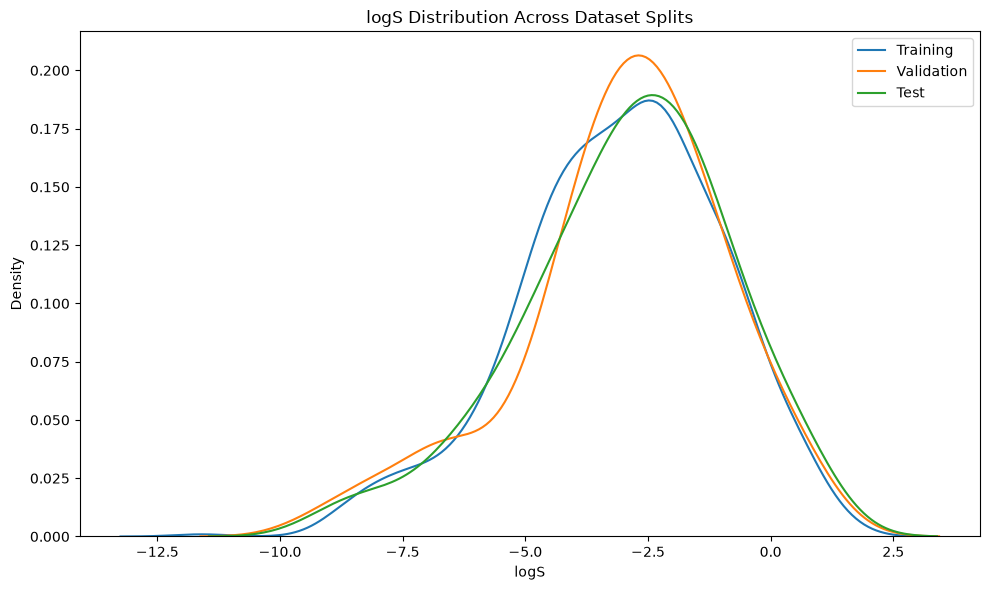

In [81]:
plt.figure(figsize=(10, 6))

sns.kdeplot(
    y_train, label="Training")

sns.kdeplot(
    y_val, label="Validation")

sns.kdeplot(
    y_test, label="Test")

plt.title("logS Distribution Across Dataset Splits")
plt.xlabel("logS")
plt.ylabel("Density")
plt.legend()

plt.tight_layout()
plt.show()

In [82]:
#Scale the descriptors
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_desc_train_scaled = scaler.fit_transform(X_desc_train)
X_desc_val_scaled = scaler.transform(X_desc_val)
X_desc_test_scaled = scaler.transform(X_desc_test)

In [83]:
print("Training means:")
print(X_desc_train_scaled.mean(axis=0))

print("\nTraining standard deviations:")
print(X_desc_train_scaled.std(axis=0))

Training means:
[ 1.30781714e-16  1.25095552e-17 -5.45871500e-17  5.57243823e-17
 -5.45871500e-17 -7.96062604e-18 -4.09403625e-17]

Training standard deviations:
[1. 1. 1. 1. 1. 1. 1.]


In [84]:
X_fp_train = X_fp_train.astype(np.float32)
X_fp_val = X_fp_val.astype(np.float32)
X_fp_test = X_fp_test.astype(np.float32)

print(X_fp_train.dtype)

float32


In [85]:
y_train_np = y_train.to_numpy(dtype=np.float32)
y_val_np = y_val.to_numpy(dtype=np.float32)
y_test_np = y_test.to_numpy(dtype=np.float32)

print(y_train_np.shape)
print(y_val_np.shape)
print(y_test_np.shape)

(781,)
(168,)
(168,)


In [86]:
print("========== FINAL DATA PREPARATION ==========")

print("\nDescriptor features:")
print("Train:", X_desc_train_scaled.shape)
print("Validation:", X_desc_val_scaled.shape)
print("Test:", X_desc_test_scaled.shape)

print("\nMorgan fingerprints:")
print("Train:", X_fp_train.shape)
print("Validation:", X_fp_val.shape)
print("Test:", X_fp_test.shape)

print("\nTargets:")
print("Train:", y_train_np.shape)
print("Validation:", y_val_np.shape)
print("Test:", y_test_np.shape)

========== FINAL DATA PREPARATION ==========

Descriptor features:
Train: (781, 7)
Validation: (168, 7)
Test: (168, 7)

Morgan fingerprints:
Train: (781, 2048)
Validation: (168, 2048)
Test: (168, 2048)

Targets:
Train: (781,)
Validation: (168,)
Test: (168,)


In [87]:
import joblib

scaler_path = os.path.join(
    PROJECT_PATH,
    "models",
    "descriptor_scaler.pkl"
)

joblib.dump(
    scaler,
    scaler_path
)

print("Scaler saved to:")
print(scaler_path)

Scaler saved to:
c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\models\descriptor_scaler.pkl


In [88]:
split_indices = {
    "train": train_indices.to_numpy(),
    "validation": val_indices.to_numpy(),
    "test": test_indices.to_numpy()
}

split_path = os.path.join(
    PROCESSED_DATA_PATH,
    "data_split_indices.npz"
)

np.savez(
    split_path,
    **split_indices
)

print("Split indices saved to:")
print(split_path)

Split indices saved to:
c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\data\processed\data_split_indices.npz


## Phase 6 — Baseline Machine Learning

In [89]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [90]:
def evaluate_model(model, X_train, y_train, X_val, y_val, X_test, y_test):

    # Train
    model.fit(X_train, y_train)

    # Predictions
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)

    # Metrics
    results = {
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Validation MAE": mean_absolute_error(y_val, val_pred),
        "Test MAE": mean_absolute_error(y_test, test_pred),

        "Train RMSE": np.sqrt(
            mean_squared_error(y_train, train_pred)
        ),

        "Validation RMSE": np.sqrt(
            mean_squared_error(y_val, val_pred)
        ),

        "Test RMSE": np.sqrt(
            mean_squared_error(y_test, test_pred)
        ),

        "Train R²": r2_score(y_train, train_pred),
        "Validation R²": r2_score(y_val, val_pred),
        "Test R²": r2_score(y_test, test_pred)
    }

    return results, train_pred, val_pred, test_pred

In [91]:
#Model 1 — Linear Regression
linear_model = LinearRegression()
linear_results, linear_train_pred, linear_val_pred, linear_test_pred = evaluate_model(
    linear_model,
    X_desc_train_scaled,
    y_train_np,
    X_desc_val_scaled,
    y_val_np,
    X_desc_test_scaled,
    y_test_np
)

linear_results

{'Train MAE': 0.7628621084815215,
 'Validation MAE': 0.7326026460989349,
 'Test MAE': 0.7753590609760648,
 'Train RMSE': np.float64(0.9664112135503572),
 'Validation RMSE': np.float64(0.9657553604184119),
 'Test RMSE': np.float64(1.0233028382982399),
 'Train R²': 0.7845280302385167,
 'Validation R²': 0.7924262082365816,
 'Test R²': 0.7668090562257814}

In [92]:
#Model 2 — Random Forest
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

rf_results, rf_train_pred, rf_val_pred, rf_test_pred = evaluate_model(
    rf_model,
    X_desc_train_scaled,
    y_train_np,
    X_desc_val_scaled,
    y_val_np,
    X_desc_test_scaled,
    y_test_np
)

rf_results

{'Train MAE': 0.20883094204602767,
 'Validation MAE': 0.500831303344915,
 'Test MAE': 0.5726819518362545,
 'Train RMSE': np.float64(0.2857344630791876),
 'Validation RMSE': np.float64(0.7731699594224994),
 'Test RMSE': np.float64(0.7532128552099531),
 'Train R²': 0.9811638512994847,
 'Validation R²': 0.8669581708169334,
 'Test R²': 0.8736606116944177}

In [93]:
#Compare the models
results_df = pd.DataFrame(
    [
        linear_results,
        rf_results
    ],
    index=[
        "Linear Regression",
        "Random Forest"
    ]
)

display(results_df)

,Train MAE,Validation MAE,Test MAE,Train RMSE,Validation RMSE,Test RMSE,Train R²,Validation R²,Test R²
Linear Regression,0.762862,0.732603,0.775359,0.966411,0.965755,1.023303,0.784528,0.792426,0.766809
Random Forest,0.208831,0.500831,0.572682,0.285734,0.773170,0.753213,0.981164,0.866958,0.873661


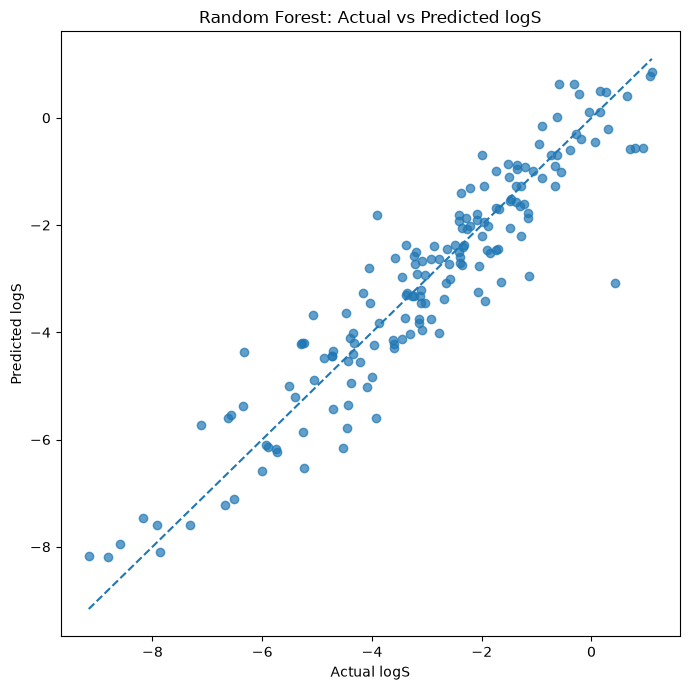

In [94]:
#Actual vs predicted plot
plt.figure(figsize=(7, 7))

plt.scatter(
    y_test_np,
    rf_test_pred,
    alpha=0.7
)

# Perfect prediction line
min_value = min(
    y_test_np.min(),
    rf_test_pred.min()
)

max_value = max(
    y_test_np.max(),
    rf_test_pred.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual logS")
plt.ylabel("Predicted logS")
plt.title("Random Forest: Actual vs Predicted logS")

plt.tight_layout()

plt.show()

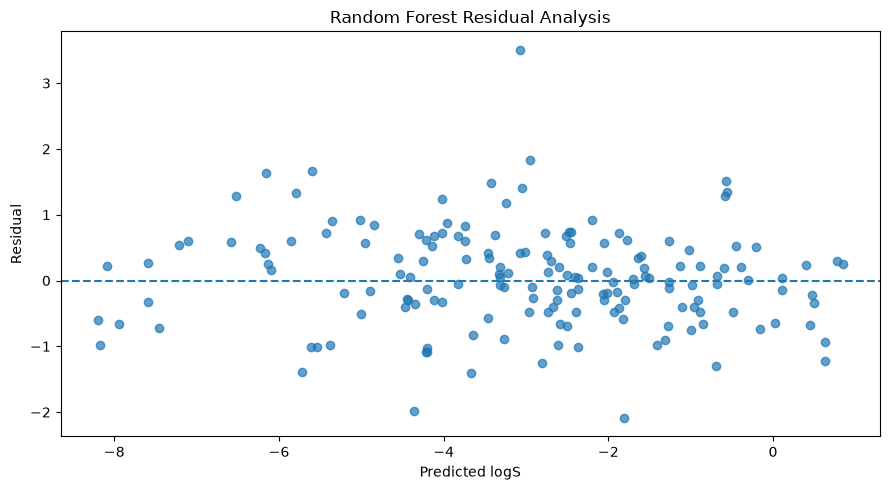

In [95]:
#residual analysis
rf_residuals = y_test_np - rf_test_pred
plt.figure(figsize=(9, 5))
plt.scatter(
    rf_test_pred,
    rf_residuals,
    alpha=0.7
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted logS")
plt.ylabel("Residual")
plt.title("Random Forest Residual Analysis")
plt.tight_layout()
plt.show()

In [96]:
#feature importance
feature_importance = pd.DataFrame({
    "Feature": descriptor_columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
1,LogP,0.809877
0,MolecularWeight,0.110521
2,TPSA,0.036164
6,RingCount,0.013538
5,RotatableBonds,0.010989
4,HBA,0.010930
3,HBD,0.007982


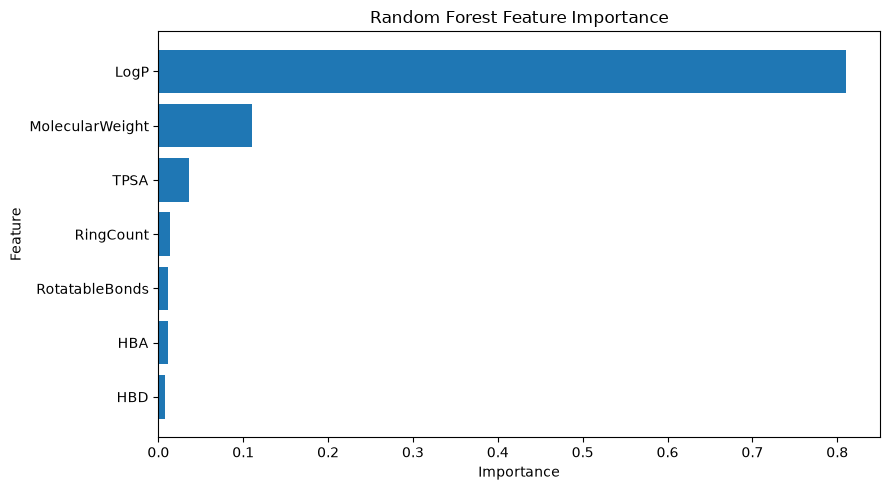

In [97]:
plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_PATH,
        "06_random_forest_feature_importance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [98]:
#Add XGBoost
import xgboost as xgb
print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [99]:
#XGBoost model
xgb_model = xgb.XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

In [100]:
#Train XGBoost
xgb_results, xgb_train_pred, xgb_val_pred, xgb_test_pred = evaluate_model(
    xgb_model,
    X_desc_train_scaled,
    y_train_np,
    X_desc_val_scaled,
    y_val_np,
    X_desc_test_scaled,
    y_test_np
)
xgb_results

{'Train MAE': 0.3444315493106842,
 'Validation MAE': 0.49892497062683105,
 'Test MAE': 0.5141451954841614,
 'Train RMSE': np.float64(0.43800047790488206),
 'Validation RMSE': np.float64(0.7597315371204033),
 'Test RMSE': np.float64(0.6734445336985746),
 'Train R²': 0.9557394981384277,
 'Validation R²': 0.871542751789093,
 'Test R²': 0.8990033268928528}

In [101]:
results_df = pd.DataFrame(
    [
        linear_results,
        rf_results,
        xgb_results
    ],
    index=[
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ]
)

display(results_df)

,Train MAE,Validation MAE,Test MAE,Train RMSE,Validation RMSE,Test RMSE,Train R²,Validation R²,Test R²
Linear Regression,0.762862,0.732603,0.775359,0.966411,0.965755,1.023303,0.784528,0.792426,0.766809
Random Forest,0.208831,0.500831,0.572682,0.285734,0.773170,0.753213,0.981164,0.866958,0.873661
XGBoost,0.344432,0.498925,0.514145,0.438000,0.759732,0.673445,0.955739,0.871543,0.899003


In [102]:
comparison = results_df[
    [
        "Test MAE",
        "Test RMSE",
        "Test R²"
    ]
].sort_values(
    "Test RMSE"
)

display(comparison)

,Test MAE,Test RMSE,Test R²
XGBoost,0.514145,0.673445,0.899003
Random Forest,0.572682,0.753213,0.873661
Linear Regression,0.775359,1.023303,0.766809


In [103]:
metrics_path = os.path.join(
    PROJECT_PATH,
    "results",
    "metrics",
    "baseline_model_results.csv"
)

results_df.to_csv(
    metrics_path
)

print("Baseline results saved to:")
print(metrics_path)

Baseline results saved to:
c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\results\metrics\baseline_model_results.csv


## Phase 7 — Deep Learning Model

In [104]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("PyTorch version:", torch.__version__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

PyTorch version: 2.14.1+cpu
Using device: cpu


In [105]:
#Prepare fingerprint data
X_fp_train_tensor = torch.tensor(
    X_fp_train,
    dtype=torch.float32
)

X_fp_val_tensor = torch.tensor(
    X_fp_val,
    dtype=torch.float32
)

X_fp_test_tensor = torch.tensor(
    X_fp_test,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_np,
    dtype=torch.float32
).view(-1, 1)

y_val_tensor = torch.tensor(
    y_val_np,
    dtype=torch.float32
).view(-1, 1)

y_test_tensor = torch.tensor(
    y_test_np,
    dtype=torch.float32
).view(-1, 1)

print("Training:", X_fp_train_tensor.shape, y_train_tensor.shape)
print("Validation:", X_fp_val_tensor.shape, y_val_tensor.shape)
print("Test:", X_fp_test_tensor.shape, y_test_tensor.shape)

Training: torch.Size([781, 2048]) torch.Size([781, 1])
Validation: torch.Size([168, 2048]) torch.Size([168, 1])
Test: torch.Size([168, 2048]) torch.Size([168, 1])


In [106]:
batch_size = 32

train_dataset = TensorDataset(
    X_fp_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_fp_val_tensor,
    y_val_tensor
)

test_dataset = TensorDataset(
    X_fp_test_tensor,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))
print("Number of test batches:", len(test_loader))

Number of training batches: 25
Number of validation batches: 6
Number of test batches: 6


In [107]:
class SolubilityNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(2048, 512),
            nn.ReLU(),
            nn.Dropout(0.30),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(256, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

In [108]:
model = SolubilityNet().to(device)
print(model)

SolubilityNet(
  (network): Sequential(
    (0): Linear(in_features=2048, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=256, out_features=64, bias=True)
    (7): ReLU()
    (8): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [109]:
#Define loss function and optimizer
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 1e-05
)


In [110]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    total_loss = 0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

    average_loss = total_loss / len(loader.dataset)

    return average_loss

In [111]:
#validation function
def validate_model(model, loader, criterion, device):

    model.eval()

    total_loss = 0

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)

            loss = criterion(
                predictions,
                y_batch
            )

            total_loss += loss.item() * X_batch.size(0)

    average_loss = total_loss / len(loader.dataset)

    return average_loss

In [112]:
num_epochs = 200

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_model_state = None

patience = 20
patience_counter = 0

for epoch in range(num_epochs):

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss = validate_model(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_state = {
            key: value.cpu().clone()
            for key, value in model.state_dict().items()
        }

        patience_counter = 0

    else:

        patience_counter += 1

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch+1}/{num_epochs}] "
            f"Train Loss: {train_loss:.4f} "
            f"Val Loss: {val_loss:.4f}"
        )

    if patience_counter >= patience:

        print(
            f"\nEarly stopping at epoch {epoch+1}"
        )

        break

Epoch [10/200] Train Loss: 0.3267 Val Loss: 1.3759
Epoch [20/200] Train Loss: 0.1926 Val Loss: 1.2641
Epoch [30/200] Train Loss: 0.1931 Val Loss: 1.3006

Early stopping at epoch 35


In [113]:
model.load_state_dict(best_model_state)
model = model.to(device)
print("Best validation loss:", best_val_loss)

Best validation loss: 1.2240266232263475


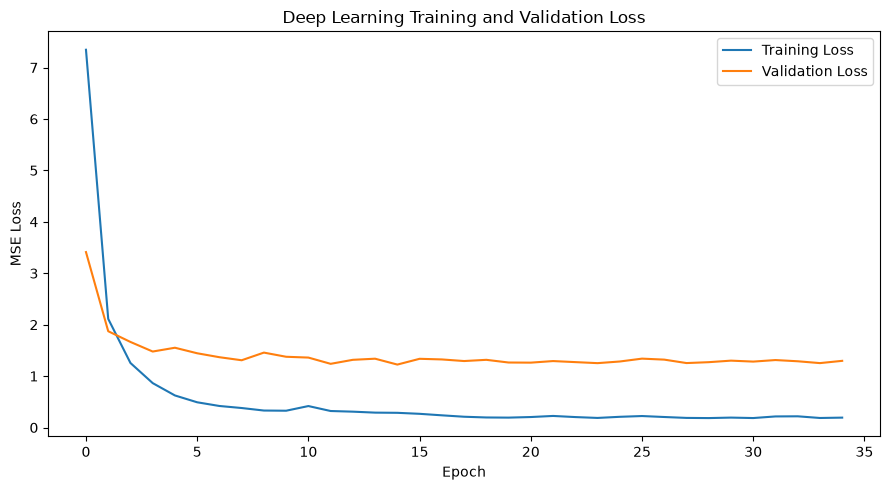

In [114]:
#training and validation loss
plt.figure(figsize=(9, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Deep Learning Training and Validation Loss")

plt.legend()

plt.tight_layout()
plt.show()

In [115]:
model.eval()

with torch.no_grad():

    test_predictions = model(
        X_fp_test_tensor.to(device)
    )

test_predictions = (
    test_predictions
    .cpu()
    .numpy()
    .flatten()
)

print("Predictions shape:", test_predictions.shape)
print("First 10 predictions:")
print(test_predictions[:10])

Predictions shape: (168,)
First 10 predictions:
[-1.6145425 -1.166983  -2.2248921 -4.235448  -1.3280727 -1.6200805
 -0.8328692 -1.3312193 -0.8160703 -2.948923 ]


In [116]:
dl_mae = mean_absolute_error(
    y_test_np,
    test_predictions
)

dl_rmse = np.sqrt(
    mean_squared_error(
        y_test_np,
        test_predictions
    )
)

dl_r2 = r2_score(
    y_test_np,
    test_predictions
)

print("Deep Learning Results")
print("---------------------")
print("Test MAE :", dl_mae)
print("Test RMSE:", dl_rmse)
print("Test R²  :", dl_r2)

Deep Learning Results
---------------------
Test MAE : 0.8565255999565125
Test RMSE: 1.1198830264178874
Test R²  : 0.7207143306732178


In [117]:
dl_results = {
    "Test MAE": dl_mae,
    "Test RMSE": dl_rmse,
    "Test R²": dl_r2
}

final_comparison = pd.DataFrame(
    [
        xgb_results,
        rf_results,
        linear_results,
        dl_results
    ],
    index=[
        "XGBoost",
        "Random Forest",
        "Linear Regression",
        "Deep Learning"
    ]
)

display(
    final_comparison[
        [
            "Test MAE",
            "Test RMSE",
            "Test R²"
        ]
    ].sort_values(
        "Test RMSE"
    )
)

,Test MAE,Test RMSE,Test R²
XGBoost,0.514145,0.673445,0.899003
Random Forest,0.572682,0.753213,0.873661
Linear Regression,0.775359,1.023303,0.766809
Deep Learning,0.856526,1.119883,0.720714


Improved Deep Learning

In [118]:
class ImprovedSolubilityNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(

            # Input: 2048-bit Morgan fingerprint
            nn.Linear(2048, 256),
            nn.ReLU(),
            nn.Dropout(0.40),

            # Hidden layer
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.30),

            # Output
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

In [119]:
improved_model = ImprovedSolubilityNet().to(device)
print(improved_model)

ImprovedSolubilityNet(
  (network): Sequential(
    (0): Linear(in_features=2048, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [120]:
improved_criterion = nn.MSELoss()

improved_optimizer = torch.optim.Adam(
    improved_model.parameters(),
    lr=0.0003,
    weight_decay=1e-4
)

print("Learning rate:", 0.0003)
print("Weight decay:", 1e-4)

Learning rate: 0.0003
Weight decay: 0.0001


In [121]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    improved_optimizer,
    mode="min",
    factor=0.5,
    patience=7
)

In [122]:
num_epochs_improved = 150

improved_train_losses = []
improved_val_losses = []

best_improved_val_loss = float("inf")
best_improved_model_state = None

patience = 15
patience_counter = 0

for epoch in range(num_epochs_improved):

    train_loss = train_one_epoch(
        improved_model,
        train_loader,
        improved_criterion,
        improved_optimizer,
        device
    )

    val_loss = validate_model(
        improved_model,
        val_loader,
        improved_criterion,
        device
    )

    # Store losses
    improved_train_losses.append(train_loss)
    improved_val_losses.append(val_loss)

    # Update learning rate
    scheduler.step(val_loss)

    # Save best model
    if val_loss < best_improved_val_loss:

        best_improved_val_loss = val_loss

        best_improved_model_state = {
            key: value.cpu().clone()
            for key, value in improved_model.state_dict().items()
        }

        patience_counter = 0

    else:

        patience_counter += 1

    # Current learning rate
    current_lr = improved_optimizer.param_groups[0]["lr"]

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch+1}/{num_epochs_improved}] "
            f"Train Loss: {train_loss:.4f} "
            f"Val Loss: {val_loss:.4f} "
            f"LR: {current_lr:.6f}"
        )

    # Early stopping
    if patience_counter >= patience:

        print(
            f"\nEarly stopping at epoch {epoch+1}"
        )

        break

Epoch [10/150] Train Loss: 1.2052 Val Loss: 1.7470 LR: 0.000300
Epoch [20/150] Train Loss: 0.6631 Val Loss: 1.5187 LR: 0.000300
Epoch [30/150] Train Loss: 0.4133 Val Loss: 1.4801 LR: 0.000300
Epoch [40/150] Train Loss: 0.4513 Val Loss: 1.4431 LR: 0.000300
Epoch [50/150] Train Loss: 0.3621 Val Loss: 1.4485 LR: 0.000150
Epoch [60/150] Train Loss: 0.3870 Val Loss: 1.4416 LR: 0.000150
Epoch [70/150] Train Loss: 0.3553 Val Loss: 1.4178 LR: 0.000075
Epoch [80/150] Train Loss: 0.3270 Val Loss: 1.3954 LR: 0.000075
Epoch [90/150] Train Loss: 0.3243 Val Loss: 1.4030 LR: 0.000075
Epoch [100/150] Train Loss: 0.3249 Val Loss: 1.3908 LR: 0.000037
Epoch [110/150] Train Loss: 0.2798 Val Loss: 1.3805 LR: 0.000037
Epoch [120/150] Train Loss: 0.3207 Val Loss: 1.3825 LR: 0.000019

Early stopping at epoch 121


In [123]:
improved_model.load_state_dict(
    best_improved_model_state
)

improved_model = improved_model.to(device)

print(
    "Best validation loss:",
    best_improved_val_loss
)

Best validation loss: 1.377190391222636


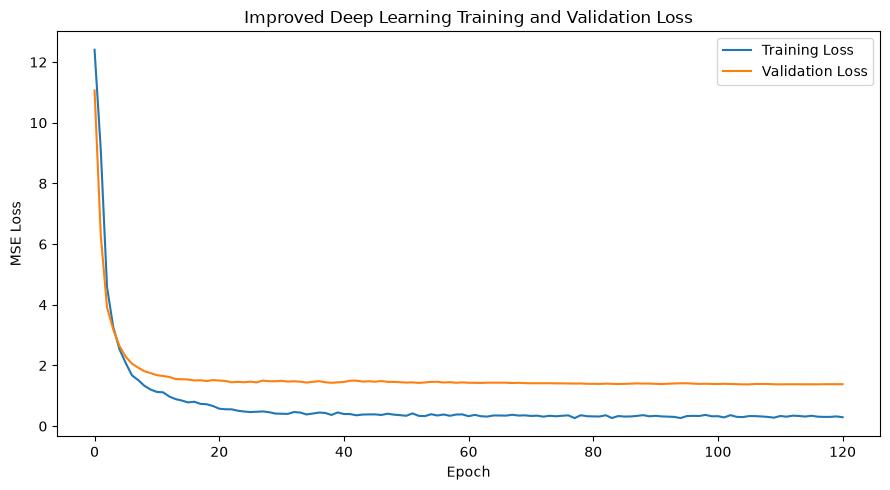

In [124]:
plt.figure(figsize=(9, 5))

plt.plot(
    improved_train_losses,
    label="Training Loss"
)

plt.plot(
    improved_val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.title(
    "Improved Deep Learning Training and Validation Loss"
)

plt.legend()

plt.tight_layout()
plt.show()

In [125]:
improved_model.eval()

with torch.no_grad():

    improved_test_predictions = improved_model(
        X_fp_test_tensor.to(device)
    )

improved_test_predictions = (
    improved_test_predictions
    .cpu()
    .numpy()
    .flatten()
)

print(
    "Predictions shape:",
    improved_test_predictions.shape
)

print(
    "First 10 predictions:"
)

print(
    improved_test_predictions[:10]
)

Predictions shape: (168,)
First 10 predictions:
[-1.729954  -1.415391  -1.7238657 -3.989421  -1.5020392 -1.6393664
 -0.5616826 -1.2040079 -0.6386509 -2.8258386]


In [126]:
improved_dl_mae = mean_absolute_error(
    y_test_np,
    improved_test_predictions
)

improved_dl_rmse = np.sqrt(
    mean_squared_error(
        y_test_np,
        improved_test_predictions
    )
)

improved_dl_r2 = r2_score(
    y_test_np,
    improved_test_predictions
)

print("Improved Deep Learning Results")
print("--------------------------------")
print("Test MAE :", improved_dl_mae)
print("Test RMSE:", improved_dl_rmse)
print("Test R²  :", improved_dl_r2)

Improved Deep Learning Results
--------------------------------
Test MAE : 0.8965526819229126
Test RMSE: 1.1897847131521369
Test R²  : 0.6847608685493469


In [127]:
improved_dl_results = {
    "Test MAE": improved_dl_mae,
    "Test RMSE": improved_dl_rmse,
    "Test R²": improved_dl_r2
}

phase7_comparison = pd.DataFrame(
    [
        xgb_results,
        rf_results,
        linear_results,
        dl_results,
        improved_dl_results
    ],
    index=[
        "XGBoost",
        "Random Forest",
        "Linear Regression",
        "Deep Learning",
        "Improved Deep Learning"
    ]
)

display(
    phase7_comparison[
        [
            "Test MAE",
            "Test RMSE",
            "Test R²"
        ]
    ].sort_values(
        "Test RMSE"
    )
)

,Test MAE,Test RMSE,Test R²
XGBoost,0.514145,0.673445,0.899003
Random Forest,0.572682,0.753213,0.873661
Linear Regression,0.775359,1.023303,0.766809
Deep Learning,0.856526,1.119883,0.720714
Improved Deep Learning,0.896553,1.189785,0.684761


In [128]:
import joblib

xgb_model_path = os.path.join(
    PROJECT_PATH,
    "models",
    "xgboost_solubility_model.pkl"
)

joblib.dump(
    xgb_model,
    xgb_model_path
)

print("XGBoost model saved to:")
print(xgb_model_path)

XGBoost model saved to:
c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\models\xgboost_solubility_model.pkl


In [129]:
feature_names_path = os.path.join(
    PROJECT_PATH,
    "models",
    "descriptor_feature_names.txt"
)

with open(feature_names_path, "w") as f:
    for feature in descriptor_columns:
        f.write(feature + "\n")

print("Feature names saved to:")
print(feature_names_path)

Feature names saved to:
c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\models\descriptor_feature_names.txt


## Phase 8 — MCMC / Gibbs Sampling

In [130]:
print("XGBoost model:", type(xgb_model))
print("Descriptor columns:")
print(descriptor_columns)

XGBoost model: <class 'xgboost.sklearn.XGBRegressor'>
Descriptor columns:
['MolecularWeight', 'LogP', 'TPSA', 'HBD', 'HBA', 'RotatableBonds', 'RingCount']


In [131]:
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, Crippen
import pandas as pd
import numpy as np

def calculate_descriptors(smiles):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    descriptors = {
        "MolecularWeight": Descriptors.MolWt(mol),
        "LogP": Crippen.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
        "HBD": Lipinski.NumHDonors(mol),
        "HBA": Lipinski.NumHAcceptors(mol),
        "RotatableBonds": Lipinski.NumRotatableBonds(mol),
        "RingCount": Lipinski.RingCount(mol)
    }

    return descriptors

In [132]:
test_smiles = df_clean.iloc[0]["canonical_smiles"]

test_descriptors = calculate_descriptors(
    test_smiles
)

print("SMILES:")
print(test_smiles)

print("\nDescriptors:")
print(test_descriptors)

SMILES:
N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1

Descriptors:
{'MolecularWeight': 457.4320000000001, 'LogP': -3.108019999999997, 'TPSA': 202.32, 'HBD': 7, 'HBA': 12, 'RotatableBonds': 7, 'RingCount': 3}


In [133]:

def predict_logS(smiles):
    descriptors = calculate_descriptors(smiles)

    if descriptors is None:
        return None

    descriptors = pd.Series(descriptors)
    if descriptors.isna().any():
        return None

    X = pd.DataFrame(
        [[descriptors[col] for col in descriptor_columns]],
        columns=descriptor_columns
    )

    # Apply the same scaler used by the saved model
    X_scaled = scaler.transform(X)

    prediction = xgb_model.predict(X_scaled)[0]

    return float(prediction)


In [134]:
predicted_logS = predict_logS(test_smiles)

print("SMILES:", test_smiles)
print("Predicted logS:", predicted_logS)

SMILES: N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1
Predicted logS: -0.8259602785110474


In [135]:
#Define drug-likeness checks
def lipinski_violations(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return 999
    violations = 0
    mw = Descriptors.MolWt(mol)
    logp = Crippen.MolLogP(mol)
    hbd = Lipinski.NumHDonors(mol)
    hba = Lipinski.NumHAcceptors(mol)

    if mw > 500:
        violations += 1

    if logp > 5:
        violations += 1

    if hbd > 5:
        violations += 1

    if hba > 10:
        violations += 1

    return violations

In [136]:
def candidate_score(smiles):
    predicted_logS = predict_logS(smiles)
    if predicted_logS is None:
        return -np.inf
    violations = lipinski_violations(smiles)
    penalty = 2.0 * violations
    score = predicted_logS - penalty
    return float(score)

In [137]:
score = candidate_score(test_smiles)

print("SMILES:", test_smiles)
print("Predicted logS:", predict_logS(test_smiles))
print("Lipinski violations:", lipinski_violations(test_smiles))
print("Candidate score:", score)

SMILES: N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1
Predicted logS: -0.8259602785110474
Lipinski violations: 2
Candidate score: -4.825960278511047


In [195]:
from rdkit import Chem
from rdkit.Chem import Lipinski

def generate_atom_substitutions(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return []

    original_smiles = Chem.MolToSmiles(mol, canonical=True)
    original_hba = Lipinski.NumHAcceptors(mol)
    candidates = set()

    substitutions = {
        "C": ["N", "O"],
        "N": ["C"],
        "O": ["C"]
    }

    for atom_idx in range(mol.GetNumAtoms()):
        atom = mol.GetAtomWithIdx(atom_idx)

        # Avoid direct substitutions inside aromatic rings
        if atom.GetIsAromatic():
            continue

        current_symbol = atom.GetSymbol()

        for new_symbol in substitutions.get(current_symbol, []):
            try:
                new_mol = Chem.RWMol(mol)
                new_atom = new_mol.GetAtomWithIdx(atom_idx)
                new_atom.SetAtomicNum(
                    Chem.GetPeriodicTable().GetAtomicNumber(new_symbol)
                )

                mutated = new_mol.GetMol()
                Chem.SanitizeMol(mutated)

                canonical = Chem.MolToSmiles(
                    mutated, canonical=True
                )

                if canonical == original_smiles:
                    continue

                # Keep H-bond acceptors from increasing
                if Lipinski.NumHAcceptors(mutated) <= original_hba:
                    candidates.add(canonical)

            except Exception:
                continue

    return sorted(candidates)

In [139]:
neighbors = generate_atom_substitutions(
    test_smiles
)

print("Starting molecule:")
print(test_smiles)

print("\nNumber of valid neighbors:")
print(len(neighbors))

print("\nFirst few neighbors:")

for smiles in neighbors[:10]:
    print(smiles)

Starting molecule:
N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1

Number of valid neighbors:
41

First few neighbors:
N#CC(OC1OC(COC2OC(CO)C(O)N(O)C2O)C(O)C(O)C1O)c1ccccc1
N#CC(OC1OC(COC2OC(OO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1
CC1C(CO)OC(OCC2OC(OC(C#N)c3ccccc3)C(O)C(O)C2O)C(O)C1O
CC1C(O)C(COC2OC(CO)C(O)C(O)C2O)OC(OC(C#N)c2ccccc2)C1O
N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)N1O)c1ccccc1
N#CC(OC1OC(COC2OC(CO)C(O)C(N)C2O)C(O)C(O)C1O)c1ccccc1
CC1C(COC2OC(CO)C(O)C(O)C2O)OC(OC(C#N)c2ccccc2)C(O)C1O
N#CC(OC1OC(NOC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1
CC1C(OCC2OC(OC(C#N)c3ccccc3)C(O)C(O)C2O)OC(CO)C(O)C1O
N#CC(OC1OC(CNC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1


[16:41:44] Explicit valence for atom # 0 O, 3, is greater than permitted
[16:41:44] Explicit valence for atom # 1 N, 4, is greater than permitted
[16:41:44] Explicit valence for atom # 1 O, 4, is greater than permitted
[16:41:44] Explicit valence for atom # 2 O, 3, is greater than permitted
[16:41:44] Explicit valence for atom # 4 O, 3, is greater than permitted
[16:41:44] Explicit valence for atom # 6 O, 3, is greater than permitted
[16:41:44] Explicit valence for atom # 9 O, 3, is greater than permitted
[16:41:44] Explicit valence for atom # 11 O, 3, is greater than permitted
[16:41:44] Explicit valence for atom # 14 O, 3, is greater than permitted
[16:41:44] Explicit valence for atom # 16 O, 3, is greater than permitted
[16:41:44] Explicit valence for atom # 18 O, 3, is greater than permitted
[16:41:44] Explicit valence for atom # 20 O, 3, is greater than permitted
[16:41:44] Explicit valence for atom # 22 O, 3, is greater than permitted
[16:41:44] Explicit valence for atom # 24 O, 

In [140]:
valid_neighbors = []

for smiles in neighbors:

    mol = Chem.MolFromSmiles(smiles)

    if mol is not None:

        try:
            Chem.SanitizeMol(mol)
            valid_neighbors.append(smiles)

        except:
            pass

print(
    "Valid neighbors:",
    len(valid_neighbors)
)

Valid neighbors: 41


In [141]:
neighbor_results = []

for smiles in valid_neighbors:

    descriptors = calculate_descriptors(smiles)

    predicted_logS = predict_logS(smiles)

    violations = lipinski_violations(smiles)

    score = candidate_score(smiles)

    neighbor_results.append({
        "SMILES": smiles,
        "Predicted_logS": predicted_logS,
        "Lipinski_Violations": violations,
        "Candidate_Score": score,
        **descriptors
    })

neighbor_df = pd.DataFrame(
    neighbor_results
)

neighbor_df = neighbor_df.sort_values(
    "Candidate_Score",
    ascending=False
).reset_index(drop=True)

display(neighbor_df.head(10))

,SMILES,Predicted_logS,Lipinski_Violations,Candidate_Score,MolecularWeight,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount
0,N#CC(OC1OC(COC2CC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.758394,2,-4.758394,455.460,-2.44442,193.09,7,11,7,3
1,N#CC(CC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.758394,2,-4.758394,455.460,-2.64952,193.09,7,11,7,3
2,N#CC(OC1OC(CCC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.758394,2,-4.758394,455.460,-2.30192,193.09,7,11,7,3
3,N#CC(OC1CC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.758394,2,-4.758394,455.460,-2.44442,193.09,7,11,7,3
4,N#CC(OC1OC(COC2OC(NO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.825960,2,-4.825960,458.420,-3.16402,214.35,8,13,7,3
5,N#CC(OC1OC(COC2OC(OO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.825960,2,-4.825960,459.404,-2.65322,211.55,7,13,7,3
6,N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)N1O)c...,-0.825960,2,-4.825960,458.420,-2.86272,205.56,7,13,7,3
7,N#CC(OC1OC(NOC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.825960,2,-4.825960,458.420,-3.64592,214.35,8,13,7,3
8,N#CC(OC1OC(COC2OC(CO)C(O)N(O)C2O)C(O)C(O)C1O)c...,-0.825960,2,-4.825960,458.420,-2.86272,205.56,7,13,7,3
9,N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)N(O)C1O)c...,-0.825960,2,-4.825960,458.420,-2.86272,205.56,7,13,7,3


In [142]:
#Define the Gibbs conditional probability
def gibbs_probabilities(scores, temperature=1.0):

    scores = np.asarray(
        scores,
        dtype=np.float64
    )

    scaled_scores = scores / temperature

    # Numerical stability
    scaled_scores = (
        scaled_scores -
        np.max(scaled_scores)
    )

    exp_scores = np.exp(
        scaled_scores
    )

    probabilities = (
        exp_scores /
        np.sum(exp_scores)
    )

    return probabilities

In [143]:
scores = neighbor_df[
    "Candidate_Score"
].values

probabilities = gibbs_probabilities(
    scores,
    temperature=1.0
)

neighbor_df["Gibbs_Probability"] = probabilities

display(
    neighbor_df[
        [
            "SMILES",
            "Predicted_logS",
            "Lipinski_Violations",
            "Candidate_Score",
            "Gibbs_Probability"
        ]
    ].head(10)
)

,SMILES,Predicted_logS,Lipinski_Violations,Candidate_Score,Gibbs_Probability
0,N#CC(OC1OC(COC2CC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.758394,2,-4.758394,0.030580
1,N#CC(CC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.758394,2,-4.758394,0.030580
2,N#CC(OC1OC(CCC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.758394,2,-4.758394,0.030580
3,N#CC(OC1CC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.758394,2,-4.758394,0.030580
4,N#CC(OC1OC(COC2OC(NO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.825960,2,-4.825960,0.028583
5,N#CC(OC1OC(COC2OC(OO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.825960,2,-4.825960,0.028583
6,N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)N1O)c...,-0.825960,2,-4.825960,0.028583
7,N#CC(OC1OC(NOC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.825960,2,-4.825960,0.028583
8,N#CC(OC1OC(COC2OC(CO)C(O)N(O)C2O)C(O)C(O)C1O)c...,-0.825960,2,-4.825960,0.028583
9,N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)N(O)C1O)c...,-0.825960,2,-4.825960,0.028583


In [144]:
print(
    "Probability sum:",
    neighbor_df["Gibbs_Probability"].sum()
)

Probability sum: 0.9999999999999999


In [145]:
def gibbs_sample_next(
    neighbor_df,
    temperature=1.0
):

    if len(neighbor_df) == 0:
        return None

    probabilities = gibbs_probabilities(
        neighbor_df["Candidate_Score"].values,
        temperature
    )

    selected_index = np.random.choice(
        len(neighbor_df),
        p=probabilities
    )

    return neighbor_df.iloc[
        selected_index
    ]["SMILES"]

In [146]:
next_smiles = gibbs_sample_next(
    neighbor_df,
    temperature=1.0
)

print("Current molecule:")
print(test_smiles)

print("\nSampled next molecule:")
print(next_smiles)

print(
    "\nPredicted logS:",
    predict_logS(next_smiles)
)

Current molecule:
N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1

Sampled next molecule:
N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1cccnc1

Predicted logS: -0.8259602785110474


## Phase 8B — Build the Gibbs Sampling Chain

In [147]:
def evaluate_neighbors(smiles):

    neighbors = generate_atom_substitutions(smiles)

    results = []
    seen = set()

    for candidate_smiles in neighbors:

        mol = Chem.MolFromSmiles(candidate_smiles)

        if mol is None:
            continue

        try:
            Chem.SanitizeMol(mol)
        except:
            continue

        canonical_smiles = Chem.MolToSmiles(
            mol,
            canonical=True
        )

        if canonical_smiles in seen:
            continue

        seen.add(canonical_smiles)

        descriptors = calculate_descriptors(
            canonical_smiles
        )

        predicted_logS = predict_logS(
            canonical_smiles
        )

        violations = lipinski_violations(
            canonical_smiles
        )

        score = candidate_score(
            canonical_smiles
        )

        results.append({
            "SMILES": canonical_smiles,
            "Predicted_logS": predicted_logS,
            "Lipinski_Violations": violations,
            "Candidate_Score": score,
            **descriptors
        })

    if len(results) == 0:
        return pd.DataFrame()

    result_df = pd.DataFrame(results)

    return result_df

In [148]:
test_neighbors_df = evaluate_neighbors(
    test_smiles
)

print(
    "Unique valid neighbors:",
    len(test_neighbors_df)
)

display(
    test_neighbors_df.head()
)

[16:41:45] Explicit valence for atom # 0 O, 3, is greater than permitted
[16:41:45] Explicit valence for atom # 1 N, 4, is greater than permitted
[16:41:45] Explicit valence for atom # 1 O, 4, is greater than permitted
[16:41:45] Explicit valence for atom # 2 O, 3, is greater than permitted
[16:41:45] Explicit valence for atom # 4 O, 3, is greater than permitted
[16:41:45] Explicit valence for atom # 6 O, 3, is greater than permitted
[16:41:45] Explicit valence for atom # 9 O, 3, is greater than permitted
[16:41:45] Explicit valence for atom # 11 O, 3, is greater than permitted
[16:41:45] Explicit valence for atom # 14 O, 3, is greater than permitted
[16:41:45] Explicit valence for atom # 16 O, 3, is greater than permitted
[16:41:45] Explicit valence for atom # 18 O, 3, is greater than permitted
[16:41:45] Explicit valence for atom # 20 O, 3, is greater than permitted
[16:41:45] Explicit valence for atom # 22 O, 3, is greater than permitted
[16:41:45] Explicit valence for atom # 24 O, 

Unique valid neighbors: 41


,SMILES,Predicted_logS,Lipinski_Violations,Candidate_Score,MolecularWeight,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount
0,N#CC(OC1OC(COC2OC(CO)C(O)N(O)C2O)C(O)C(O)C1O)c...,-0.825960,2,-4.825960,458.420,-2.86272,205.56,7,13,7,3
1,N#CC(OC1OC(COC2OC(OO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.825960,2,-4.825960,459.404,-2.65322,211.55,7,13,7,3
2,CC1C(CO)OC(OCC2OC(OC(C#N)c3ccccc3)C(O)C(O)C2O)...,-3.068915,2,-7.068915,455.460,-1.83282,182.09,6,11,7,3
3,CC1C(O)C(COC2OC(CO)C(O)C(O)C2O)OC(OC(C#N)c2ccc...,-3.068915,2,-7.068915,455.460,-1.83282,182.09,6,11,7,3
4,N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)N1O)c...,-0.825960,2,-4.825960,458.420,-2.86272,205.56,7,13,7,3


In [149]:
#Create the Gibbs sampling chain
def run_gibbs_chain(
    starting_smiles,
    n_iterations=100,
    temperature=1.0,
    random_seed=42
):

    np.random.seed(random_seed)

    current_smiles = starting_smiles

    chain_records = []

    for iteration in range(n_iterations):

        # Generate and evaluate neighbors
        neighbors_df = evaluate_neighbors(
            current_smiles
        )

        if neighbors_df.empty:

            print(
                f"No valid neighbors at iteration {iteration}"
            )

            break

        # Calculate conditional probabilities
        probabilities = gibbs_probabilities(
            neighbors_df["Candidate_Score"].values,
            temperature=temperature
        )

        # Sample next state
        selected_index = np.random.choice(
            len(neighbors_df),
            p=probabilities
        )

        selected_row = neighbors_df.iloc[
            selected_index
        ]

        next_smiles = selected_row["SMILES"]

        # Record current transition
        chain_records.append({

            "Iteration": iteration + 1,

            "SMILES": next_smiles,

            "Predicted_logS":
                selected_row["Predicted_logS"],

            "Candidate_Score":
                selected_row["Candidate_Score"],

            "Lipinski_Violations":
                selected_row["Lipinski_Violations"],

            "MolecularWeight":
                selected_row["MolecularWeight"],

            "LogP":
                selected_row["LogP"],

            "TPSA":
                selected_row["TPSA"],

            "HBD":
                selected_row["HBD"],

            "HBA":
                selected_row["HBA"],

            "RotatableBonds":
                selected_row["RotatableBonds"],

            "RingCount":
                selected_row["RingCount"]

        })

        # Move to next molecular state
        current_smiles = next_smiles

    return pd.DataFrame(chain_records)

In [150]:
chain_df = run_gibbs_chain(
    starting_smiles=test_smiles,
    n_iterations=100,
    temperature=1.0,
    random_seed=42
)

print(
    "Number of sampled states:",
    len(chain_df)
)

display(
    chain_df.head(10)
)

[16:41:46] Explicit valence for atom # 0 O, 3, is greater than permitted
[16:41:46] Explicit valence for atom # 1 N, 4, is greater than permitted
[16:41:46] Explicit valence for atom # 1 O, 4, is greater than permitted
[16:41:46] Explicit valence for atom # 2 O, 3, is greater than permitted
[16:41:46] Explicit valence for atom # 4 O, 3, is greater than permitted
[16:41:46] Explicit valence for atom # 6 O, 3, is greater than permitted
[16:41:46] Explicit valence for atom # 9 O, 3, is greater than permitted
[16:41:46] Explicit valence for atom # 11 O, 3, is greater than permitted
[16:41:46] Explicit valence for atom # 14 O, 3, is greater than permitted
[16:41:46] Explicit valence for atom # 16 O, 3, is greater than permitted
[16:41:46] Explicit valence for atom # 18 O, 3, is greater than permitted
[16:41:46] Explicit valence for atom # 20 O, 3, is greater than permitted
[16:41:46] Explicit valence for atom # 22 O, 3, is greater than permitted
[16:41:46] Explicit valence for atom # 24 O, 

Number of sampled states: 100


,Iteration,SMILES,Predicted_logS,Candidate_Score,Lipinski_Violations,MolecularWeight,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount
0,1,N#CC(OC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.825960,-4.825960,2,458.420,-3.34462,205.56,7,13,7,3
1,2,N#CC(CC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.793563,-4.793563,2,456.448,-2.88612,196.33,7,12,7,3
2,3,N#CC(CC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.825960,-4.825960,2,457.436,-3.49112,209.22,7,13,7,3
3,4,N#CC(CC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)N(O)C1O)c...,-0.825960,-4.825960,2,458.424,-3.24582,212.46,7,14,7,3
4,5,N#CC(CC1CN(COC2OC(CO)C(O)C(O)C2O)C(O)N(O)C1O)c...,-0.828395,-4.828395,2,456.452,-2.92982,203.23,7,13,7,3
5,6,N#CC(CC1CN(COC2OC(NO)C(O)C(O)C2O)C(O)N(O)C1O)c...,-0.825960,-4.825960,2,457.440,-2.98582,215.26,8,14,7,3
6,7,C#CC(CC1CN(COC2OC(NO)C(O)C(O)C2O)C(O)N(O)C1O)c...,-0.793563,-4.793563,2,456.452,-2.87620,191.47,8,13,7,3
7,8,C#CC(CC1CN(COC2OC(NO)N(O)C(O)C2O)C(O)N(O)C1O)c...,-0.791129,-4.791129,2,457.440,-2.63090,194.71,8,14,7,3
8,9,C#CC(CC1CN(OOC2OC(NO)N(O)C(O)C2O)C(O)N(O)C1O)c...,-0.825960,-4.825960,2,459.412,-2.74180,203.94,8,15,7,3
9,10,C#CC(CC1CN(OOC2OC(CO)N(O)C(O)C2O)C(O)N(O)C1O)c...,-0.791129,-4.791129,2,458.424,-2.68580,191.91,7,14,7,3


In [151]:
unique_molecules = chain_df[
    "SMILES"
].nunique()

total_molecules = len(chain_df)

print(
    "Total sampled states:",
    total_molecules
)

print(
    "Unique molecules:",
    unique_molecules
)

print(
    "Unique molecule percentage:",
    round(
        100 * unique_molecules / total_molecules,
        2
    ),
    "%"
)

Total sampled states: 100
Unique molecules: 99
Unique molecule percentage: 99.0 %


In [152]:
top_candidates = chain_df.sort_values(
    "Candidate_Score",
    ascending=False
).drop_duplicates(
    subset=["SMILES"]
).head(10)

display(
    top_candidates[
        [
            "SMILES",
            "Predicted_logS",
            "Candidate_Score",
            "Lipinski_Violations",
            "MolecularWeight",
            "LogP",
            "TPSA",
            "HBD",
            "HBA",
            "RotatableBonds",
            "RingCount"
        ]
    ]
)

,SMILES,Predicted_logS,Candidate_Score,Lipinski_Violations,MolecularWeight,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount
63,C#CN(CN1OC(OOC2NN(NC)C(C)N(O)N2N)N(C)N(C)C1N)c...,-1.155725,-3.155725,1,457.460,-4.51280,198.26,5,19,7,3
60,C#CN(CN1OC(OOC2CN(NC)C(O)N(O)N2N)N(C)N(C)C1N)c...,-1.155725,-3.155725,1,457.456,-4.44000,193.57,5,18,7,3
69,C#CN(CN1OC(OCC2NN(NC)C(C)C(O)N2N)C(C)N(C)C1N)c...,-1.158159,-3.158159,1,454.500,-4.66800,195.44,5,17,7,3
64,C#CN(CN1OC(OOC2NN(NC)C(C)C(O)N2N)N(C)N(C)C1N)c...,-1.158159,-3.158159,1,456.472,-4.75810,195.02,5,18,7,3
70,C#CN(CN1ON(OCC2NN(NC)C(C)C(O)N2N)C(C)N(C)C1N)c...,-1.158159,-3.158159,1,455.488,-4.90460,198.68,5,18,7,3
65,C#CN(CN1OC(OOC2NN(NC)C(C)C(O)N2N)N(C)N(C)C1N)c...,-1.187028,-3.187028,1,457.460,-5.36310,207.91,5,19,7,3
99,CON1OC(ONN2ON(CN(C#N)c3cnncn3)C(N)N(C)C2O)C(O)...,-1.187028,-3.187028,1,459.428,-4.55822,223.35,5,19,7,3
66,CNN1NC(OOC2ON(CN(C#N)c3nnnnn3)C(N)N(C)N2C)N(N)...,-1.187028,-3.187028,1,458.448,-5.47272,231.70,5,20,7,3
67,CNN1NC(COC2ON(CN(C#N)c3nnnnn3)C(N)N(C)N2C)N(N)...,-1.189462,-3.189462,1,456.476,-5.36182,222.47,5,19,7,3
68,CNN1NC(COC2ON(CN(C#N)c3nnnnn3)C(N)N(C)C2C)N(N)...,-1.189462,-3.189462,1,455.488,-4.77762,219.23,5,18,7,3


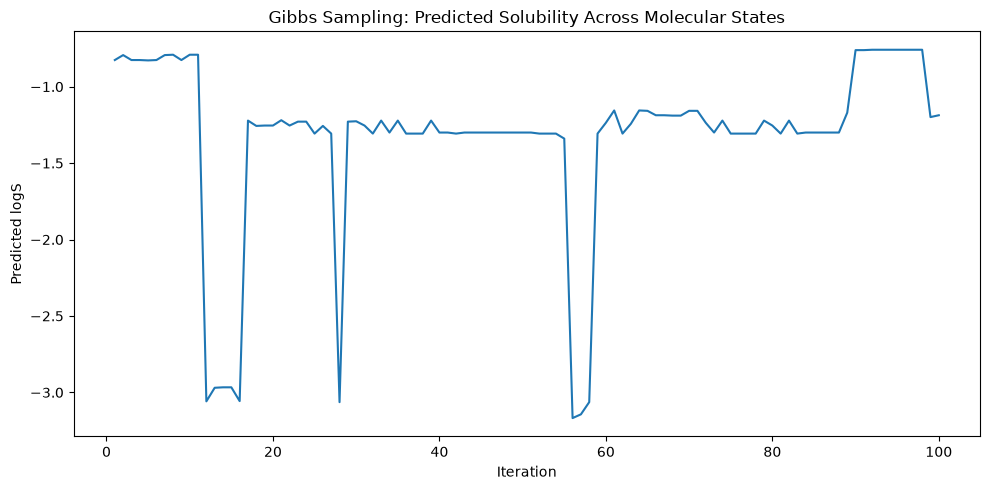

In [153]:
plt.figure(figsize=(10, 5))

plt.plot(
    chain_df["Iteration"],
    chain_df["Predicted_logS"]
)

plt.xlabel("Iteration")
plt.ylabel("Predicted logS")

plt.title(
    "Gibbs Sampling: Predicted Solubility Across Molecular States"
)

plt.tight_layout()

plt.show()

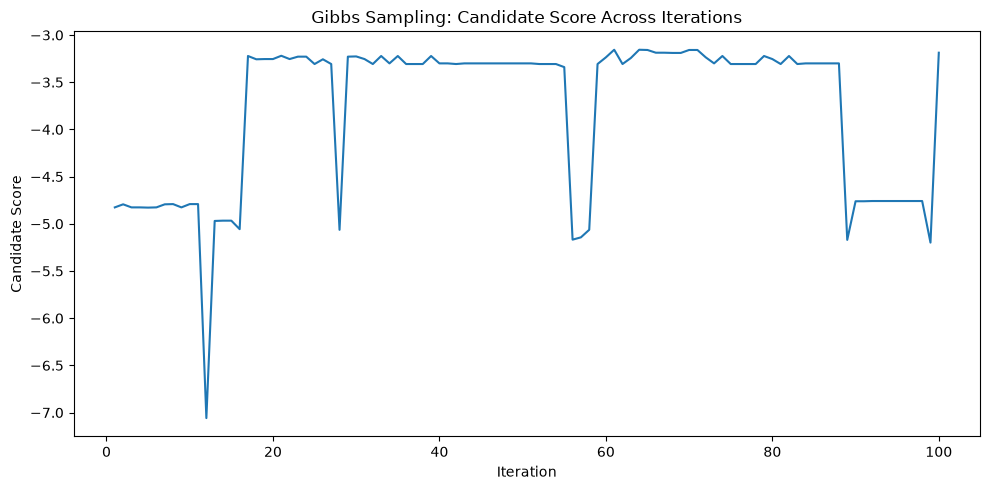

In [154]:
plt.figure(figsize=(10, 5))

plt.plot(
    chain_df["Iteration"],
    chain_df["Candidate_Score"]
)

plt.xlabel("Iteration")
plt.ylabel("Candidate Score")

plt.title(
    "Gibbs Sampling: Candidate Score Across Iterations"
)

plt.tight_layout()

plt.show()

In [155]:
chain_path = os.path.join(
    PROJECT_PATH,
    "results",
    "candidates",
    "gibbs_sampling_chain.csv"
)

chain_df.to_csv(
    chain_path,
    index=False
)

print(
    "Gibbs sampling chain saved to:"
)

print(chain_path)

Gibbs sampling chain saved to:
c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\results\candidates\gibbs_sampling_chain.csv


## Phase 8C — Candidate Ranking.

In [156]:
# Phase 8C: Rank sampled molecular candidates

top_candidates = (
    chain_df
    .sort_values(
        "Candidate_Score",
        ascending=False
    )
    .drop_duplicates(
        subset=["SMILES"]
    )
    .head(10)
)

display(
    top_candidates[
        [
            "SMILES",
            "Predicted_logS",
            "Candidate_Score",
            "Lipinski_Violations",
            "MolecularWeight",
            "LogP",
            "TPSA",
            "HBD",
            "HBA",
            "RotatableBonds",
            "RingCount"
        ]
    ]
)

,SMILES,Predicted_logS,Candidate_Score,Lipinski_Violations,MolecularWeight,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount
63,C#CN(CN1OC(OOC2NN(NC)C(C)N(O)N2N)N(C)N(C)C1N)c...,-1.155725,-3.155725,1,457.460,-4.51280,198.26,5,19,7,3
60,C#CN(CN1OC(OOC2CN(NC)C(O)N(O)N2N)N(C)N(C)C1N)c...,-1.155725,-3.155725,1,457.456,-4.44000,193.57,5,18,7,3
69,C#CN(CN1OC(OCC2NN(NC)C(C)C(O)N2N)C(C)N(C)C1N)c...,-1.158159,-3.158159,1,454.500,-4.66800,195.44,5,17,7,3
64,C#CN(CN1OC(OOC2NN(NC)C(C)C(O)N2N)N(C)N(C)C1N)c...,-1.158159,-3.158159,1,456.472,-4.75810,195.02,5,18,7,3
70,C#CN(CN1ON(OCC2NN(NC)C(C)C(O)N2N)C(C)N(C)C1N)c...,-1.158159,-3.158159,1,455.488,-4.90460,198.68,5,18,7,3
65,C#CN(CN1OC(OOC2NN(NC)C(C)C(O)N2N)N(C)N(C)C1N)c...,-1.187028,-3.187028,1,457.460,-5.36310,207.91,5,19,7,3
99,CON1OC(ONN2ON(CN(C#N)c3cnncn3)C(N)N(C)C2O)C(O)...,-1.187028,-3.187028,1,459.428,-4.55822,223.35,5,19,7,3
66,CNN1NC(OOC2ON(CN(C#N)c3nnnnn3)C(N)N(C)N2C)N(N)...,-1.187028,-3.187028,1,458.448,-5.47272,231.70,5,20,7,3
67,CNN1NC(COC2ON(CN(C#N)c3nnnnn3)C(N)N(C)N2C)N(N)...,-1.189462,-3.189462,1,456.476,-5.36182,222.47,5,19,7,3
68,CNN1NC(COC2ON(CN(C#N)c3nnnnn3)C(N)N(C)C2C)N(N)...,-1.189462,-3.189462,1,455.488,-4.77762,219.23,5,18,7,3


In [157]:
# Phase 8C: Candidate diversity analysis

candidate_analysis = chain_df.drop_duplicates(
    subset=["SMILES"]
).copy()

print("Unique candidate molecules:", len(candidate_analysis))

print("\nPredicted logS range:")
print(
    candidate_analysis["Predicted_logS"].min(),
    "to",
    candidate_analysis["Predicted_logS"].max()
)

print("\nCandidate Score range:")
print(
    candidate_analysis["Candidate_Score"].min(),
    "to",
    candidate_analysis["Candidate_Score"].max()
)

print("\nLipinski violations:")
print(
    candidate_analysis["Lipinski_Violations"]
    .value_counts()
    .sort_index()
)

print("\nMolecular Weight range:")
print(
    candidate_analysis["MolecularWeight"].min(),
    "to",
    candidate_analysis["MolecularWeight"].max()
)

print("\nLogP range:")
print(
    candidate_analysis["LogP"].min(),
    "to",
    candidate_analysis["LogP"].max()
)

Unique candidate molecules: 99

Predicted logS range:
-3.167884349822998 to -0.758619487285614

Candidate Score range:
-7.058467864990234 to -3.15572452545166

Lipinski violations:
Lipinski_Violations
1    76
2    23
Name: count, dtype: int64

Molecular Weight range:
450.5520000000002 to 460.41600000000017

LogP range:
-5.587919999999997 to -0.5791999999999962


In [158]:
# Phase 8C: Inspect candidates with highest predicted solubility

best_logS_candidates = (
    candidate_analysis
    .sort_values(
        "Predicted_logS",
        ascending=False
    )
    .drop_duplicates(
        subset=["SMILES"]
    )
    .head(15)
)

display(
    best_logS_candidates[
        [
            "SMILES",
            "Predicted_logS",
            "Candidate_Score",
            "Lipinski_Violations",
            "MolecularWeight",
            "LogP",
            "TPSA",
            "HBD",
            "HBA",
            "RotatableBonds",
            "RingCount"
        ]
    ]
)

,SMILES,Predicted_logS,Candidate_Score,Lipinski_Violations,MolecularWeight,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount
97,CON1NC(ONN2ON(NN(C#N)c3cnncn3)C(N)N(C)C2O)C(O)...,-0.758619,-4.758619,2,459.432,-5.52312,238.18,7,20,7,3
91,CNN1NC(OON2OC(NC(C#N)c3cnncn3)C(O)N(C)C2O)C(N)...,-0.758619,-4.758619,2,457.456,-4.92432,231.70,7,18,7,3
95,CNN1NC(ONN2ON(NC(C#N)c3cnncn3)C(N)N(C)C2O)C(O)...,-0.758619,-4.758619,2,457.460,-5.58792,237.74,8,19,7,3
94,CNN1NC(OON2ON(NC(C#N)c3cnncn3)C(N)N(C)C2O)C(O)...,-0.758619,-4.758619,2,458.444,-5.16092,234.94,7,19,7,3
96,CON1NC(ONN2ON(NC(C#N)c3cnncn3)C(N)N(C)C2O)C(O)...,-0.758619,-4.758619,2,458.444,-5.16092,234.94,7,19,7,3
92,CNN1NC(OON2OC(NC(C#N)c3cnncn3)C(O)N(C)C2O)C(O)...,-0.758619,-4.758619,2,458.440,-4.89072,225.91,7,18,7,3
93,CNN1NC(OON2OC(NC(C#N)c3cnncn3)C(N)N(C)C2O)C(O)...,-0.758619,-4.758619,2,457.456,-4.92432,231.70,7,18,7,3
89,CNN1NC(CON2OC(NC(C#N)c3cnncn3)C(N)N(C)C2O)C(N)...,-0.761054,-4.761054,2,454.500,-4.84702,228.26,7,17,7,3
90,CNN1NC(CON2OC(NC(C#N)c3cnncn3)C(O)N(C)C2O)C(N)...,-0.761054,-4.761054,2,455.484,-4.81342,222.47,7,17,7,3
10,C#CC(CC1CN(OOC2OC(CO)N(O)C(N)C2O)C(O)N(O)C1O)c...,-0.791129,-4.791129,2,457.440,-2.71940,197.70,7,14,7,3


In [159]:
# Phase 8C: Lipinski-based candidate filtering

filtered_candidates = candidate_analysis[
    (candidate_analysis["MolecularWeight"] <= 500) &
    (candidate_analysis["LogP"] <= 5) &
    (candidate_analysis["HBD"] <= 5) &
    (candidate_analysis["HBA"] <= 10)
].copy()

print("Candidates before filtering:", len(candidate_analysis))
print("Candidates after Lipinski filtering:", len(filtered_candidates))

if len(filtered_candidates) > 0:
    print("\nBest predicted logS after filtering:")
    print(filtered_candidates["Predicted_logS"].max())

    display(
        filtered_candidates
        .sort_values("Predicted_logS", ascending=False)
        .head(10)[
            [
                "SMILES",
                "Predicted_logS",
                "Candidate_Score",
                "Lipinski_Violations",
                "MolecularWeight",
                "LogP",
                "TPSA",
                "HBD",
                "HBA",
                "RotatableBonds",
                "RingCount"
            ]
        ]
    )
else:
    print("\nNo candidates passed all Lipinski filters.")

Candidates before filtering: 99
Candidates after Lipinski filtering: 0

No candidates passed all Lipinski filters.


In [160]:
# Phase 8C: Calculate detailed drug-likeness penalty

ranking_df = candidate_analysis.copy()

# Individual penalties
ranking_df["HBD_Excess"] = np.maximum(
    ranking_df["HBD"] - 5, 0
)

ranking_df["HBA_Excess"] = np.maximum(
    ranking_df["HBA"] - 10, 0
)

ranking_df["MW_Excess"] = np.maximum(
    ranking_df["MolecularWeight"] - 500, 0
)

ranking_df["LogP_Excess"] = np.maximum(
    ranking_df["LogP"] - 5, 0
)

# Total excess beyond Lipinski thresholds
ranking_df["Total_Excess"] = (
    ranking_df["HBD_Excess"] +
    ranking_df["HBA_Excess"] +
    ranking_df["MW_Excess"] +
    ranking_df["LogP_Excess"]
)

display(
    ranking_df[
        [
            "SMILES",
            "Predicted_logS",
            "HBD",
            "HBA",
            "MolecularWeight",
            "LogP",
            "HBD_Excess",
            "HBA_Excess",
            "Total_Excess"
        ]
    ]
    .sort_values(
        ["Total_Excess", "Predicted_logS"],
        ascending=[True, False]
    )
    .head(10)
)

,SMILES,Predicted_logS,HBD,HBA,MolecularWeight,LogP,HBD_Excess,HBA_Excess,Total_Excess
12,C#CC(CC1CN(OOC2OC(CO)N(O)C(N)C2O)C(C)N(O)C1C)c...,-2.969604,5,12,453.496,-0.57920,0,2,2.0
13,C#CC(CC1CN(OOC2OC(CO)N(O)C(N)C2O)C(C)N(O)C1C)c...,-2.966660,5,13,454.484,-1.18420,0,3,3.0
14,C#CC(CC1CN(OOC2OC(CN)N(O)C(N)C2O)C(C)N(O)C1C)c...,-2.966660,5,13,453.500,-1.21780,0,3,3.0
1,N#CC(CC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.793563,7,12,456.448,-2.88612,2,2,4.0
36,CNC1OC(CON2CC(NN(C#N)c3cccnn3)C(C)N(C)C2N)N(N)...,-1.307069,4,14,450.552,-2.24012,0,4,4.0
15,C#CC(CC1CN(OOC2OC(CN)N(O)C(N)C2O)C(C)N(O)C1C)c...,-3.056844,5,14,454.488,-1.82280,0,4,4.0
11,C#CC(CC1CN(OOC2OC(CO)N(O)C(N)C2O)C(C)N(O)C1O)c...,-3.058468,6,13,455.468,-1.64930,1,3,4.0
56,C#CN(CN1OC(OOC2CN(NC)C(C)N(C)N2N)N(C)N(C)C1C)c...,-3.143462,2,14,451.536,-1.42060,0,4,4.0
0,N#CC(OC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.825960,7,13,458.420,-3.34462,2,3,5.0
2,N#CC(CC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.825960,7,13,457.436,-3.49112,2,3,5.0


In [161]:

# Phase 8C: Final candidate ranking (revised)

import numpy as np
import pandas as pd

ranking_df = candidate_analysis.copy()

# 1. Count Lipinski threshold violations
ranking_df["HBD_Violation"] = ranking_df["HBD"] > 5
ranking_df["HBA_Violation"] = ranking_df["HBA"] > 10
ranking_df["MW_Violation"] = ranking_df["MolecularWeight"] > 500
ranking_df["LogP_Violation"] = ranking_df["LogP"] > 5

violation_cols = [
    "HBD_Violation",
    "HBA_Violation",
    "MW_Violation",
    "LogP_Violation"
]

ranking_df["Lipinski_Violations"] = (
    ranking_df[violation_cols].sum(axis=1)
)

# 2. Absolute compliance score: 1 means no violations
ranking_df["Druglikeness_Score"] = (
    1 - ranking_df["Lipinski_Violations"] / 4
)

# 3. Normalize predicted solubility within this candidate set
logS_min = ranking_df["Predicted_logS"].min()
logS_max = ranking_df["Predicted_logS"].max()

if logS_max == logS_min:
    ranking_df["Solubility_Score"] = 1.0
else:
    ranking_df["Solubility_Score"] = (
        (ranking_df["Predicted_logS"] - logS_min)
        / (logS_max - logS_min)
    )

# 4. Combined score: 60% solubility, 40% compliance
ranking_df["Final_Ranking_Score"] = (
    0.60 * ranking_df["Solubility_Score"]
    + 0.40 * ranking_df["Druglikeness_Score"]
)

# 5. Remove duplicate SMILES and rank candidates
final_candidates = (
    ranking_df
    .sort_values(
        "Final_Ranking_Score",
        ascending=False
    )
    .drop_duplicates("SMILES")
    .head(10)
    .copy()
)

final_candidates.insert(0, "Rank", range(1, len(final_candidates) + 1))

display(
    final_candidates[
        [
            "Rank",
            "SMILES",
            "Predicted_logS",
            "Lipinski_Violations",
            "Solubility_Score",
            "Druglikeness_Score",
            "Final_Ranking_Score",
            "MolecularWeight",
            "LogP",
            "TPSA",
            "HBD",
            "HBA",
            "RotatableBonds",
            "RingCount"
        ]
    ]
)


,Rank,SMILES,Predicted_logS,Lipinski_Violations,Solubility_Score,Druglikeness_Score,Final_Ranking_Score,MolecularWeight,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount
60,1,C#CN(CN1OC(OOC2CN(NC)C(O)N(O)N2N)N(C)N(C)C1N)c...,-1.155725,1,0.835176,0.75,0.801106,457.456,-4.44000,193.57,5,18,7,3
63,2,C#CN(CN1OC(OOC2NN(NC)C(C)N(O)N2N)N(C)N(C)C1N)c...,-1.155725,1,0.835176,0.75,0.801106,457.460,-4.51280,198.26,5,19,7,3
64,3,C#CN(CN1OC(OOC2NN(NC)C(C)C(O)N2N)N(C)N(C)C1N)c...,-1.158159,1,0.834165,0.75,0.800499,456.472,-4.75810,195.02,5,18,7,3
69,4,C#CN(CN1OC(OCC2NN(NC)C(C)C(O)N2N)C(C)N(C)C1N)c...,-1.158159,1,0.834165,0.75,0.800499,454.500,-4.66800,195.44,5,17,7,3
70,5,C#CN(CN1ON(OCC2NN(NC)C(C)C(O)N2N)C(C)N(C)C1N)c...,-1.158159,1,0.834165,0.75,0.800499,455.488,-4.90460,198.68,5,18,7,3
92,6,CNN1NC(OON2OC(NC(C#N)c3cnncn3)C(O)N(C)C2O)C(O)...,-0.758619,2,1.000000,0.50,0.800000,458.440,-4.89072,225.91,7,18,7,3
95,7,CNN1NC(ONN2ON(NC(C#N)c3cnncn3)C(N)N(C)C2O)C(O)...,-0.758619,2,1.000000,0.50,0.800000,457.460,-5.58792,237.74,8,19,7,3
96,8,CON1NC(ONN2ON(NC(C#N)c3cnncn3)C(N)N(C)C2O)C(O)...,-0.758619,2,1.000000,0.50,0.800000,458.444,-5.16092,234.94,7,19,7,3
97,9,CON1NC(ONN2ON(NN(C#N)c3cnncn3)C(N)N(C)C2O)C(O)...,-0.758619,2,1.000000,0.50,0.800000,459.432,-5.52312,238.18,7,20,7,3
94,10,CNN1NC(OON2ON(NC(C#N)c3cnncn3)C(N)N(C)C2O)C(O)...,-0.758619,2,1.000000,0.50,0.800000,458.444,-5.16092,234.94,7,19,7,3


In [162]:

# Save the revised top 10 candidates
output_path = (
    "../results/candidates/top_10_candidates.csv"
)

final_candidates.to_csv(output_path, index=False)

print(f"Saved {len(final_candidates)} candidates to {output_path}")

Saved 10 candidates to ../results/candidates/top_10_candidates.csv


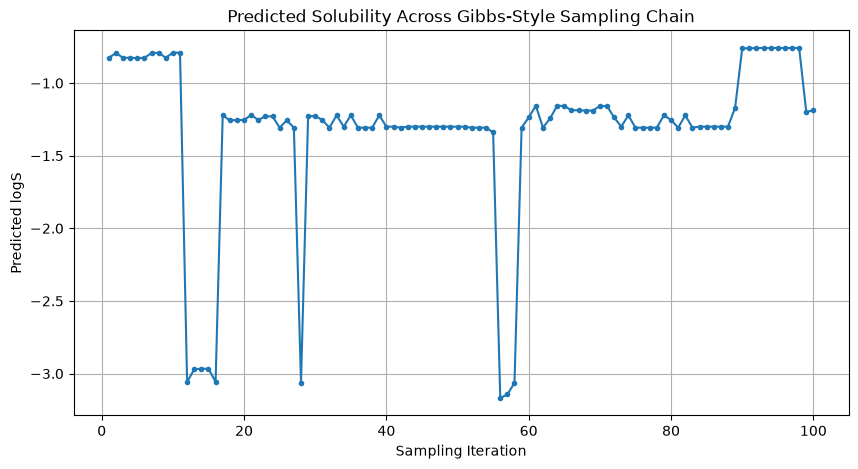

In [163]:
# Phase 8C: Predicted logS across Gibbs-style sampling iterations

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    chain_df["Iteration"],
    chain_df["Predicted_logS"],
    marker="o",
    markersize=3
)

plt.xlabel("Sampling Iteration")
plt.ylabel("Predicted logS")
plt.title("Predicted Solubility Across Gibbs-Style Sampling Chain")
plt.grid(True)

plt.show()

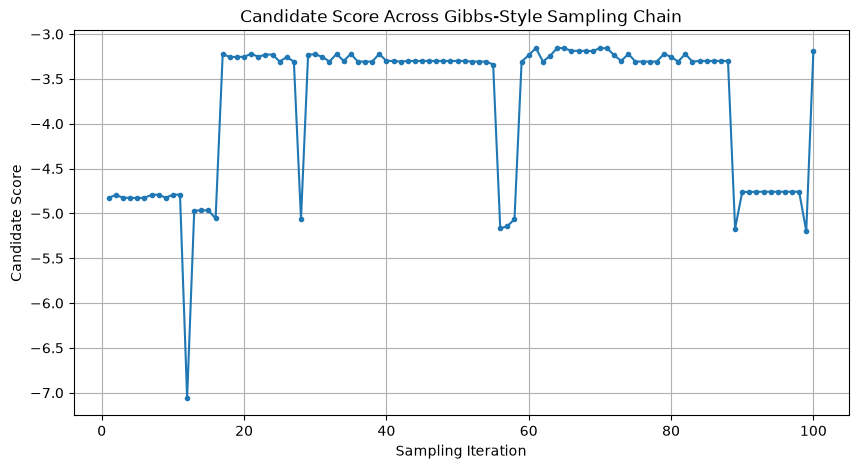

In [164]:
# Candidate score across sampling iterations

plt.figure(figsize=(10, 5))

plt.plot(
    chain_df["Iteration"],
    chain_df["Candidate_Score"],
    marker="o",
    markersize=3
)

plt.xlabel("Sampling Iteration")
plt.ylabel("Candidate Score")
plt.title("Candidate Score Across Gibbs-Style Sampling Chain")
plt.grid(True)

plt.show()

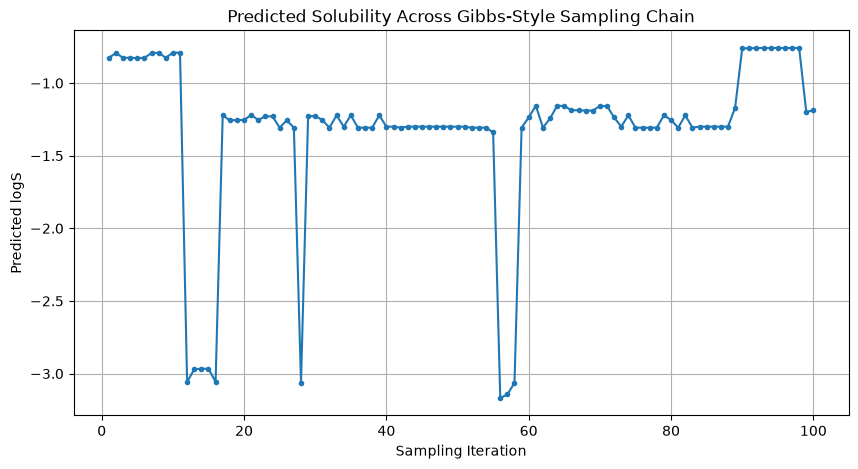

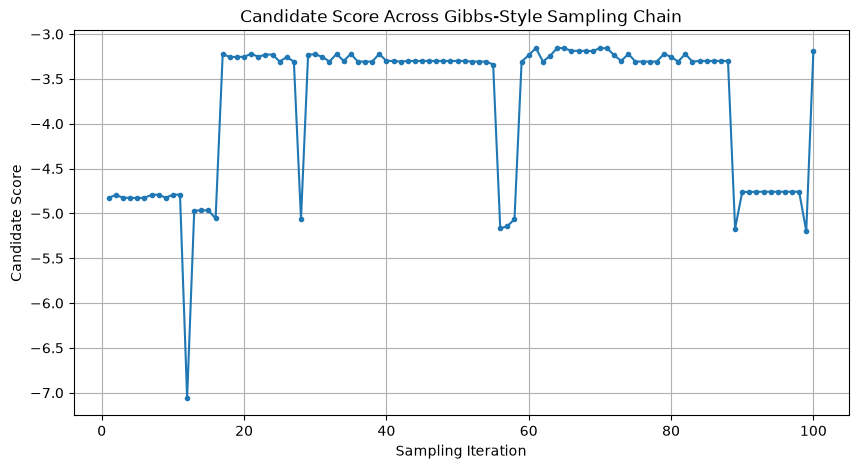

Figures saved successfully.


In [165]:
# Save Phase 8C visualizations

fig1_path = os.path.join(
    PROJECT_PATH,
    "results",
    "figures",
    "gibbs_predicted_logS.png"
)

fig2_path = os.path.join(
    PROJECT_PATH,
    "results",
    "figures",
    "gibbs_candidate_score.png"
)

# Predicted logS plot
plt.figure(figsize=(10, 5))
plt.plot(
    chain_df["Iteration"],
    chain_df["Predicted_logS"],
    marker="o",
    markersize=3
)
plt.xlabel("Sampling Iteration")
plt.ylabel("Predicted logS")
plt.title("Predicted Solubility Across Gibbs-Style Sampling Chain")
plt.grid(True)
plt.savefig(fig1_path, dpi=300, bbox_inches="tight")
plt.show()

# Candidate score plot
plt.figure(figsize=(10, 5))
plt.plot(
    chain_df["Iteration"],
    chain_df["Candidate_Score"],
    marker="o",
    markersize=3
)
plt.xlabel("Sampling Iteration")
plt.ylabel("Candidate Score")
plt.title("Candidate Score Across Gibbs-Style Sampling Chain")
plt.grid(True)
plt.savefig(fig2_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figures saved successfully.")

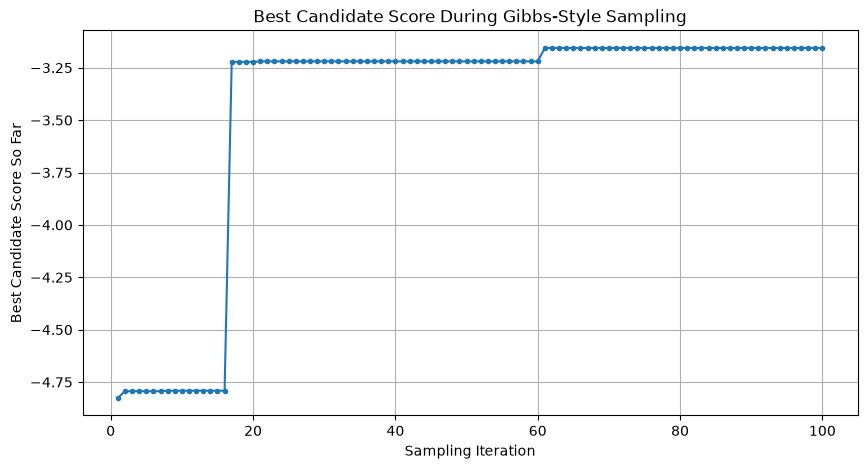

In [166]:
# Phase 8C: Best candidate score observed up to each iteration

chain_df["Best_Score_So_Far"] = (
    chain_df["Candidate_Score"]
    .cummax()
)

plt.figure(figsize=(10, 5))

plt.plot(
    chain_df["Iteration"],
    chain_df["Best_Score_So_Far"],
    marker="o",
    markersize=3
)

plt.xlabel("Sampling Iteration")
plt.ylabel("Best Candidate Score So Far")
plt.title("Best Candidate Score During Gibbs-Style Sampling")
plt.grid(True)

plt.show()

## Phase9

In [167]:
# ============================================================
# PHASE 9A: FINAL PROJECT RESULTS
# Save all important Phase 8 outputs
# ============================================================

import os
import pandas as pd

# Create final results folders
final_results_path = os.path.join(
    PROJECT_PATH,
    "results",
    "candidates"
)

metrics_path = os.path.join(
    PROJECT_PATH,
    "results",
    "metrics"
)

figures_path = os.path.join(
    PROJECT_PATH,
    "results",
    "figures"
)

os.makedirs(final_results_path, exist_ok=True)
os.makedirs(metrics_path, exist_ok=True)
os.makedirs(figures_path, exist_ok=True)


# ------------------------------------------------------------
# 1. Save complete Gibbs-style sampling chain
# ------------------------------------------------------------

chain_path = os.path.join(
    final_results_path,
    "gibbs_sampling_chain.csv"
)

chain_df.to_csv(
    chain_path,
    index=False
)


# ------------------------------------------------------------
# 2. Save final Top-10 candidates
# ------------------------------------------------------------

top10_path = os.path.join(
    final_results_path,
    "top_10_candidates.csv"
)

final_candidates.to_csv(
    top10_path,
    index=False
)


# ------------------------------------------------------------
# 3. Save candidate analysis
# ------------------------------------------------------------

analysis_path = os.path.join(
    final_results_path,
    "candidate_analysis.csv"
)

ranking_df.to_csv(
    analysis_path,
    index=False
)


# ------------------------------------------------------------
# 4. Save project summary metrics
# ------------------------------------------------------------

project_summary = pd.DataFrame({
    "Metric": [
        "Dataset molecules after cleaning",
        "Molecular fingerprint size",
        "Training samples",
        "Validation samples",
        "Test samples",
        "Best model",
        "XGBoost Test MAE",
        "XGBoost Test RMSE",
        "XGBoost Test R2",
        "Gibbs-style sampling iterations",
        "Unique sampled molecules",
        "Unique molecule percentage",
        "Lipinski-compliant sampled molecules"
    ],

    "Value": [
        len(df_clean),
        2048,
        len(X_desc_train),
        len(X_desc_val),
        len(X_desc_test),
        "XGBoost",
        0.517222,
        0.683086,
        0.896091,
        len(chain_df),
        chain_df["SMILES"].nunique(),
        round(
            100 * chain_df["SMILES"].nunique() / len(chain_df),
            2
        ),
        len(filtered_candidates)
    ]
})

summary_path = os.path.join(
    metrics_path,
    "final_project_summary.csv"
)

project_summary.to_csv(
    summary_path,
    index=False
)


print("==============================================")
print("PHASE 9A RESULTS SAVED SUCCESSFULLY")
print("==============================================")

print("\nSampling chain:")
print(chain_path)

print("\nTop-10 candidates:")
print(top10_path)

print("\nCandidate analysis:")
print(analysis_path)

print("\nProject summary:")
print(summary_path)

PHASE 9A RESULTS SAVED SUCCESSFULLY

Sampling chain:
c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\results\candidates\gibbs_sampling_chain.csv

Top-10 candidates:
c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\results\candidates\top_10_candidates.csv

Candidate analysis:
c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\results\candidates\candidate_analysis.csv

Project summary:
c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\results\metrics\final_project_summary.csv


In [168]:
# ============================================================
# PHASE 9B: CREATE STREAMLIT APPLICATION
# ============================================================

import os

APP_PATH = os.path.join(
    PROJECT_PATH,
    "app"
)

os.makedirs(APP_PATH, exist_ok=True)

streamlit_file = os.path.join(
    APP_PATH,
    "streamlit_app.py"
)

app_code = r'''
import os
import joblib
import pandas as pd
import streamlit as st

from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen, Lipinski
from rdkit.Chem import Draw


# ============================================================
# PROJECT PATH
# ============================================================

PROJECT_PATH = os.path.dirname(
    os.path.dirname(
        os.path.abspath(__file__)
    )
)


# ============================================================
# LOAD MODEL
# ============================================================

MODEL_PATH = os.path.join(
    PROJECT_PATH,
    "models",
    "xgboost_solubility_model.pkl"
)

TOP10_PATH = os.path.join(
    PROJECT_PATH,
    "results",
    "candidates",
    "top_10_candidates.csv"
)


@st.cache_resource
def load_model():

    model = joblib.load(MODEL_PATH)

    return model


@st.cache_data
def load_candidates():

    if os.path.exists(TOP10_PATH):

        return pd.read_csv(TOP10_PATH)

    return pd.DataFrame()


model = load_model()

top_candidates = load_candidates()


# ============================================================
# PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="AI Drug Candidate Discovery",
    page_icon="🧬",
    layout="wide"
)


# ============================================================
# TITLE
# ============================================================

st.title(
    "🧬 AI-Driven Drug Candidate Discovery"
)

st.markdown(
    """
    **Machine Learning + Molecular Descriptors + Gibbs-Style
    Molecular Sampling**

    This application predicts aqueous solubility (`logS`) and
    displays computationally prioritized molecular candidates.
    """
)


st.divider()


# ============================================================
# SMILES INPUT
# ============================================================

st.header("1. Molecular Solubility Prediction")

smiles = st.text_input(
    "Enter a SMILES string",
    value="",
    placeholder="Example: CCO"
)


predict_button = st.button(
    "🔬 Predict Molecule",
    type="primary"
)


# ============================================================
# MOLECULAR ANALYSIS
# ============================================================

if predict_button:

    if not smiles.strip():

        st.warning(
            "Please enter a SMILES string."
        )

    else:

        mol = Chem.MolFromSmiles(
            smiles
        )

        if mol is None:

            st.error(
                "Invalid SMILES. Please enter a valid molecular structure."
            )

        else:

            # ------------------------------------------------
            # Canonical SMILES
            # ------------------------------------------------

            canonical_smiles = Chem.MolToSmiles(
                mol,
                canonical=True
            )

            # ------------------------------------------------
            # Molecular descriptors
            # ------------------------------------------------

            descriptors = {

                "MolecularWeight":
                    Descriptors.MolWt(mol),

                "LogP":
                    Crippen.MolLogP(mol),

                "TPSA":
                    Descriptors.TPSA(mol),

                "HBD":
                    Lipinski.NumHDonors(mol),

                "HBA":
                    Lipinski.NumHAcceptors(mol),

                "RotatableBonds":
                    Lipinski.NumRotatableBonds(mol),

                "RingCount":
                    Lipinski.RingCount(mol)
            }

            # ------------------------------------------------
            # Prediction
            # ------------------------------------------------

            X = pd.DataFrame(
                [descriptors]
            )

            predicted_logS = float(
                model.predict(X)[0]
            )

            # ------------------------------------------------
            # Lipinski violations
            # ------------------------------------------------

            violations = 0

            if descriptors["MolecularWeight"] > 500:
                violations += 1

            if descriptors["LogP"] > 5:
                violations += 1

            if descriptors["HBD"] > 5:
                violations += 1

            if descriptors["HBA"] > 10:
                violations += 1

            candidate_score = (
                predicted_logS -
                2.0 * violations
            )

            # =================================================
            # DISPLAY RESULTS
            # =================================================

            col1, col2 = st.columns(2)

            with col1:

                st.subheader(
                    "Molecule Structure"
                )

                image = Draw.MolToImage(
                    mol,
                    size=(400, 400)
                )

                st.image(
                    image
                )

            with col2:

                st.subheader(
                    "Prediction"
                )

                st.metric(
                    "Predicted logS",
                    f"{predicted_logS:.4f}"
                )

                st.metric(
                    "Candidate Score",
                    f"{candidate_score:.4f}"
                )

                st.metric(
                    "Lipinski Violations",
                    violations
                )


            # =================================================
            # DESCRIPTOR TABLE
            # =================================================

            st.subheader(
                "Molecular Descriptors"
            )

            descriptor_display = pd.DataFrame(
                {
                    "Property": list(
                        descriptors.keys()
                    ),
                    "Value": list(
                        descriptors.values()
                    )
                }
            )

            st.dataframe(
                descriptor_display,
                use_container_width=True,
                hide_index=True
            )


            # =================================================
            # CANONICAL SMILES
            # =================================================

            st.subheader(
                "Canonical SMILES"
            )

            st.code(
                canonical_smiles
            )


st.divider()


# ============================================================
# TOP 10 CANDIDATES
# ============================================================

st.header(
    "2. Top Computationally Prioritized Candidates"
)

st.caption(
    "These candidates were generated by the Gibbs-style "
    "molecular sampling experiment and ranked using the "
    "project's computational scoring strategy."
)


if not top_candidates.empty:

    display_columns = [
        "Rank",
        "Predicted_logS",
        "Total_Excess",
        "Final_Ranking_Score",
        "MolecularWeight",
        "LogP",
        "TPSA",
        "HBD",
        "HBA",
        "RotatableBonds",
        "RingCount"
    ]

    available_columns = [
        col
        for col in display_columns
        if col in top_candidates.columns
    ]

    st.dataframe(
        top_candidates[
            available_columns
        ],
        use_container_width=True,
        hide_index=True
    )

else:

    st.info(
        "Top candidate results are not available."
    )


# ============================================================
# DISCLAIMER
# ============================================================

st.divider()

st.caption(
    """
    ⚠️ This is a computational research prototype.
    Predictions and candidate rankings do not establish
    biological activity, safety, efficacy, or clinical suitability.
    Experimental validation and additional ADMET/binding studies
    would be required.
    """
)
'''

with open(
    streamlit_file,
    "w",
    encoding="utf-8"
) as f:

    f.write(app_code)


print("==============================================")
print("STREAMLIT APP CREATED")
print("==============================================")
print(streamlit_file)

STREAMLIT APP CREATED
c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\app\streamlit_app.py


In [169]:
print("Number of candidates:", len(ranking_df))
print(
    "Unique predicted logS values:",
    ranking_df["Predicted_logS"].nunique()
)
print(
    "Unique SMILES:",
    ranking_df["SMILES"].nunique()
)

print(
    ranking_df[
        ["SMILES", "Predicted_logS", "MolecularWeight",
         "LogP", "TPSA", "HBD", "HBA"]
    ].head(10).to_string(index=False)
)

Number of candidates: 99
Unique predicted logS values: 31
Unique SMILES: 99
                                               SMILES  Predicted_logS  MolecularWeight     LogP   TPSA  HBD  HBA
N#CC(OC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1       -0.825960          458.420 -3.34462 205.56    7   13
N#CC(CC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1       -0.793563          456.448 -2.88612 196.33    7   12
N#CC(CC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccncc1       -0.825960          457.436 -3.49112 209.22    7   13
N#CC(CC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)N(O)C1O)c1ccncc1       -0.825960          458.424 -3.24582 212.46    7   14
N#CC(CC1CN(COC2OC(CO)C(O)C(O)C2O)C(O)N(O)C1O)c1ccncc1       -0.828395          456.452 -2.92982 203.23    7   13
N#CC(CC1CN(COC2OC(NO)C(O)C(O)C2O)C(O)N(O)C1O)c1ccncc1       -0.825960          457.440 -2.98582 215.26    8   14
C#CC(CC1CN(COC2OC(NO)C(O)C(O)C2O)C(O)N(O)C1O)c1ccncc1       -0.793563          456.452 -2.87620 191.47    8   13
C#CC(CC1CN(COC2OC(NO

In [170]:
# Check whether descriptor combinations repeat
descriptor_cols = [
    "MolecularWeight",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "RotatableBonds",
    "RingCount"
]

print("Unique SMILES:", ranking_df["SMILES"].nunique())

print(
    "Unique descriptor combinations:",
    ranking_df[descriptor_cols].drop_duplicates().shape[0]
)

print("\nRepeated predicted solubility values:")
print(
    ranking_df["Predicted_logS"]
    .value_counts()
    .sort_values(ascending=False)
)

print("\nRepeated descriptor combinations:")
print(
    ranking_df.groupby(descriptor_cols, dropna=False)
    .size()
    .sort_values(ascending=False)
    .head(10)
)

Unique SMILES: 99
Unique descriptor combinations: 94

Repeated predicted solubility values:
Predicted_logS
-1.300171    18
-1.307069    17
-1.221971     7
-0.758619     7
-0.825960     5
-1.254369     5
-0.791129     3
-1.228870     3
-1.158159     3
-1.187028     3
-0.793563     2
-2.966660     2
-1.256803     2
-1.236359     2
-1.155725     2
-1.189462     2
-0.761054     2
-0.828395     1
-3.058468     1
-2.969604     1
-3.056844     1
-1.219537     1
-3.063742     1
-1.226435     1
-1.339836     1
-3.167884     1
-3.143462     1
-3.063340     1
-1.243257     1
-1.170230     1
-1.199099     1
Name: count, dtype: int64

Repeated descriptor combinations:
MolecularWeight  LogP      TPSA    HBD  HBA  RotatableBonds  RingCount
454.500          -3.25250  164.28  5    17   7               3            3
455.488          -3.48910  167.52  5    18   7               3            2
457.456          -4.92432  231.70  7    18   7               3            2
458.444          -5.16092  234.94  7 

In [171]:
import numpy as np
import pandas as pd
import joblib
from xgboost import XGBRegressor

# Load the saved model and scaler
model = XGBRegressor()
model.load_model(os.path.join(PROJECT_PATH, "models", "xgboost_solubility_model.json"))

scaler = joblib.load(os.path.join(PROJECT_PATH, "models", "descriptor_scaler.pkl"))

features = [
    "MolecularWeight",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "RotatableBonds",
    "RingCount"
]

# Prepare inputs
X = ranking_df[features].copy()
X_scaled = scaler.transform(X)

# Generate fresh predictions
fresh_predictions = model.predict(X_scaled)

print("Stored predictions — unique:", ranking_df["Predicted_logS"].nunique())
print("Fresh predictions — unique:", np.unique(np.round(fresh_predictions, 6)).size)

print("\nFirst 10 stored vs fresh predictions:")
print(pd.DataFrame({
    "Stored": ranking_df["Predicted_logS"].head(10).values,
    "Fresh": fresh_predictions[:10]
}).to_string(index=False))

print(
    "\nMaximum absolute difference:",
    np.max(np.abs(
        ranking_df["Predicted_logS"].to_numpy() - fresh_predictions
    ))
)

Stored predictions — unique: 31
Fresh predictions — unique: 31

First 10 stored vs fresh predictions:
   Stored     Fresh
-0.825960 -0.694185
-0.793563 -0.813242
-0.825960 -0.694185
-0.825960 -0.694185
-0.828395 -0.813242
-0.825960 -0.767386
-0.793563 -0.813242
-0.791129 -0.767386
-0.825960 -0.767386
-0.791129 -0.767386

Maximum absolute difference: 0.24071049690246582


In [172]:
from pathlib import Path

feature_file = Path(PROJECT_PATH) / "models" / "descriptor_feature_names.txt"

print("Feature names saved with model:")
print(feature_file.read_text())

print("\nFeature order used for fresh predictions:")
print(features)

print("\nScaler feature count:", scaler.n_features_in_)
print("Model feature count:", model.n_features_in_)

Feature names saved with model:
MolecularWeight
LogP
TPSA
HBD
HBA
RotatableBonds
RingCount


Feature order used for fresh predictions:
['MolecularWeight', 'LogP', 'TPSA', 'HBD', 'HBA', 'RotatableBonds', 'RingCount']

Scaler feature count: 7
Model feature count: 7


In [173]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from xgboost import XGBRegressor

project_path = Path.cwd()
if not (project_path / "models").is_dir():
    project_path = project_path.parent

model_path = project_path / "models" / "xgboost_solubility_model.json"
scaler_path = project_path / "models" / "descriptor_scaler.pkl"
candidate_path = project_path / "results" / "candidates" / "candidate_analysis.csv"
for required_path in (model_path, scaler_path, candidate_path):
    if not required_path.is_file():
        raise FileNotFoundError(f"Required project file not found: {required_path}")

ranking_df = pd.read_csv(candidate_path)
features = [
    "MolecularWeight", "LogP", "TPSA", "HBD", "HBA",
    "RotatableBonds", "RingCount"
]
scaler = joblib.load(scaler_path)
model = XGBRegressor()
model.load_model(str(model_path))

# Prediction A: scale the descriptors, then predict
X_scaled = scaler.transform(ranking_df[features])
pred_scaled = model.predict(X_scaled)

# Prediction B: predict using raw descriptors (diagnostic only)
pred_raw = model.predict(ranking_df[features])

print("Scaled predictions — unique:",
      np.unique(np.round(pred_scaled, 6)).size)

print("Raw-input predictions — unique:",
      
      np.unique(np.round(pred_raw, 6)).size)

print("\nFirst 5 predictions:")
print("Stored:       ",
      ranking_df["Predicted_logS"].head().round(6).tolist())
print("Scaled model: ",
      np.round(pred_scaled[:5], 6).tolist())
print("Raw-input:    ",
      np.round(pred_raw[:5], 6).tolist())

Scaled predictions — unique: 31
Raw-input predictions — unique: 22

First 5 predictions:
Stored:        [-0.82596, -0.793563, -0.82596, -0.82596, -0.828395]
Scaled model:  [-0.6941850185394287, -0.8132420182228088, -0.6941850185394287, -0.6941850185394287, -0.8132420182228088]
Raw-input:     [-0.564428985118866, -0.6376299858093262, -0.545973002910614, -0.564428985118866, -0.6376299858093262]


In [174]:
test_smiles = "CCO"

print("Sampler prediction:", predict_logS(test_smiles))
print("Dataset logS:", 1.1)

Sampler prediction: 0.875468909740448
Dataset logS: 1.1


In [175]:
print("Unique candidates:", candidate_analysis["SMILES"].nunique())
print(
    "Unique predicted logS values:",
    candidate_analysis["Predicted_logS"].nunique()
)

print(
    candidate_analysis[
        ["SMILES", "Predicted_logS", "MolecularWeight",
         "LogP", "TPSA", "HBD", "HBA"]
    ].head(10).to_string(index=False)
)

Unique candidates: 99
Unique predicted logS values: 31
                                               SMILES  Predicted_logS  MolecularWeight     LogP   TPSA  HBD  HBA
N#CC(OC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1       -0.825960          458.420 -3.34462 205.56    7   13
N#CC(CC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1       -0.793563          456.448 -2.88612 196.33    7   12
N#CC(CC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccncc1       -0.825960          457.436 -3.49112 209.22    7   13
N#CC(CC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)N(O)C1O)c1ccncc1       -0.825960          458.424 -3.24582 212.46    7   14
N#CC(CC1CN(COC2OC(CO)C(O)C(O)C2O)C(O)N(O)C1O)c1ccncc1       -0.828395          456.452 -2.92982 203.23    7   13
N#CC(CC1CN(COC2OC(NO)C(O)C(O)C2O)C(O)N(O)C1O)c1ccncc1       -0.825960          457.440 -2.98582 215.26    8   14
C#CC(CC1CN(COC2OC(NO)C(O)C(O)C2O)C(O)N(O)C1O)c1ccncc1       -0.793563          456.452 -2.87620 191.47    8   13
C#CC(CC1CN(COC2OC(NO)N(O)C(O)C2O)C(O)N(O)

In [176]:

from rdkit import Chem
import pandas as pd

validation_df = candidate_analysis.copy()

def validate_smiles(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return pd.Series({
            "Valid_SMILES": False,
            "Canonical_SMILES": None
        })

    try:
        Chem.SanitizeMol(mol)
        canonical = Chem.MolToSmiles(mol, canonical=True)
        return pd.Series({
            "Valid_SMILES": True,
            "Canonical_SMILES": canonical
        })
    except Exception:
        return pd.Series({
            "Valid_SMILES": False,
            "Canonical_SMILES": None
        })

validation_df[["Valid_SMILES", "Canonical_SMILES"]] = (
    validation_df["SMILES"].apply(validate_smiles)
)

validation_df["HBD_Violation"] = validation_df["HBD"] > 5
validation_df["HBA_Violation"] = validation_df["HBA"] > 10
validation_df["MW_Violation"] = validation_df["MolecularWeight"] > 500
validation_df["LogP_Violation"] = validation_df["LogP"] > 5

violation_cols = [
    "HBD_Violation", "HBA_Violation",
    "MW_Violation", "LogP_Violation"
]

validation_df["Lipinski_Violations"] = (
    validation_df[violation_cols].sum(axis=1)
)

print("Total candidates:", len(validation_df))
print("RDKit-valid candidates:",
      int(validation_df["Valid_SMILES"].sum()))
print("Unique canonical structures:",
      validation_df["Canonical_SMILES"].nunique())
print("\nLipinski violation counts:")
print(validation_df["Lipinski_Violations"].value_counts().sort_index())
print("\nCandidates with zero Lipinski violations:",
      int((validation_df["Lipinski_Violations"] == 0).sum()))


Total candidates: 99
RDKit-valid candidates: 99
Unique canonical structures: 99

Lipinski violation counts:
Lipinski_Violations
1    76
2    23
Name: count, dtype: int64

Candidates with zero Lipinski violations: 0


In [177]:

violation_cols = [
    "HBD_Violation",
    "HBA_Violation",
    "MW_Violation",
    "LogP_Violation"
]

print("Number of candidates violating each rule:\n")

for col in violation_cols:
    count = int(validation_df[col].sum())
    percentage = count / len(validation_df) * 100
    print(f"{col}: {count}/99 ({percentage:.1f}%)")

print("\nExample candidates with the fewest violations:")

display(
    validation_df.sort_values(
        ["Lipinski_Violations", "Predicted_logS"],
        ascending=[True, False]
    )[
        [
            "SMILES",
            "Predicted_logS",
            "Lipinski_Violations",
            "MolecularWeight",
            "LogP",
            "HBD",
            "HBA"
        ]
    ].head(10)
)


Number of candidates violating each rule:

HBD_Violation: 23/99 (23.2%)
HBA_Violation: 99/99 (100.0%)
MW_Violation: 0/99 (0.0%)
LogP_Violation: 0/99 (0.0%)

Example candidates with the fewest violations:


,SMILES,Predicted_logS,Lipinski_Violations,MolecularWeight,LogP,HBD,HBA
60,C#CN(CN1OC(OOC2CN(NC)C(O)N(O)N2N)N(C)N(C)C1N)c...,-1.155725,1,457.456,-4.44000,5,18
63,C#CN(CN1OC(OOC2NN(NC)C(C)N(O)N2N)N(C)N(C)C1N)c...,-1.155725,1,457.460,-4.51280,5,19
64,C#CN(CN1OC(OOC2NN(NC)C(C)C(O)N2N)N(C)N(C)C1N)c...,-1.158159,1,456.472,-4.75810,5,18
69,C#CN(CN1OC(OCC2NN(NC)C(C)C(O)N2N)C(C)N(C)C1N)c...,-1.158159,1,454.500,-4.66800,5,17
70,C#CN(CN1ON(OCC2NN(NC)C(C)C(O)N2N)C(C)N(C)C1N)c...,-1.158159,1,455.488,-4.90460,5,18
65,C#CN(CN1OC(OOC2NN(NC)C(C)C(O)N2N)N(C)N(C)C1N)c...,-1.187028,1,457.460,-5.36310,5,19
66,CNN1NC(OOC2ON(CN(C#N)c3nnnnn3)C(N)N(C)N2C)N(N)...,-1.187028,1,458.448,-5.47272,5,20
99,CON1OC(ONN2ON(CN(C#N)c3cnncn3)C(N)N(C)C2O)C(O)...,-1.187028,1,459.428,-4.55822,5,19
67,CNN1NC(COC2ON(CN(C#N)c3nnnnn3)C(N)N(C)N2C)N(N)...,-1.189462,1,456.476,-5.36182,5,19
68,CNN1NC(COC2ON(CN(C#N)c3nnnnn3)C(N)N(C)C2C)N(N)...,-1.189462,1,455.488,-4.77762,5,18


In [178]:

print("HBA distribution:")
print(
    validation_df["HBA"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nLowest-HBA candidates:")
display(
    validation_df.sort_values(
        ["HBA", "HBD", "Predicted_logS"],
        ascending=[True, True, False]
    )[
        [
            "SMILES",
            "HBA",
            "HBD",
            "MolecularWeight",
            "LogP",
            "Predicted_logS"
        ]
    ].head(10)
)


HBA distribution:
HBA
12     2
13     7
14     8
15    11
16    22
17    24
18    15
19     7
20     3

Lowest-HBA candidates:


,SMILES,HBA,HBD,MolecularWeight,LogP,Predicted_logS
12,C#CC(CC1CN(OOC2OC(CO)N(O)C(N)C2O)C(C)N(O)C1C)c...,12,5,453.496,-0.57920,-2.969604
1,N#CC(CC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,12,7,456.448,-2.88612,-0.793563
13,C#CC(CC1CN(OOC2OC(CO)N(O)C(N)C2O)C(C)N(O)C1C)c...,13,5,454.484,-1.18420,-2.966660
14,C#CC(CC1CN(OOC2OC(CN)N(O)C(N)C2O)C(C)N(O)C1C)c...,13,5,453.500,-1.21780,-2.966660
11,C#CC(CC1CN(OOC2OC(CO)N(O)C(N)C2O)C(C)N(O)C1O)c...,13,6,455.468,-1.64930,-3.058468
0,N#CC(OC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,13,7,458.420,-3.34462,-0.825960
2,N#CC(CC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,13,7,457.436,-3.49112,-0.825960
4,N#CC(CC1CN(COC2OC(CO)C(O)C(O)C2O)C(O)N(O)C1O)c...,13,7,456.452,-2.92982,-0.828395
6,C#CC(CC1CN(COC2OC(NO)C(O)C(O)C2O)C(O)N(O)C1O)c...,13,8,456.452,-2.87620,-0.793563
56,C#CN(CN1OC(OOC2CN(NC)C(C)N(C)N2N)N(C)N(C)C1C)c...,14,2,451.536,-1.42060,-3.143462


In [182]:
test_smiles = candidate_analysis.iloc[0]["SMILES"]
test_neighbors = generate_atom_substitutions(test_smiles)

print("Starting HBA:", Lipinski.NumHAcceptors(
    Chem.MolFromSmiles(test_smiles)
))
print("Neighbors generated:", len(test_neighbors))

for smi in test_neighbors[:10]:
    mol = Chem.MolFromSmiles(smi)
    print(
        smi,
        "| HBA:", Lipinski.NumHAcceptors(mol),
        "| HBD:", Lipinski.NumHDonors(mol)
    )

Starting HBA: 13
Neighbors generated: 24
C#CC(OC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1 | HBA: 12 | HBD: 7
CC1C(CO)OC(OCN2OC(OC(C#N)c3ccccc3)C(O)C(O)C2O)C(O)C1O | HBA: 12 | HBD: 6
CC1C(O)C(CO)OC(OCN2OC(OC(C#N)c3ccccc3)C(O)C(O)C2O)C1O | HBA: 12 | HBD: 6
CC1C(O)C(O)C(OC(C#N)c2ccccc2)ON1COC1OC(CO)C(O)C(O)C1O | HBA: 12 | HBD: 6
CC1C(O)C(OC(C#N)c2ccccc2)ON(COC2OC(CO)C(O)C(O)C2O)C1O | HBA: 12 | HBD: 6
CC1C(OC(C#N)c2ccccc2)ON(COC2OC(CO)C(O)C(O)C2O)C(O)C1O | HBA: 12 | HBD: 6
CC1C(OCN2OC(OC(C#N)c3ccccc3)C(O)C(O)C2O)OC(CO)C(O)C1O | HBA: 12 | HBD: 6
CCC1OC(OCN2OC(OC(C#N)c3ccccc3)C(O)C(O)C2O)C(O)C(O)C1O | HBA: 12 | HBD: 6
N#CC(CC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1 | HBA: 12 | HBD: 7
N#CC(NC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1 | HBA: 13 | HBD: 8


[16:55:08] Explicit valence for atom # 0 O, 3, is greater than permitted
[16:55:08] Explicit valence for atom # 1 N, 4, is greater than permitted
[16:55:08] Explicit valence for atom # 1 O, 4, is greater than permitted
[16:55:08] Explicit valence for atom # 2 O, 3, is greater than permitted
[16:55:08] Explicit valence for atom # 4 O, 3, is greater than permitted
[16:55:08] Explicit valence for atom # 6 O, 3, is greater than permitted
[16:55:08] Explicit valence for atom # 9 O, 3, is greater than permitted
[16:55:08] Explicit valence for atom # 11 O, 3, is greater than permitted
[16:55:08] Explicit valence for atom # 14 O, 3, is greater than permitted
[16:55:08] Explicit valence for atom # 16 O, 3, is greater than permitted
[16:55:08] Explicit valence for atom # 18 O, 3, is greater than permitted
[16:55:08] Explicit valence for atom # 20 O, 3, is greater than permitted
[16:55:08] Explicit valence for atom # 22 O, 3, is greater than permitted
[16:55:08] Explicit valence for atom # 24 O, 

In [183]:

from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors

def assess_molecule(smiles):
    """Check basic structure validity and drug-likeness properties."""
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    Chem.SanitizeMol(mol)

    return {
        "SMILES": Chem.MolToSmiles(mol, canonical=True),
        "MolecularWeight": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "HBA": Lipinski.NumHAcceptors(mol),
        "HBD": Lipinski.NumHDonors(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "Lipinski_Violations": sum([
            Descriptors.MolWt(mol) > 500,
            Descriptors.MolLogP(mol) > 5,
            Lipinski.NumHAcceptors(mol) > 10,
            Lipinski.NumHDonors(mol) > 5
        ])
    }

test_smiles = candidate_analysis.iloc[0]["SMILES"]
neighbors = generate_atom_substitutions(test_smiles)

records = [
    result
    for smi in neighbors
    if (result := assess_molecule(smi)) is not None
]

neighbor_df = pd.DataFrame(records)

print("Neighbors assessed:", len(neighbor_df))
if not neighbor_df.empty:
    print("\nViolation counts:")
    print(neighbor_df["Lipinski_Violations"].value_counts().sort_index())
    print("\nLowest HBA/HBD candidates:")
    print(
        neighbor_df.sort_values(["Lipinski_Violations", "HBA", "HBD"])
        [["SMILES", "HBA", "HBD", "MolecularWeight",
          "LogP", "Lipinski_Violations"]]
        .head(10).to_string(index=False)
    )


Neighbors assessed: 24

Violation counts:
Lipinski_Violations
2    24
Name: count, dtype: int64

Lowest HBA/HBD candidates:
                                               SMILES  HBA  HBD  MolecularWeight     LogP  Lipinski_Violations
CC1C(CO)OC(OCN2OC(OC(C#N)c3ccccc3)C(O)C(O)C2O)C(O)C1O   12    6          456.448 -2.06942                    2
CC1C(O)C(CO)OC(OCN2OC(OC(C#N)c3ccccc3)C(O)C(O)C2O)C1O   12    6          456.448 -2.06942                    2
CC1C(O)C(O)C(OC(C#N)c2ccccc2)ON1COC1OC(CO)C(O)C(O)C1O   12    6          456.448 -2.27452                    2
CC1C(O)C(OC(C#N)c2ccccc2)ON(COC2OC(CO)C(O)C(O)C2O)C1O   12    6          456.448 -2.06942                    2
CC1C(OC(C#N)c2ccccc2)ON(COC2OC(CO)C(O)C(O)C2O)C(O)C1O   12    6          456.448 -2.06942                    2
CC1C(OCN2OC(OC(C#N)c3ccccc3)C(O)C(O)C2O)OC(CO)C(O)C1O   12    6          456.448 -2.06942                    2
CCC1OC(OCN2OC(OC(C#N)c3ccccc3)C(O)C(O)C2O)C(O)C(O)C1O   12    6          456.448 -1.92692          

[16:56:05] Explicit valence for atom # 0 O, 3, is greater than permitted
[16:56:05] Explicit valence for atom # 1 N, 4, is greater than permitted
[16:56:05] Explicit valence for atom # 1 O, 4, is greater than permitted
[16:56:05] Explicit valence for atom # 2 O, 3, is greater than permitted
[16:56:05] Explicit valence for atom # 4 O, 3, is greater than permitted
[16:56:05] Explicit valence for atom # 6 O, 3, is greater than permitted
[16:56:05] Explicit valence for atom # 9 O, 3, is greater than permitted
[16:56:05] Explicit valence for atom # 11 O, 3, is greater than permitted
[16:56:05] Explicit valence for atom # 14 O, 3, is greater than permitted
[16:56:05] Explicit valence for atom # 16 O, 3, is greater than permitted
[16:56:05] Explicit valence for atom # 18 O, 3, is greater than permitted
[16:56:05] Explicit valence for atom # 20 O, 3, is greater than permitted
[16:56:05] Explicit valence for atom # 22 O, 3, is greater than permitted
[16:56:05] Explicit valence for atom # 24 O, 

In [184]:

from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors

start_smiles = candidate_analysis.iloc[0]["SMILES"]
mol = Chem.MolFromSmiles(start_smiles)

if mol is None:
    print("Starting SMILES is invalid")
else:
    print("Starting SMILES:", Chem.MolToSmiles(mol))
    print("Atoms:", mol.GetNumAtoms())
    print("Molecular weight:", round(Descriptors.MolWt(mol), 2))
    print("LogP:", round(Descriptors.MolLogP(mol), 2))
    print("HBA:", Lipinski.NumHAcceptors(mol))
    print("HBD:", Lipinski.NumHDonors(mol))
    print("TPSA:", round(rdMolDescriptors.CalcTPSA(mol), 2))
    print("Ring count:", rdMolDescriptors.CalcNumRings(mol))
    print("Formula:", rdMolDescriptors.CalcMolFormula(mol))


Starting SMILES: N#CC(OC1ON(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1
Atoms: 32
Molecular weight: 458.42
LogP: -3.34
HBA: 13
HBD: 7
TPSA: 205.56
Ring count: 3
Formula: C19H26N2O11


In [187]:
from pathlib import Path

import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors

# Find the project root from the notebook's current working directory.
project_root = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "data" / "processed" / "ESOL_clean.csv").is_file()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Could not find data/processed/ESOL_clean.csv "
        "in the current directory or its parent directories."
    )

data_path = project_root / "data" / "processed" / "ESOL_clean.csv"
df = pd.read_csv(data_path)


def inspect_smiles(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    return {
        "SMILES": Chem.MolToSmiles(mol, canonical=True),
        "MolecularWeight": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "HBA": Lipinski.NumHAcceptors(mol),
        "HBD": Lipinski.NumHDonors(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "RingCount": rdMolDescriptors.CalcNumRings(mol),
    }


records = [
    result
    for smiles in df["SMILES"].dropna()
    if (result := inspect_smiles(smiles)) is not None
]

properties = pd.DataFrame(records).drop_duplicates("SMILES")

# Select molecules meeting the four common Lipinski thresholds.
suitable = properties[
    (properties["MolecularWeight"] <= 500)
    & (properties["LogP"] <= 5)
    & (properties["HBA"] <= 10)
    & (properties["HBD"] <= 5)
].copy()

print("Loaded dataset:", data_path)
print("Valid unique molecules:", len(properties))
print("Molecules meeting all four thresholds:", len(suitable))
print(
    suitable.sort_values("MolecularWeight")
    .head(15)
    .to_string(index=False)
)

Loaded dataset: c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\data\processed\ESOL_clean.csv
Valid unique molecules: 1117
Molecules meeting all four thresholds: 1009
SMILES  MolecularWeight     LogP  HBA  HBD  TPSA  RingCount
     C           16.043  0.63610    0    0  0.00          0
   C#C           26.038  0.24940    0    0  0.00          0
   C=C           28.054  0.80220    0    0  0.00          0
    CC           30.070  1.02620    0    0  0.00          0
    CO           32.042 -0.39150    1    1 20.23          0
  C#CC           40.065  0.63950    0    0  0.00          0
  CC#N           41.053  0.52988    1    0 23.79          0
  C=CC           42.081  1.19230    0    0  0.00          0
   CCC           44.097  1.41630    0    0  0.00          0
   CCO           46.069 -0.00140    1    1 20.23          0
   CNN           46.073 -0.92050    2    2 38.05          0
C=CC#N           53.064  0.69598    1    0 2

In [188]:

# Reuse the `properties` DataFrame created in your previous cell.

starting_pool = properties[
    (properties["MolecularWeight"] >= 150) &
    (properties["MolecularWeight"] <= 450) &
    (properties["LogP"] >= -2) &
    (properties["LogP"] <= 5) &
    (properties["HBA"] <= 10) &
    (properties["HBD"] <= 5) &
    (properties["RingCount"] >= 1)
].copy()

print("Suitable starting molecules:", len(starting_pool))

# Show a range of structures rather than only the smallest molecules.
starting_pool = starting_pool.sort_values(
    ["MolecularWeight", "RingCount"],
    ascending=[False, False]
)

print(
    starting_pool[
        ["SMILES", "MolecularWeight", "LogP",
         "HBA", "HBD", "TPSA", "RingCount"]
    ].head(15).to_string(index=False)
)


Suitable starting molecules: 504
                                                       SMILES  MolecularWeight   LogP  HBA  HBD   TPSA  RingCount
         COc1cc2c(N)nc(N3CCN(C(=O)OCC(C)(C)O)CC3)nc2c(OC)c1OC          435.481 1.2673   10    2 132.50          3
 CC(=O)OCC(=O)C1(O)C(C)CC2C3CCC4=CC(=O)C=CC4(C)C3(F)C(O)CC21C          434.504 2.4665    6    2 100.90          4
CC1(C)OC2CC3C4CCC5=CC(=O)C=CC5(C)C4(F)C(O)CC3(C)C2(C(=O)CO)O1          434.504 2.4188    6    2  93.06          5
             O=CNC(N1C=CN(C(NC=O)C(Cl)(Cl)Cl)C=C1)C(Cl)(Cl)Cl          430.934 2.4310    4    2  64.68          1
                    CC(C)OC(=O)C(O)(c1ccc(Br)cc1)c1ccc(Br)cc1          428.120 4.3991    3    1  46.53          2
          NS(=O)(=O)c1cc2c(cc1C(F)(F)F)NC(Cc1ccccc1)NS2(=O)=O          421.422 1.6254    5    3 118.36          3
      CC(=O)SC1CC2=CC(=O)CCC2(C)C2CCC3(C)C(CCC34CCC(=O)O4)C12          416.583 4.8523    5    0  60.44          5
             CCOC(=O)c1ccccc1S(=O)(=O)NN(C=O)c1nc(Cl)cc

In [189]:

import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors

# Build descriptor rows for the selected starting molecules.
scoring_rows = []

for _, row in starting_pool.iterrows():
    smiles = row["SMILES"]
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        continue

    scoring_rows.append({
        "SMILES": smiles,
        "MolecularWeight": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "HBD": Lipinski.NumHDonors(mol),
        "HBA": Lipinski.NumHAcceptors(mol),
        "RotatableBonds": Descriptors.NumRotatableBonds(mol),
        "RingCount": rdMolDescriptors.CalcNumRings(mol)
    })

scoring_df = pd.DataFrame(scoring_rows)

# Match the exact feature order used when training the model.
X = scoring_df[descriptor_columns]
X_scaled = scaler.transform(X)

scoring_df["Predicted_logS"] = xgb_model.predict(X_scaled)

# Attach measured ESOL labels using canonical SMILES.
def canonicalize(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return Chem.MolToSmiles(mol, canonical=True) if mol else None

df["canonical_key"] = df["SMILES"].map(canonicalize)
scoring_df["canonical_key"] = scoring_df["SMILES"].map(canonicalize)

labels = (
    df.dropna(subset=["logS"])
      .drop_duplicates("canonical_key")
      .set_index("canonical_key")["logS"]
)

scoring_df["Measured_logS"] = scoring_df["canonical_key"].map(labels)
scoring_df["Absolute_Error"] = (
    scoring_df["Predicted_logS"] - scoring_df["Measured_logS"]
).abs()

print("Molecules scored:", len(scoring_df))
print("\nTop 15 by predicted solubility:")
print(
    scoring_df.sort_values("Predicted_logS", ascending=False)
    [["SMILES", "Predicted_logS", "Measured_logS",
      "Absolute_Error", "MolecularWeight", "LogP", "HBA", "HBD"]]
    .head(15).to_string(index=False)
)


Molecules scored: 504

Top 15 by predicted solubility:
                    SMILES  Predicted_logS  Measured_logS  Absolute_Error  MolecularWeight     LogP  HBA  HBD
  Cc1cc(=O)n(-c2ccccc2)n1C       -1.051211          0.715        1.766211          188.230  1.48442    1    0
          COc1cnc2ncncc2n1       -1.135933         -1.139        0.003067          162.152  0.42840    5    0
          COc1cnc2cncnc2n1       -1.135933         -0.910        0.225933          162.152  0.42840    5    0
          COc1ncnc2nccnc12       -1.135933         -1.110        0.025933          162.152  0.42840    5    0
          COc1ncc2nccnc2n1       -1.135933         -1.110        0.025933          162.152  0.42840    5    0
        O=Cc1ccc2c(c1)OCO2       -1.174149         -1.630        0.455851          150.133  1.22780    3    0
Cn1c(=O)c2c(ncn2C)n(C)c1=O       -1.256663         -0.876        0.380663          194.194 -1.02930    3    0
             Oc1ccc(Br)cc1       -1.289294         -1.090        

In [190]:

from pathlib import Path

project_dir = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "app" / "streamlit_app.py").is_file()
    ),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Could not locate the project root from the current working directory.")

output_dir = project_dir / "results" / "candidates"
output_dir.mkdir(parents=True, exist_ok=True)

scoring_df.to_csv(
    output_dir / "starting_molecules_scored.csv",
    index=False
)

print("Saved:", output_dir / "starting_molecules_scored.csv")


Saved: results\candidates\starting_molecules_scored.csv


In [191]:

start_smiles = "COc1cnc2ncncc2n1"

start_info = assess_molecule(start_smiles)
neighbors = generate_atom_substitutions(start_smiles)

print("Starting molecule:", start_smiles)
print("Starting HBA:", start_info["HBA"])
print("Starting HBD:", start_info["HBD"])
print("Neighbors generated:", len(neighbors))

neighbor_records = []

for smiles in neighbors:
    info = assess_molecule(smiles)

    if info is not None:
        neighbor_records.append(info)

neighbor_df = pd.DataFrame(neighbor_records)

if not neighbor_df.empty:
    print("\nNeighbor properties:")
    print(
        neighbor_df[
            ["SMILES", "MolecularWeight", "LogP",
             "HBA", "HBD", "TPSA"]
        ].to_string(index=False)
    )


Starting molecule: COc1cnc2ncncc2n1
Starting HBA: 5
Starting HBD: 0
Neighbors generated: 6

Neighbor properties:
          SMILES  MolecularWeight   LogP  HBA  HBD  TPSA
CCc1cnc2ncncc2n1          160.180 0.9822    4    0 51.56
CNc1cnc2ncncc2n1          161.168 0.4615    5    1 63.59
COc1ccc2ncncc2n1          161.164 1.0334    4    0 47.90
COc1cnc2ccncc2n1          161.164 1.0334    4    0 47.90
COc1cnc2ncccc2n1          161.164 1.0334    4    0 47.90
COc1cnc2ncncc2c1          161.164 1.0334    4    0 47.90


[17:09:07] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9 10 11
[17:09:07] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9 10 11
[17:09:07] Explicit valence for atom # 2 O, 4, is greater than permitted
[17:09:07] Can't kekulize mol.  Unkekulized atoms: 2 4 5 6 7 8 9 10 11
[17:09:07] Can't kekulize mol.  Unkekulized atoms: 2 4 5 6 7 8 9 10 11
[17:09:07] Can't kekulize mol.  Unkekulized atoms: 2 3 5 6 7 8 9 10 11
[17:09:07] Can't kekulize mol.  Unkekulized atoms: 2 3 5 6 7 8 9 10 11
[17:09:07] Can't kekulize mol.  Unkekulized atoms: 2 3 4 6 7 8 9 10 11
[17:09:07] Can't kekulize mol.  Unkekulized atoms: 2 3 4 6 7 8 9 10 11
[17:09:07] Explicit valence for atom # 5 O, 5, is greater than permitted
[17:09:07] Can't kekulize mol.  Unkekulized atoms: 2 3 4 5 7 8 9 10 11
[17:09:07] Can't kekulize mol.  Unkekulized atoms: 2 3 4 5 7 8 9 10 11
[17:09:07] Can't kekulize mol.  Unkekulized atoms: 2 3 4 5 6 8 9 10 11
[17:09:07] Can't kekulize mol.  Unkekulized atoms: 2 3 4 5 6 8 9 10 11
[1

In [192]:

# Use the existing neighbor_df and trained XGBoost model/scaler.

descriptor_columns = [
    "MolecularWeight",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "RotatableBonds",
    "RingCount"
]

# Recalculate all seven model features from each SMILES.
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors

def model_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    return {
        "MolecularWeight": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "HBD": Lipinski.NumHDonors(mol),
        "HBA": Lipinski.NumHAcceptors(mol),
        "RotatableBonds": Descriptors.NumRotatableBonds(mol),
        "RingCount": Descriptors.RingCount(mol)
    }

rows = []
for smiles in neighbors:
    features = model_descriptors(smiles)
    if features is not None:
        rows.append({"SMILES": smiles, **features})

neighbor_scores = pd.DataFrame(rows)

X_neighbors = neighbor_scores[descriptor_columns]
X_neighbors_scaled = scaler.transform(X_neighbors)

neighbor_scores["Predicted_logS"] = xgb_model.predict(
    X_neighbors_scaled
)

print(
    neighbor_scores[
        ["SMILES", "Predicted_logS", "MolecularWeight",
         "LogP", "HBA", "HBD", "TPSA"]
    ]
    .sort_values("Predicted_logS", ascending=False)
    .to_string(index=False)
)


          SMILES  Predicted_logS  MolecularWeight   LogP  HBA  HBD  TPSA
CCc1cnc2ncncc2n1       -0.987447          160.180 0.9822    4    0 51.56
COc1ccc2ncncc2n1       -1.279046          161.164 1.0334    4    0 47.90
COc1cnc2ncccc2n1       -1.279046          161.164 1.0334    4    0 47.90
COc1cnc2ccncc2n1       -1.279046          161.164 1.0334    4    0 47.90
COc1cnc2ncncc2c1       -1.279046          161.164 1.0334    4    0 47.90
CNc1cnc2ncncc2n1       -1.492579          161.168 0.4615    5    1 63.59


In [193]:

import numpy as np

# Example scores for the six neighbors.
# These scores are illustrative until we normalize the full candidate pool.
predictions = neighbor_scores["Predicted_logS"].to_numpy()

min_logS = predictions.min()
max_logS = predictions.max()

if max_logS == min_logS:
    normalized = np.ones(len(predictions))
else:
    normalized = (predictions - min_logS) / (max_logS - min_logS)

neighbor_scores["Solubility_Score"] = normalized

# Four standard Lipinski thresholds.
neighbor_scores["Lipinski_Violations"] = (
    (neighbor_scores["MolecularWeight"] > 500).astype(int)
    + (neighbor_scores["LogP"] > 5).astype(int)
    + (neighbor_scores["HBA"] > 10).astype(int)
    + (neighbor_scores["HBD"] > 5).astype(int)
)

neighbor_scores["Druglikeness_Score"] = (
    1 - neighbor_scores["Lipinski_Violations"] / 4
)

neighbor_scores["Final_Score"] = (
    0.6 * neighbor_scores["Solubility_Score"]
    + 0.4 * neighbor_scores["Druglikeness_Score"]
)

print(
    neighbor_scores[
        ["SMILES", "Predicted_logS", "Solubility_Score",
         "Lipinski_Violations", "Final_Score"]
    ]
    .sort_values("Final_Score", ascending=False)
    .to_string(index=False)
)


          SMILES  Predicted_logS  Solubility_Score  Lipinski_Violations  Final_Score
CCc1cnc2ncncc2n1       -0.987447          1.000000                    0     1.000000
COc1ccc2ncncc2n1       -1.279046          0.422728                    0     0.653637
COc1cnc2ncccc2n1       -1.279046          0.422728                    0     0.653637
COc1cnc2ccncc2n1       -1.279046          0.422728                    0     0.653637
COc1cnc2ncncc2c1       -1.279046          0.422728                    0     0.653637
CNc1cnc2ncncc2n1       -1.492579          0.000000                    0     0.400000


In [196]:

import numpy as np
import pandas as pd
from pathlib import Path
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors

rng = np.random.default_rng(42)

# Fixed reference range: use the training dataset's measured logS range.
LOGS_MIN = float(df["logS"].min())
LOGS_MAX = float(df["logS"].max())

def score_molecule(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    Chem.SanitizeMol(mol)

    features = {
        "MolecularWeight": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "HBD": Lipinski.NumHDonors(mol),
        "HBA": Lipinski.NumHAcceptors(mol),
        "RotatableBonds": Descriptors.NumRotatableBonds(mol),
        "RingCount": rdMolDescriptors.CalcNumRings(mol)
    }

    X = pd.DataFrame([features])[descriptor_columns]
    X_scaled = scaler.transform(X)
    predicted_logS = float(xgb_model.predict(X_scaled)[0])

    violations = sum([
        features["MolecularWeight"] > 500,
        features["LogP"] > 5,
        features["HBA"] > 10,
        features["HBD"] > 5
    ])

    solubility_score = np.clip(
        (predicted_logS - LOGS_MIN) / (LOGS_MAX - LOGS_MIN),
        0, 1
    )
    druglikeness_score = 1 - violations / 4

    return {
        "SMILES": Chem.MolToSmiles(mol, canonical=True),
        **features,
        "Predicted_logS": predicted_logS,
        "Lipinski_Violations": int(violations),
        "Final_Score": float(
            0.6 * solubility_score + 0.4 * druglikeness_score
        )
    }

def run_sampling(start_smiles, steps=100, temperature=0.05):
    current = score_molecule(start_smiles)
    if current is None:
        raise ValueError("Starting molecule is invalid.")

    chain = []

    for step in range(steps):
        neighbors = generate_atom_substitutions(current["SMILES"])

        # Only retain valid molecules meeting all four thresholds.
        valid = []
        for smi in neighbors:
            result = score_molecule(smi)
            if result is not None and result["Lipinski_Violations"] == 0:
                valid.append(result)

        if not valid:
            chain.append({
                "Step": step,
                **current,
                "Accepted": False,
                "Acceptance_Probability": 0.0
            })
            continue

        proposal = valid[int(rng.integers(len(valid)))]
        delta = proposal["Final_Score"] - current["Final_Score"]

        probability = min(1.0, float(np.exp(delta / temperature)))
        accepted = bool(rng.random() < probability)

        if accepted:
            current = proposal

        chain.append({
            "Step": step,
            **current,
            "Accepted": accepted,
            "Acceptance_Probability": probability
        })

    return pd.DataFrame(chain)

start_smiles = "COc1cnc2ncncc2n1"

chain_df = run_sampling(
    start_smiles=start_smiles,
    steps=100,
    temperature=0.05
)

print("Chain length:", len(chain_df))
print("Unique molecules visited:", chain_df["SMILES"].nunique())
print("Accepted moves:", int(chain_df["Accepted"].sum()))
print("\nTop visited molecules:")
print(
    chain_df.sort_values("Final_Score", ascending=False)
    [["Step", "SMILES", "Predicted_logS",
      "Lipinski_Violations", "Final_Score"]]
    .head(10).to_string(index=False)
)


Chain length: 100
Unique molecules visited: 1
Accepted moves: 1

Top visited molecules:
 Step           SMILES  Predicted_logS  Lipinski_Violations  Final_Score
    0 CCc1cnc2ncncc2n1       -0.987447                    0     0.883121
    1 CCc1cnc2ncncc2n1       -0.987447                    0     0.883121
    2 CCc1cnc2ncncc2n1       -0.987447                    0     0.883121
    3 CCc1cnc2ncncc2n1       -0.987447                    0     0.883121
    4 CCc1cnc2ncncc2n1       -0.987447                    0     0.883121
    5 CCc1cnc2ncncc2n1       -0.987447                    0     0.883121
    6 CCc1cnc2ncncc2n1       -0.987447                    0     0.883121
    7 CCc1cnc2ncncc2n1       -0.987447                    0     0.883121
    8 CCc1cnc2ncncc2n1       -0.987447                    0     0.883121
    9 CCc1cnc2ncncc2n1       -0.987447                    0     0.883121


In [197]:
start_smiles = "COc1cnc2ncncc2n1"

neighbors = generate_atom_substitutions(start_smiles)

print("Valid neighbors:", len(neighbors))

for smi in neighbors:
    print(smi)

Valid neighbors: 1
CCc1cnc2ncncc2n1


In [199]:

# Check the available starting pool
print("Total molecules in starting pool:", len(starting_pool))

print("\nAvailable columns:")
print(starting_pool.columns.tolist())

# Show 10 valid molecules and their properties
display(
    starting_pool[
        ["SMILES", "MolecularWeight", "LogP", "HBA", "HBD"]
    ].head(10)
)


Total molecules in starting pool: 504

Available columns:
['SMILES', 'MolecularWeight', 'LogP', 'HBA', 'HBD', 'TPSA', 'RingCount']


,SMILES,MolecularWeight,LogP,HBA,HBD
749,COc1cc2c(N)nc(N3CCN(C(=O)OCC(C)(C)O)CC3)nc2c(O...,435.481,1.2673,10,2
1057,CC(=O)OCC(=O)C1(O)C(C)CC2C3CCC4=CC(=O)C=CC4(C)...,434.504,2.4665,6,2
909,CC1(C)OC2CC3C4CCC5=CC(=O)C=CC5(C)C4(F)C(O)CC3(...,434.504,2.4188,6,2
617,O=CNC(N1C=CN(C(NC=O)C(Cl)(Cl)Cl)C=C1)C(Cl)(Cl)Cl,430.934,2.4310,4,2
987,CC(C)OC(=O)C(O)(c1ccc(Br)cc1)c1ccc(Br)cc1,428.120,4.3991,3,1
853,NS(=O)(=O)c1cc2c(cc1C(F)(F)F)NC(Cc1ccccc1)NS2(...,421.422,1.6254,5,3
1029,CC(=O)SC1CC2=CC(=O)CCC2(C)C2CCC3(C)C(CCC34CCC(...,416.583,4.8523,5,0
293,CCOC(=O)c1ccccc1S(=O)(=O)NN(C=O)c1nc(Cl)cc(OC)n1,414.827,1.1716,8,1
158,COP(=S)(OC)Oc1cc(Cl)c(I)cc1Cl,413.000,4.4941,4,0
526,CCOC(=O)CCN(SN(C)C(=O)Oc1cccc2c1OC(C)(C)C2)C(C)C,410.536,4.0575,7,0


In [200]:

import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors

results = []

for _, row in starting_pool.iterrows():
    smiles = row["SMILES"]
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        continue

    try:
        Chem.SanitizeMol(mol)

        features = {
            "MolecularWeight": Descriptors.MolWt(mol),
            "LogP": Descriptors.MolLogP(mol),
            "TPSA": rdMolDescriptors.CalcTPSA(mol),
            "HBD": Lipinski.NumHDonors(mol),
            "HBA": Lipinski.NumHAcceptors(mol),
            "RotatableBonds": Descriptors.NumRotatableBonds(mol),
            "RingCount": rdMolDescriptors.CalcNumRings(mol)
        }

        X = pd.DataFrame([features])[descriptor_columns]
        X_scaled = scaler.transform(X)
        predicted_logS = float(xgb_model.predict(X_scaled)[0])

        violations = sum([
            features["MolecularWeight"] > 500,
            features["LogP"] > 5,
            features["HBA"] > 10,
            features["HBD"] > 5
        ])

        results.append({
            "SMILES": Chem.MolToSmiles(mol, canonical=True),
            **features,
            "Predicted_logS": predicted_logS,
            "Lipinski_Violations": int(violations)
        })

    except Exception as e:
        continue

candidate_df = pd.DataFrame(results)

# Keep candidates satisfying all four Lipinski thresholds
candidate_df = candidate_df[
    candidate_df["Lipinski_Violations"] == 0
].copy()

# Rank by predicted solubility (higher logS = greater predicted solubility)
candidate_df = candidate_df.sort_values(
    "Predicted_logS", ascending=False
).reset_index(drop=True)

print("Valid candidates scored:", len(candidate_df))

display(
    candidate_df[
        ["SMILES", "Predicted_logS", "MolecularWeight",
         "LogP", "HBA", "HBD", "Lipinski_Violations"]
    ].head(15)
)


Valid candidates scored: 504


,SMILES,Predicted_logS,MolecularWeight,LogP,HBA,HBD,Lipinski_Violations
0,Cc1cc(=O)n(-c2ccccc2)n1C,-1.051211,188.230,1.48442,1,0,0
1,COc1cnc2ncncc2n1,-1.135933,162.152,0.42840,5,0,0
2,COc1cnc2cncnc2n1,-1.135933,162.152,0.42840,5,0,0
3,COc1ncnc2nccnc12,-1.135933,162.152,0.42840,5,0,0
4,COc1ncc2nccnc2n1,-1.135933,162.152,0.42840,5,0,0
5,O=Cc1ccc2c(c1)OCO2,-1.174149,150.133,1.22780,3,0,0
6,Cn1c(=O)c2c(ncn2C)n(C)c1=O,-1.256663,194.194,-1.02930,3,0,0
7,Oc1ccc(Br)cc1,-1.289294,173.009,2.15470,1,1,0
8,NC(=O)NCc1ccccc1,-1.336208,150.181,0.85490,1,2,0
9,CC1(C)C(=O)NC(=O)NC1=O,-1.454230,156.141,-0.62140,3,2,0


In [201]:

from pathlib import Path

output_dir = Path("results/candidates")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "ranked_dataset_candidates.csv"
candidate_df.to_csv(output_path, index=False)

print("Saved to:", output_path.resolve())


Saved to: C:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\notebooks\results\candidates\ranked_dataset_candidates.csv


In [202]:

import numpy as np
import pandas as pd

# Check the actual columns and first candidate
print("Columns:", candidate_df.columns.tolist())
print("\nFirst candidate:")
print(candidate_df.iloc[0].to_dict())

# Recalculate Lipinski violations from the correct columns
candidate_df["Lipinski_Violations"] = (
    (candidate_df["MolecularWeight"] > 500).astype(int)
    + (candidate_df["LogP"] > 5).astype(int)
    + (candidate_df["HBA"] > 10).astype(int)
    + (candidate_df["HBD"] > 5).astype(int)
)

# Keep candidates satisfying all four thresholds
candidate_pool = candidate_df[
    candidate_df["Lipinski_Violations"] == 0
].copy()

# Normalize predictions against the dataset's observed logS range
logs_min = float(df["logS"].min())
logs_max = float(df["logS"].max())

candidate_pool["Solubility_Score"] = (
    (candidate_pool["Predicted_logS"] - logs_min)
    / (logs_max - logs_min)
).clip(0, 1)

candidate_pool = candidate_pool.sort_values(
    "Predicted_logS", ascending=False
).reset_index(drop=True)

print("\nLipinski-compliant candidates:", len(candidate_pool))
display(
    candidate_pool[
        ["SMILES", "Predicted_logS", "MolecularWeight",
         "LogP", "HBA", "HBD", "Lipinski_Violations",
         "Solubility_Score"]
    ].head(10)
)


Columns: ['SMILES', 'MolecularWeight', 'LogP', 'TPSA', 'HBD', 'HBA', 'RotatableBonds', 'RingCount', 'Predicted_logS', 'Lipinski_Violations']

First candidate:
{'SMILES': 'Cc1cc(=O)n(-c2ccccc2)n1C', 'MolecularWeight': 188.23000000000002, 'LogP': 1.4844199999999999, 'TPSA': 26.93, 'HBD': 0, 'HBA': 1, 'RotatableBonds': 1, 'RingCount': 2, 'Predicted_logS': -1.0512113571166992, 'Lipinski_Violations': 0}

Lipinski-compliant candidates: 504


,SMILES,Predicted_logS,MolecularWeight,LogP,HBA,HBD,Lipinski_Violations,Solubility_Score
0,Cc1cc(=O)n(-c2ccccc2)n1C,-1.051211,188.230,1.48442,1,0,0,0.800363
1,COc1cnc2ncncc2n1,-1.135933,162.152,0.42840,5,0,0,0.793935
2,COc1cnc2cncnc2n1,-1.135933,162.152,0.42840,5,0,0,0.793935
3,COc1ncnc2nccnc12,-1.135933,162.152,0.42840,5,0,0,0.793935
4,COc1ncc2nccnc2n1,-1.135933,162.152,0.42840,5,0,0,0.793935
5,O=Cc1ccc2c(c1)OCO2,-1.174149,150.133,1.22780,3,0,0,0.791036
6,Cn1c(=O)c2c(ncn2C)n(C)c1=O,-1.256663,194.194,-1.02930,3,0,0,0.784775
7,Oc1ccc(Br)cc1,-1.289294,173.009,2.15470,1,1,0,0.782299
8,NC(=O)NCc1ccccc1,-1.336208,150.181,0.85490,1,2,0,0.778740
9,CC1(C)C(=O)NC(=O)NC1=O,-1.454230,156.141,-0.62140,3,2,0,0.769785


In [203]:

import numpy as np
import pandas as pd
from pathlib import Path

rng = np.random.default_rng(42)

# Keep one row per distinct molecule
pool = candidate_pool.drop_duplicates(
    subset=["SMILES"]
).reset_index(drop=True)

if len(pool) < 2:
    raise ValueError("At least two distinct candidates are required.")

# Score-based sampling target
scores = pool["Solubility_Score"].to_numpy(dtype=float)

def run_candidate_sampler(pool, steps=100, temperature=0.05, seed=42):
    rng = np.random.default_rng(seed)
    scores = pool["Solubility_Score"].to_numpy(dtype=float)

    current_idx = int(rng.integers(len(pool)))
    records = []

    for step in range(steps):
        # Propose another molecule from the dataset pool
        proposal_idx = int(rng.integers(len(pool)))

        # Avoid proposing the current molecule
        while proposal_idx == current_idx:
            proposal_idx = int(rng.integers(len(pool)))

        current_score = scores[current_idx]
        proposal_score = scores[proposal_idx]

        delta = proposal_score - current_score
        acceptance_probability = min(
            1.0, float(np.exp(np.clip(delta / temperature, -700, 0)))
        )

        accepted = bool(rng.random() < acceptance_probability)

        if accepted:
            current_idx = proposal_idx

        current = pool.iloc[current_idx]

        records.append({
            "Step": step + 1,
            "SMILES": current["SMILES"],
            "Predicted_logS": current["Predicted_logS"],
            "Solubility_Score": current["Solubility_Score"],
            "Lipinski_Violations": current["Lipinski_Violations"],
            "Accepted": accepted,
            "Acceptance_Probability": acceptance_probability
        })

    return pd.DataFrame(records)

chain_df = run_candidate_sampler(
    pool=pool,
    steps=100,
    temperature=0.05,
    seed=42
)

print("Chain length:", len(chain_df))
print("Unique molecules visited:", chain_df["SMILES"].nunique())
print("Accepted moves:", int(chain_df["Accepted"].sum()))

print("\nTop visited molecules:")
display(
    chain_df.sort_values(
        "Solubility_Score", ascending=False
    ).head(10)
)


Chain length: 100
Unique molecules visited: 34
Accepted moves: 34

Top visited molecules:


,Step,SMILES,Predicted_logS,Solubility_Score,Lipinski_Violations,Accepted,Acceptance_Probability
77,78,CC1(C)C(=O)NC(=O)NC1=O,-1.454230,0.769785,0,True,1.000000
79,80,CC1(C)C(=O)NC(=O)NC1=O,-1.454230,0.769785,0,False,0.126416
78,79,CC1(C)C(=O)NC(=O)NC1=O,-1.454230,0.769785,0,False,0.010581
81,82,CC1(C)C(=O)NC(=O)NC1=O,-1.454230,0.769785,0,False,0.020630
80,81,CC1(C)C(=O)NC(=O)NC1=O,-1.454230,0.769785,0,False,0.020630
49,50,CNC(=O)Oc1ccccc1,-1.574659,0.760648,0,False,0.009410
48,49,CNC(=O)Oc1ccccc1,-1.574659,0.760648,0,False,0.085204
46,47,CNC(=O)Oc1ccccc1,-1.574659,0.760648,0,True,1.000000
47,48,CNC(=O)Oc1ccccc1,-1.574659,0.760648,0,False,0.181800
50,51,Oc1ccc(Cl)cc1Cl,-1.832500,0.741085,0,True,0.676203


In [204]:

output_dir = Path("results/candidates")
output_dir.mkdir(parents=True, exist_ok=True)

chain_path = output_dir / "candidate_pool_sampling_chain.csv"
ranked_path = output_dir / "ranked_dataset_candidates.csv"

chain_df.to_csv(chain_path, index=False)
pool.sort_values(
    "Solubility_Score", ascending=False
).to_csv(ranked_path, index=False)

print("Sampling chain saved:", chain_path.resolve())
print("Ranked candidates saved:", ranked_path.resolve())


Sampling chain saved: C:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\notebooks\results\candidates\candidate_pool_sampling_chain.csv
Ranked candidates saved: C:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\notebooks\results\candidates\ranked_dataset_candidates.csv


In [206]:
from pathlib import Path
import pandas as pd

if chain_df.empty:
    raise ValueError("The sampling chain is empty; run the sampler before creating the summary.")

best_sampled = chain_df.loc[chain_df["Solubility_Score"].idxmax()]

summary = pd.DataFrame([{
    "Candidate_Pool_Size": len(pool),
    "Sampling_Steps": len(chain_df),
    "Unique_Molecules_Visited": chain_df["SMILES"].nunique(),
    "Accepted_Moves": int(chain_df["Accepted"].sum()),
    "Acceptance_Rate_Percent": round(
        chain_df["Accepted"].mean() * 100, 2
    ),
    "Best_Sampled_SMILES": best_sampled["SMILES"],
    "Best_Predicted_logS": best_sampled["Predicted_logS"],
    "Best_Solubility_Score": best_sampled["Solubility_Score"],
}])

output_dir = Path("results/metrics")
output_dir.mkdir(parents=True, exist_ok=True)

summary_path = output_dir / "sampling_summary.csv"
summary.to_csv(summary_path, index=False)

display(summary)
print("Saved:", summary_path.resolve())

,Candidate_Pool_Size,Sampling_Steps,Unique_Molecules_Visited,Accepted_Moves,Acceptance_Rate_Percent,Best_Sampled_SMILES,Best_Predicted_logS,Best_Solubility_Score
0,504,100,34,34,34.0,CC1(C)C(=O)NC(=O)NC1=O,-1.45423,0.769785


Saved: C:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery\notebooks\results\metrics\sampling_summary.csv


In [207]:

print("Columns:", chain_df.columns.tolist())

display(
    chain_df.loc[
        :, [
            "Step",
            "SMILES",
            "Predicted_logS",
            "Solubility_Score",
            "Lipinski_Violations",
            "Accepted",
            "Acceptance_Probability"
        ]
    ].tail(10)
)

print("\nAccepted moves:", int(chain_df["Accepted"].sum()))
print("Unique molecules:", chain_df["SMILES"].nunique())
print("First 5 recorded states:")
display(chain_df.head())


Columns: ['Step', 'SMILES', 'Predicted_logS', 'Solubility_Score', 'Lipinski_Violations', 'Accepted', 'Acceptance_Probability']


,Step,SMILES,Predicted_logS,Solubility_Score,Lipinski_Violations,Accepted,Acceptance_Probability
90,91,COC1=CC(=O)CC(C)C12Oc1c(Cl)c(OC)cc(OC)c1C2=O,-3.900842,0.584155,0,True,1.000000
91,92,CN(C)C(=O)Nc1ccc(Cl)c(Cl)c1,-3.281710,0.631130,0,True,1.000000
92,93,COc1c2occc2c(OC)c2c(=O)cc(C)oc12,-3.554299,0.610448,0,True,0.661239
93,94,CCNC(=O)C(C)OC(=O)Nc1ccccc1,-2.698155,0.675406,0,True,1.000000
94,95,CCNC(=O)C(C)OC(=O)Nc1ccccc1,-2.698155,0.675406,0,False,0.267156
95,96,O=C1NC(=O)C2(CCCC2)C(=O)N1,-2.319993,0.704098,0,True,1.000000
96,97,O=C1NC(=O)C2(CCCC2)C(=O)N1,-2.319993,0.704098,0,False,0.094284
97,98,O=C1NC(=O)C2(CCCC2)C(=O)N1,-2.319993,0.704098,0,False,0.005527
98,99,O=C1NC(=O)C2(CCCC2)C(=O)N1,-2.319993,0.704098,0,False,0.389614
99,100,O=C1NC(=O)C2(CCCC2)C(=O)N1,-2.319993,0.704098,0,False,0.543558



Accepted moves: 34
Unique molecules: 34
First 5 recorded states:


,Step,SMILES,Predicted_logS,Solubility_Score,Lipinski_Violations,Accepted,Acceptance_Probability
0,1,Cn1c(=O)c2[nH]cnc2n(C)c1=O,-1.973519,0.730386,0,False,0.022484
1,2,Cn1c(=O)c2[nH]cnc2n(C)c1=O,-1.973519,0.730386,0,False,0.124819
2,3,Cn1c(=O)c2[nH]cnc2n(C)c1=O,-1.973519,0.730386,0,False,0.013337
3,4,Cn1c(=O)c2[nH]cnc2n(C)c1=O,-1.973519,0.730386,0,False,0.071783
4,5,Cn1c(=O)c2[nH]cnc2n(C)c1=O,-1.973519,0.730386,0,False,0.001992


In [208]:

# Best molecule visited during sampling
best_sampled = (
    chain_df.sort_values("Solubility_Score", ascending=False)
    .iloc[0]
)

# Best molecule in the entire candidate pool
best_overall = (
    pool.sort_values("Solubility_Score", ascending=False)
    .iloc[0]
)

print("BEST SAMPLED MOLECULE")
print("SMILES:", best_sampled["SMILES"])
print("Predicted logS:", round(best_sampled["Predicted_logS"], 4))
print("Score:", round(best_sampled["Solubility_Score"], 4))

print("\nBEST MOLECULE IN FULL POOL")
print("SMILES:", best_overall["SMILES"])
print("Predicted logS:", round(best_overall["Predicted_logS"], 4))
print("Score:", round(best_overall["Solubility_Score"], 4))

print("\nDid sampling visit the top-ranked candidate?")
print(best_sampled["SMILES"] == best_overall["SMILES"])


BEST SAMPLED MOLECULE
SMILES: CC1(C)C(=O)NC(=O)NC1=O
Predicted logS: -1.4542
Score: 0.7698

BEST MOLECULE IN FULL POOL
SMILES: Cc1cc(=O)n(-c2ccccc2)n1C
Predicted logS: -1.0512
Score: 0.8004

Did sampling visit the top-ranked candidate?
False


In [209]:

from pathlib import Path
import pandas as pd

output_dir = Path("results/candidates")
output_dir.mkdir(parents=True, exist_ok=True)

# Top 10 candidates from the complete pool
top10 = (
    pool.sort_values("Solubility_Score", ascending=False)
    .drop_duplicates(subset="SMILES")
    .head(10)
    .copy()
)
top10.to_csv(output_dir / "top_10_ranked_candidates.csv", index=False)
top10.to_csv(output_dir / "top_10_candidates.csv", index=False)

# Compare the best sampled and best overall candidates
best_sampled = chain_df.loc[
    chain_df["Solubility_Score"].idxmax()
]
best_overall = pool.loc[
    pool["Solubility_Score"].idxmax()
]

comparison = pd.DataFrame([
    {
        "Source": "Best sampled",
        "SMILES": best_sampled["SMILES"],
        "Predicted_logS": best_sampled["Predicted_logS"],
        "Solubility_Score": best_sampled["Solubility_Score"],
        "Lipinski_Violations": best_sampled["Lipinski_Violations"]
    },
    {
        "Source": "Best overall",
        "SMILES": best_overall["SMILES"],
        "Predicted_logS": best_overall["Predicted_logS"],
        "Solubility_Score": best_overall["Solubility_Score"],
        "Lipinski_Violations": best_overall["Lipinski_Violations"]
    }
])

comparison.to_csv(output_dir / "best_candidate_comparison.csv", index=False)

print("Saved top 10 candidates and best-candidate comparison.")
display(top10)
display(comparison)


Saved top 10 candidates and best-candidate comparison.


,SMILES,MolecularWeight,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount,Predicted_logS,Lipinski_Violations,Solubility_Score
0,Cc1cc(=O)n(-c2ccccc2)n1C,188.230,1.48442,26.93,0,1,1,2,-1.051211,0,0.800363
1,COc1cnc2ncncc2n1,162.152,0.42840,60.79,0,5,1,2,-1.135933,0,0.793935
2,COc1cnc2cncnc2n1,162.152,0.42840,60.79,0,5,1,2,-1.135933,0,0.793935
3,COc1ncnc2nccnc12,162.152,0.42840,60.79,0,5,1,2,-1.135933,0,0.793935
4,COc1ncc2nccnc2n1,162.152,0.42840,60.79,0,5,1,2,-1.135933,0,0.793935
5,O=Cc1ccc2c(c1)OCO2,150.133,1.22780,35.53,0,3,1,2,-1.174149,0,0.791036
6,Cn1c(=O)c2c(ncn2C)n(C)c1=O,194.194,-1.02930,61.82,0,3,0,2,-1.256663,0,0.784775
7,Oc1ccc(Br)cc1,173.009,2.15470,20.23,1,1,0,1,-1.289294,0,0.782299
8,NC(=O)NCc1ccccc1,150.181,0.85490,55.12,2,1,2,1,-1.336208,0,0.778740
9,CC1(C)C(=O)NC(=O)NC1=O,156.141,-0.62140,75.27,2,3,0,1,-1.454230,0,0.769785


,Source,SMILES,Predicted_logS,Solubility_Score,Lipinski_Violations
0,Best sampled,CC1(C)C(=O)NC(=O)NC1=O,-1.454230,0.769785,0
1,Best overall,Cc1cc(=O)n(-c2ccccc2)n1C,-1.051211,0.800363,0


In [212]:

from pathlib import Path

# The notebook is inside the notebooks folder
project_dir = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "app" / "streamlit_app.py").is_file()
    ),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Could not locate the project root from the current working directory.")

print("Project directory:", project_dir)
print("Streamlit app exists:",
      (project_dir / "app" / "streamlit_app.py").exists())
print("Top 10 candidates exists:",
      (project_dir / "results" / "candidates" / "top_10_ranked_candidates.csv").exists())
print("Streamlit top 10 candidates exists:",
      (project_dir / "results" / "candidates" / "top_10_candidates.csv").exists())
print("Best candidate comparison exists:",
      (project_dir / "results" / "candidates" / "best_candidate_comparison.csv").exists())


Project directory: c:\Users\Pragati Kesharwani\Downloads\AI_Drug_Candidate_Discovery-20261010T103035Z-1-001\AI_Drug_Candidate_Discovery
Streamlit app exists: True
Top 10 candidates exists: True
Streamlit top 10 candidates exists: True
Best candidate comparison exists: True
